In [1]:
import numpy as np
import pandas as pd
import anndata as ad
%matplotlib inline
import matplotlib.pyplot as plt

import os
import gzip
import shutil
import pickle
import re
import json
import time
import warnings
import sys
from pathlib import Path

import scanpy as sc
import igraph
import gseapy

import scipy.spatial.distance as dist

from scipy import stats
from scipy.stats import spearmanr
from scipy.spatial import cKDTree

import skimage

import seaborn as sns
def flatten(xss):
    return [x for xs in xss for x in xs]

ModuleNotFoundError: No module named 'skimage'

In [2]:
sys.path.insert(0, str(Path("..").resolve()))

import paper_style as style
style.apply()

In [218]:
## This needs to be invoked if any changes are made to the house style file mid-session (paper_style.py)

import importlib
importlib.reload(style)

<module 'paper_style' from '/root/capsule/paper_style.py'>

Every figure panel is treated in a similar manner below. We load in and attempt to explain the core data, then we generate a very basic "seed" plot. This plot was then supplied to Claude, which suggested higher-quality "glow-ups" for each figure.

# Load in data and explain the structure

The materials needed to re-plot the main-text figures, as well as most (but not necessarily all) of the calculations necessary to derive all relevant quantities, are stored in a single dictionary structure:

In [1]:
with open('DataDict.pkl','rb') as data_file:
    DataDict=pickle.load(data_file)

NameError: name 'pickle' is not defined

In [3]:
DataDict.keys()

dict_keys(['Figure1', 'Figure2', 'Figure3', 'Figure4', 'Figure5'])

Each figure key is its own dictionary:

In [5]:
DataDict['Figure1'].keys()

dict_keys(['AgeScores', 'GTExData_processed', 'GTExData_raw', 'Biogrid'])

# Figure 1

Panel E was made in Gephi from the edge list (which is stored in DataDict['Figure2']['EdgList']); Panel G was made in Inkscape

## Panel A

In [121]:
catdat=DataDict['Figure1']['GTExData_raw']

# For publication purposes, formalize and massage the GTEx names for metadata columns

catdat['Age (years)']=catdat['age']; catdat['Self-reported ethnicity']=catdat['race']; catdat['Self-reported sex']=catdat['sex']

<ipython-input-122-54b79da0d85e>:2: UserWarning: The palette list has more values (8) than needed (2), which may not be intended.
  sns.catplot(


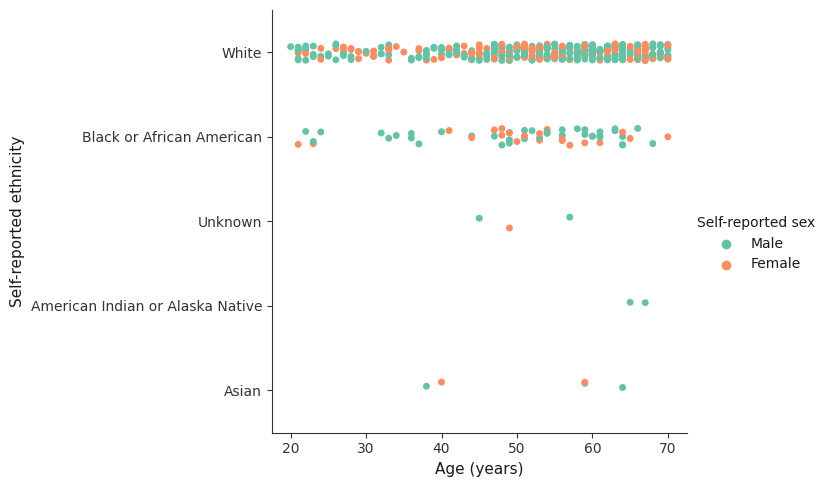

In [122]:
# OLD FIG
sns.catplot(
    data=catdat, x='Age (years)', y='Self-reported ethnicity', hue='Self-reported sex',height=5, aspect=1.5,palette=sns.color_palette("Set2")
)

plt.savefig('./figures/Demographics.pdf')

### Claude glow-up

In [205]:
"""
Figure 1, Panel A -- cohort demographics.

This is the actual figure-generating code (the version that should ship
publicly alongside the manuscript). It expects a real dataframe `catdat`
with (at least) these columns:

    'Age (years)'              float/int
    'Self-reported ethnicity'  str, one row per subject
    'Self-reported sex'        str, one row per subject

Usage (in your own notebook/script, with your real catdat):

    import paper_style as style
    from fig1_panelA_demographics import plot_demographics

    style.apply()
    fig, ax = plot_demographics(catdat)
    fig.savefig("Figure1_PanelA_demographics.pdf", bbox_inches="tight")

See _preview_demographics.py for a smoke test that drives this function
with synthetic placeholder data -- that script is NOT part of the figure
code and should not be published; it exists only so we can iterate on the
look of the panel without the real subject-level data.
"""

from __future__ import annotations

import matplotlib.pyplot as plt
import seaborn as sns

import paper_style as style

DEFAULT_SEX_PALETTE = {
    "Male": style.INK_BLUE,
    "Female": style.TERRACOTTA,
}


def plot_demographics(
    catdat,
    x="Age (years)",
    y="Self-reported ethnicity",
    hue="Self-reported sex",
    order=None,
    hue_order=None,
    palette=None,
    ax=None,
    figsize=(7.2, 4.6),
    point_size=4.0,
    alpha=0.6,
    jitter=0.3,
    edge_linewidth=0.4,
    panel_label=None,
):
    """Recreate the demographics strip plot with house styling applied.

    Statistically identical to the original
    ``sns.catplot(data=catdat, x=x, y=y, hue=hue, ...)`` call (still one
    point per subject, still jittered within each ethnicity row) -- only
    the visual treatment changes:
      - categories ordered by descending sample size (override with `order`)
      - smaller, semi-transparent, thin-white-edged points so the dense
        rows (e.g. "White") read as a soft density instead of a solid blob
      - a fixed two-color, non-default, colorblind-checked palette for sex
      - Helvetica-family type, thin clean spines, outward ticks, no legend
        box
    """
    if order is None:
        order = (
            catdat[y].value_counts().sort_values(ascending=False).index.tolist()
        )

    if palette is None:
        # fall back to the shared 2-color house palette if hue values don't
        # match the Male/Female default mapping
        levels = hue_order or sorted(catdat[hue].dropna().unique().tolist())
        if set(levels) <= set(DEFAULT_SEX_PALETTE):
            palette = DEFAULT_SEX_PALETTE
        else:
            palette = dict(zip(levels, style.PALETTE_2 * (len(levels) // 2 + 1)))

    if ax is None:
        fig, ax = plt.subplots(figsize=figsize)
    else:
        fig = ax.figure

    sns.stripplot(
        data=catdat,
        x=x,
        y=y,
        hue=hue,
        order=order,
        hue_order=hue_order,
        palette=palette,
        dodge=False,
        jitter=jitter,
        size=point_size,
        alpha=alpha,
        linewidth=edge_linewidth,
        edgecolor="white",
        ax=ax,
    )

    ax.set_xlabel(x)
    ax.set_ylabel(y)
    ax.xaxis.grid(True, linewidth=0.5, color="#dddddd", zorder=0)
    ax.set_axisbelow(True)
    style.despine_clean(ax)

    leg = ax.legend(
        title=hue,
        loc="center left",
        bbox_to_anchor=(1.02, 0.5),
        markerscale=1.6,
        handletextpad=0.4,
        borderaxespad=0.0,
    )
    for handle in leg.legend_handles:
        handle.set_alpha(1.0)

    if panel_label:
        ax.text(
            -0.12,
            1.05,
            panel_label,
            transform=ax.transAxes,
            fontsize=14,
            fontweight="bold",
            va="bottom",
            ha="left",
        )

    fig.tight_layout()
    style.despine_clean(ax)
    return fig, ax


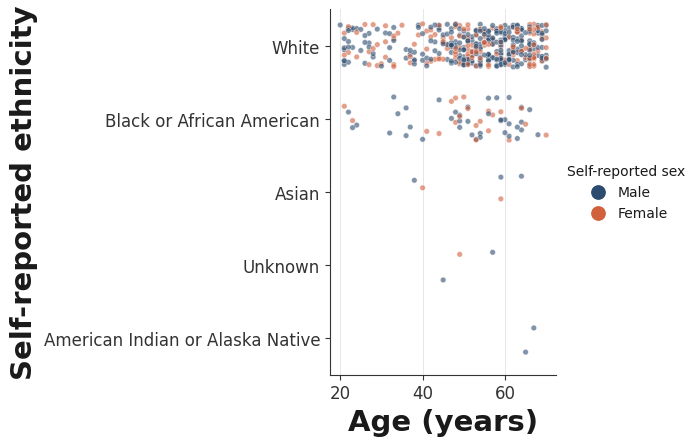

In [206]:
plot_demographics(
    catdat,
    x="Age (years)",
    y="Self-reported ethnicity",
    hue="Self-reported sex",
    order=None,
    hue_order=None,
    palette=None,
    ax=None,
    figsize=(7.2, 4.6),
    point_size=4.0,
    alpha=0.6,
    jitter=0.3,
    edge_linewidth=0.4,
    panel_label=None,
)
plt.savefig('./newfigures/Demographics.pdf',bbox_inches='tight')

## Panel B

In [103]:
catdat=DataDict['Figure1']['GTExData_raw']


In [104]:
quasits=DataDict['Figure1']['GTExData_processed']
quasits.head()

,age,MTND2P28,MTCO1P12,MTATP6P1,NOC2L,ISG15,AGRN,SDF4,B3GALT6,UBE2J2,...,MT-ND4L,MT-ND4,MT-ND5,MT-ND6,MT-CYB,LAMB3,MATR3,ATG5,SIRT1,id
0,20,1180.000000,20.960000,2911.0000,133.100000,79.840000,27.000000,350.1000,45.870000,66.2900,...,13230.000000,26660.000000,4458.000000,3569.00,12700.000000,10.990000,6.951000,24.850000,22.930000,1
1,21,467.877778,52.763333,1548.5000,98.576667,53.655556,32.885556,274.2000,33.184444,43.3300,...,7777.666667,15924.444444,4208.333333,4763.00,9392.444444,8.104889,6.044111,19.973333,17.934444,1
2,22,517.250000,33.343750,1719.7125,97.333750,74.693750,32.478750,308.5125,32.396250,46.1875,...,8081.125000,16877.500000,4482.375000,5022.25,10618.125000,8.117000,6.464250,20.181250,19.343750,1
3,23,474.800000,52.364000,1976.8000,132.624000,54.084000,29.820000,272.5200,37.564000,42.7080,...,9200.200000,18930.000000,4375.400000,5115.40,9509.200000,13.307400,6.791600,21.370000,17.768000,1
4,24,255.950000,45.040000,1390.0000,94.337500,38.240000,52.560000,285.5500,32.700000,32.2975,...,7156.000000,15320.000000,5379.500000,6398.50,8550.500000,6.896250,4.565000,16.952500,15.880000,1


In [109]:
from scipy.ndimage import gaussian_filter1d
smoothed_series = gaussian_filter1d(quasits['COL1A2'].values, sigma=1.5, mode='mirror')


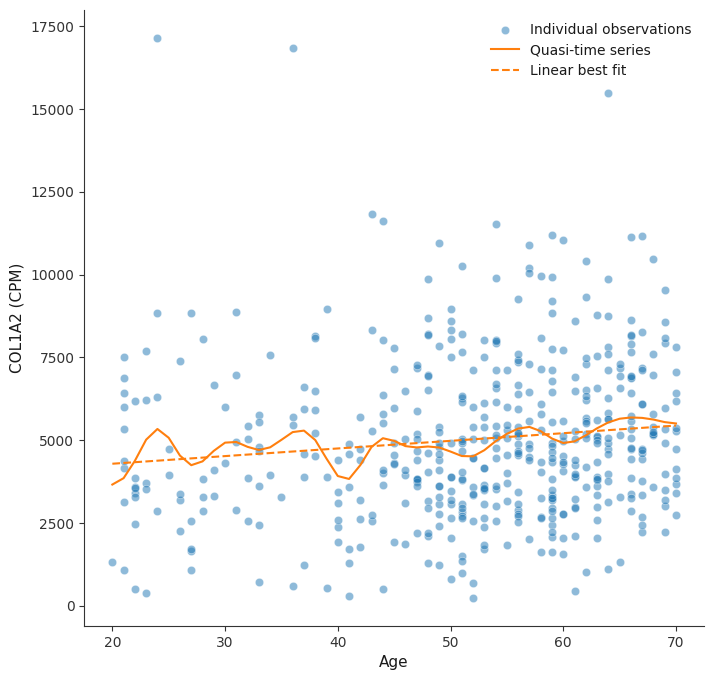

In [112]:
fig,ax=plt.subplots(figsize=(8,8))
sns.scatterplot(data=catdat,x='age',y='COL1A2',alpha=0.5)
plt.plot(quasits.age,smoothed_series,color='C1')
ax.plot(quasits.age,np.poly1d(np.polyfit(quasits.age, quasits.COL1A2, 1))(quasits.age),
        linestyle='--', color='C1')
plt.legend(['Individual observations','Quasi-time series', 'Linear best fit'])
plt.xlabel('Age'); plt.ylabel('COL1A2 (CPM)')
plt.savefig('./figures/QS_COL1A2.pdf')

### Claude glow-up

In [207]:
"""
Figure 1, Panel B -- COL1A2 expression vs. age.

Real figure-generating code (safe to publish). Statistically identical to
the original:

    fig,ax=plt.subplots(figsize=(8,8))
    sns.scatterplot(data=catdat,x='age',y='COL1A2',alpha=0.5)
    plt.plot(quasits.age,smoothed_series,color='C1')
    ax.plot(quasits.age,np.poly1d(np.polyfit(quasits.age, quasits.COL1A2, 1))(quasits.age),
            linestyle='--', color='C1')
    plt.legend(['Individual observations','Quasi-time series', 'Linear best fit'])
    plt.xlabel('Age'); plt.ylabel('COL1A2 (CPM)')

Same inputs (`catdat`, `quasits`, `smoothed_series` -- the smoothed series is
still computed upstream exactly as before, this function doesn't touch that
math), same linear fit via np.polyfit, same three legend entries. Only the
visual treatment changes -- see paper_style.py's usage log for why this
panel uses SLATE + GOLD rather than panel A's ink_blue/terracotta.

Usage:

    import paper_style as style
    from fig1_panelB_col1a2_age import plot_col1a2_vs_age

    style.apply()
    fig, ax = plot_col1a2_vs_age(catdat, quasits, smoothed_series)
    fig.savefig("Figure1_PanelB_COL1A2_age.pdf", bbox_inches="tight")

See _preview_col1a2_age.py for the synthetic-data smoke test (not for
publication).
"""

from __future__ import annotations

import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

import paper_style as style


def plot_col1a2_vs_age(
    catdat,
    quasits,
    smoothed_series,
    x_col="age",
    y_col="COL1A2",
    xlabel="Age (years)",
    ylabel="COL1A2 (CPM)",
    ax=None,
    figsize=(6.2, 5.2),
    point_size=14,
    alpha=0.4,
    point_color=None,
    accent_color=None,
    panel_label=None,
):
    """Recreate the COL1A2-vs-age scatter + quasi-time-series + linear fit.

    point_color defaults to the shared house SLATE (the "raw observations"
    color reused across panels); accent_color defaults to GOLD (this
    panel's assigned accent -- see paper_style.py's usage log) and is used
    for both fit lines, distinguished by linestyle/weight rather than a
    second hue, exactly as in the original.
    """
    point_color = point_color or style.SLATE
    accent_color = accent_color or style.GOLD

    if ax is None:
        fig, ax = plt.subplots(figsize=figsize)
    else:
        fig = ax.figure

    sns.scatterplot(
        data=catdat,
        x=x_col,
        y=y_col,
        color=point_color,
        s=point_size,
        alpha=alpha,
        linewidth=0,
        ax=ax,
    )

    ax.plot(
        quasits[x_col],
        smoothed_series,
        color=accent_color,
        linewidth=2.2,
        solid_capstyle="round",
    )

    linear_fit = np.poly1d(np.polyfit(quasits[x_col], quasits[y_col], 1))(
        quasits[x_col]
    )
    ax.plot(
        quasits[x_col],
        linear_fit,
        color=accent_color,
        linewidth=1.4,
        linestyle="--",
        dashes=(4, 2),
    )

    ax.set_xlabel(xlabel)
    ax.set_ylabel(ylabel)
    ax.yaxis.grid(True, linewidth=0.5, color="#dddddd", zorder=0)
    ax.set_axisbelow(True)
    style.despine_clean(ax)

    ax.legend(
        ["Individual observations", "Quasi-time series", "Linear best fit"],
        loc="upper right",
        handlelength=1.8,
    )

    if panel_label:
        ax.text(
            -0.14,
            1.04,
            panel_label,
            transform=ax.transAxes,
            fontsize=14,
            fontweight="bold",
            va="bottom",
            ha="left",
        )

    fig.tight_layout()
    return fig, ax


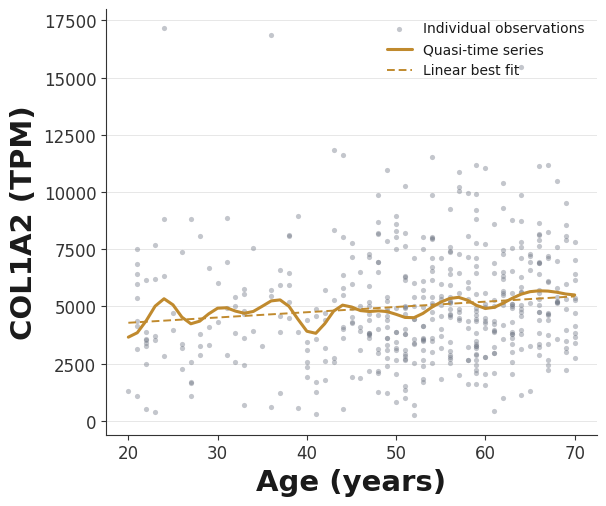

In [230]:
smoothed_series = gaussian_filter1d(quasits['COL1A2'].values, sigma=1.5, mode='mirror')
plot_col1a2_vs_age(
    catdat,
    quasits,
    smoothed_series,
    x_col="age",
    y_col="COL1A2",
    xlabel="Age (years)",
    ylabel="COL1A2 (TPM)",
    ax=None,
    figsize=(6.2, 5.2),
    point_size=14,
    alpha=0.4,
    point_color=None,
    accent_color=None,
    panel_label=None,
)

plt.savefig('./newfigures/Col1A2QuasiTS_smoothed.pdf')

## Panel C

In [115]:
agescores=DataDict['Figure1']['AgeScores']
agescores.head()

MRPS2    -0.025456
INO80    -0.026130
UBE2J2   -0.024477
ILKAP    -0.030504
RBM15B   -0.023139
Name: AgeScore, dtype: float64

These are best-fit slopes to the (interpolated/averaged) quasi-time-series data

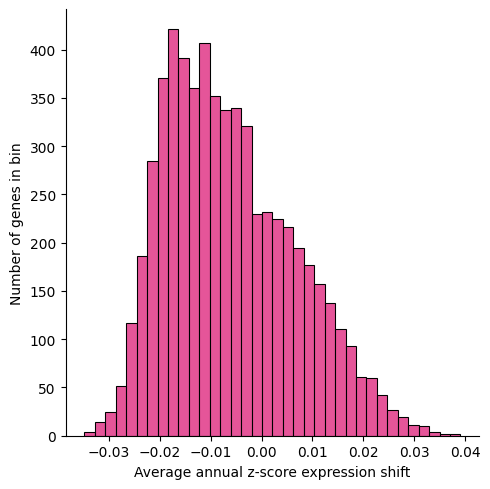

In [10]:
sns.displot(agescores,color='#dd1c77')
plt.ylabel('Number of genes in bin')
plt.xlabel('Average annual z-score expression shift', fontsize=10)
plt.savefig('./figures/AgeScorehist.pdf')

### Claude glow-up

In [210]:
"""
Figure 1, Panel C -- distribution of per-gene age-associated expression
shift ("age score").

Real figure-generating code (safe to publish). Statistically identical to
the original:

    sns.displot(agescores, color='#dd1c77')
    plt.ylabel('Number of genes in bin')
    plt.xlabel('Average annual z-score expression shift', fontsize=10)

Same data, same automatic binning (no bins= override here, so it reproduces
the same bin edges as the original's default). Two additions beyond pure
restyling, both purely visual/orientational and optional (default on):
  - a light KDE overlay on top of the histogram (seaborn computes this from
    the same `agescores` -- it's a smoothed view of the same distribution,
    not new data)
  - a thin dashed reference line at x=0, since the sign of this metric is
    meaningful (genes whose expression rises vs. falls with age) and the
    distribution is visibly skewed negative

Usage:

    import paper_style as style
    from fig1_panelC_agescore_hist import plot_agescore_hist

    style.apply()
    fig, ax = plot_agescore_hist(agescores)
    fig.savefig("Figure1_PanelC_agescore_hist.pdf", bbox_inches="tight")

See _preview_agescore_hist.py for the synthetic-data smoke test (not for
publication).
"""

from __future__ import annotations

import matplotlib.pyplot as plt
import seaborn as sns

import paper_style as style


def plot_agescore_hist(
    agescores,
    xlabel="Average annual z-score expression shift",
    ylabel="Number of genes in bin",
    ax=None,
    figsize=(5.6, 4.6),
    fill_color=None,
    edge_color=None,
    bins=None,
    show_kde=True,
    zero_line=True,
    panel_label=None,
):
    """Recreate the age-score histogram with house styling applied.

    fill_color defaults to the shared house PLUM (this panel's assigned
    accent -- see paper_style.py's usage log); edge_color defaults to a
    darker shade of the same fill rather than flat black.
    """
    fill_color = fill_color or style.PLUM
    edge_color = edge_color or style.darken(fill_color, 0.35)

    if ax is None:
        fig, ax = plt.subplots(figsize=figsize)
    else:
        fig = ax.figure

    sns.histplot(
        agescores,
        bins=bins if bins is not None else "auto",
        color=fill_color,
        edgecolor=edge_color,
        linewidth=0.6,
        kde=show_kde,
        line_kws={"linewidth": 1.6, "color": style.darken(fill_color, 0.55)},
        ax=ax,
    )

    if zero_line:
        ax.axvline(0, color=style.REFERENCE_LINE_COLOR, linestyle="--", linewidth=1.0, zorder=0)

    ax.set_xlabel(xlabel)
    ax.set_ylabel(ylabel)
    ax.yaxis.grid(True, linewidth=0.5, color="#dddddd", zorder=0)
    ax.set_axisbelow(True)
    style.despine_clean(ax)

    if panel_label:
        ax.text(
            -0.16,
            1.04,
            panel_label,
            transform=ax.transAxes,
            fontsize=14,
            fontweight="bold",
            va="bottom",
            ha="left",
        )

    fig.tight_layout()
    return fig, ax


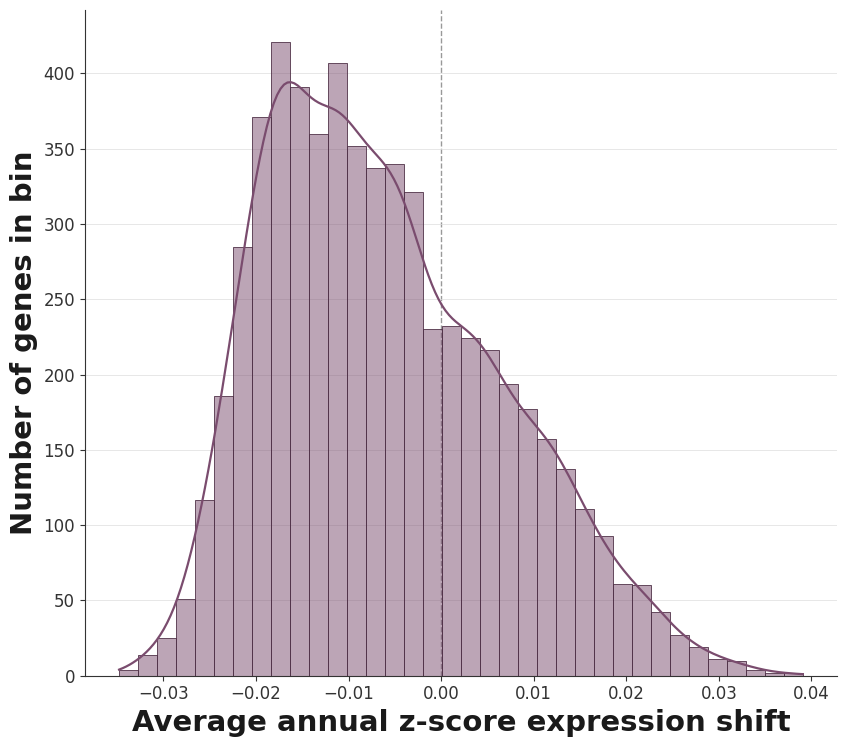

In [213]:
plot_agescore_hist(
    agescores,
    xlabel="Average annual z-score expression shift",
    ylabel="Number of genes in bin",
    ax=None,
    figsize=(8.6, 7.6),
    fill_color=None,
    edge_color=None,
    bins=None,
    show_kde=True,
    zero_line=True,
    panel_label=None,
)

plt.savefig('./newfigures/AgeScorehist.pdf')

## Panel D

In [6]:
quasits=DataDict['Figure1']['GTExData_processed']
quasits.head()

,age,MTND2P28,MTCO1P12,MTATP6P1,NOC2L,ISG15,AGRN,SDF4,B3GALT6,UBE2J2,...,MT-ND4L,MT-ND4,MT-ND5,MT-ND6,MT-CYB,LAMB3,MATR3,ATG5,SIRT1,id
0,20,1180.000000,20.960000,2911.0000,133.100000,79.840000,27.000000,350.1000,45.870000,66.2900,...,13230.000000,26660.000000,4458.000000,3569.00,12700.000000,10.990000,6.951000,24.850000,22.930000,1
1,21,467.877778,52.763333,1548.5000,98.576667,53.655556,32.885556,274.2000,33.184444,43.3300,...,7777.666667,15924.444444,4208.333333,4763.00,9392.444444,8.104889,6.044111,19.973333,17.934444,1
2,22,517.250000,33.343750,1719.7125,97.333750,74.693750,32.478750,308.5125,32.396250,46.1875,...,8081.125000,16877.500000,4482.375000,5022.25,10618.125000,8.117000,6.464250,20.181250,19.343750,1
3,23,474.800000,52.364000,1976.8000,132.624000,54.084000,29.820000,272.5200,37.564000,42.7080,...,9200.200000,18930.000000,4375.400000,5115.40,9509.200000,13.307400,6.791600,21.370000,17.768000,1
4,24,255.950000,45.040000,1390.0000,94.337500,38.240000,52.560000,285.5500,32.700000,32.2975,...,7156.000000,15320.000000,5379.500000,6398.50,8550.500000,6.896250,4.565000,16.952500,15.880000,1


This figure needs some key methods from CCM. A fuller explanation can be found in the accompanying DemonstrateKeyMethods.ipynb

In [6]:
def shadowManifold(X, E, tau=1):
    # This makes a "shadow manifold", an E-dimensional delay-embedding of X:
    
    return [X[np.arange(i, i - (E - 1) * tau - 1, -tau)] for i in np.arange(0 + (E - 1) * tau, len(X))]

def makeKDtree(df,genelist):
    # CCM can be significantly accelerated by building trees ahead of time and holding them in storage rather than memory
    BigDict={}
    for gene in genelist:
        BigDict[gene]={}
        for EE in [3,4,5,6,7,8,9,10]:
            x_data=np.array(df[gene].values)
            x_data+=np.random.rand(len(x_data))*0.001*np.abs(np.min(x_data))
            shadow_M_X = shadowManifold(x_data, int(EE), 1)
            shadow_kdtree = cKDTree(shadow_M_X, leafsize=10)
            dist, ind = shadow_kdtree.query(shadow_M_X, k=int(len(shadow_M_X)))
            BigDict[gene][EE]=[dist,ind,shadow_kdtree]
    return BigDict
    
def generateYApprox(BigDict, Xname, Ydata, E):
   
    dists=BigDict[Xname][E][0]
    inds=BigDict[Xname][E][1]

    dist_neigh, Y_neigh = [], []
    mask_ceiling=len(Ydata)
    #for zz in range(mask_ceiling):
    for zz in range(mask_ceiling-E+1):

        dist_neigh.append(list(dists[zz,:][np.where(inds[zz,:]<mask_ceiling)][1:E+1]))
        Y_neigh.append(list(Ydata[inds[zz,:][np.where(inds[zz,:]<mask_ceiling)][1:E+1]]))
       

    Y_neigh=np.array(Y_neigh)
    dist_neigh=np.array(dist_neigh)

    # weights
    u = np.exp(-dist_neigh / dist_neigh[:, 0][:, None])
    u /= u.sum(axis=1)[:, None]

    Y_tilde = np.sum(u*Y_neigh, axis=1)
    return Y_tilde

In [48]:
outtree=makeKDtree(quasits,['COL1A2','FN1'])

In [51]:
Y_tilde=generateYApprox(outtree,'FN1',quasits['COL1A2'],3)

In [52]:
stats.pearsonr(Y_tilde,quasits['COL1A2'][0:len(Y_tilde)])

PearsonRResult(statistic=0.6261479308432307, pvalue=1.4954740035496826e-06)

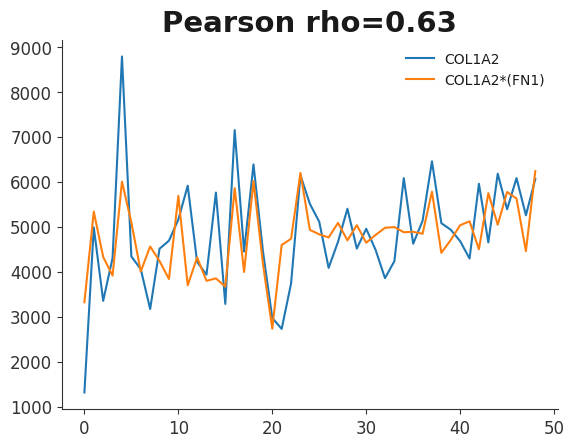

In [243]:
plt.plot(quasits['COL1A2'][0:len(Y_tilde)])
plt.plot(Y_tilde)

plt.title('Pearson rho=0.63')
plt.legend(['COL1A2','COL1A2*(FN1)'])
plt.savefig('./figures/COL1A2viaFN1.pdf')

### Claude glow-up

In [248]:
"""
Figure 1, Panel D (right) -- COL1A2 vs. its cross-mapped reconstruction
from FN1.

Real figure-generating code (safe to publish). Same underlying comparison
as the original:

    plt.plot(quasits['COL1A2'][0:len(Y_tilde)])
    plt.plot(Y_tilde)
    plt.title('Pearson rho=0.63')
    plt.legend(['COL1A2','COL1A2*(FN1)'])

More changes:

  1. The Pearson rho is now COMPUTED from the two arrays (scipy.stats.
     pearsonr) rather than hardcoded as a title string. The original code's
     'Pearson rho=0.63' was a literal string -- if that 0.63 was copied over
     from the old COL3A1/ACTN1 panel rather than recomputed for the new
     COL1A2/FN1 pair, it would be silently wrong in a published figure.
     Pass rho= explicitly only if you already have a trusted precomputed
     value and want to skip the recomputation.
  2. The asterisk in the legend is superscripted via mathtext
     (COL1A2$^{*}$(FN1)), matching paper_style's mathtext font setup so it
     renders in the same sans face as everything else instead of
     matplotlib's default serif math font.

Usage:

    import paper_style as style
    from fig1_panelD_right_col1a2_via_fn1 import plot_cross_map_comparison

    style.apply()
    fig, ax = plot_cross_map_comparison(quasits, Y_tilde)
    fig.savefig("Figure1_PanelD_right_COL1A2_via_FN1.pdf", bbox_inches="tight")

See _preview_col1a2_via_fn1.py for the synthetic-data smoke test (not for
publication).
"""

from __future__ import annotations

import matplotlib.pyplot as plt
from scipy.stats import pearsonr

import paper_style as style


def plot_cross_map_comparison(
    quasits,
    y_tilde,
    gene="COL1A2",
    via_gene="FN1",
    xlabel="Quasi-time index",
    ylabel=None,
    ax=None,
    figsize=(5.4, 4.4),
    color_observed=None,
    color_reconstructed=None,
    rho=None,
    panel_label=None,
):
    """Recreate the COL1A2-vs-cross-mapped-reconstruction comparison.

    color_observed/color_reconstructed default to this panel's assigned
    pair, MOSS (observed) + VIOLET (reconstruction) -- see paper_style.py's
    usage log. (Originally MOSS + INDIGO; swapped to VIOLET because that
    pair read as "too similar" -- moss and indigo differ in hue but are
    nearly identical in lightness, so violet was picked instead for a much
    larger lightness gap while keeping the same muted saturation level;
    see the VIOLET comment in paper_style.py for the full rationale.) rho
    is computed from (observed, y_tilde) with scipy.stats.pearsonr unless
    you pass a trusted value explicitly.
    """
    color_observed = color_observed or style.MOSS
    color_reconstructed = color_reconstructed or style.VIOLET
    ylabel = ylabel or f"{gene} (TPM)"

    observed = quasits[gene].to_numpy()[: len(y_tilde)]

    if rho is None:
        rho = pearsonr(observed, y_tilde)[0]

    if ax is None:
        fig, ax = plt.subplots(figsize=figsize)
    else:
        fig = ax.figure

    ax.plot(quasits['age'][0:len(observed)],observed, color=color_observed, linewidth=1.8, label=gene)
    ax.plot(quasits['age'][0:len(observed)],
        y_tilde,
        color=color_reconstructed,
        linewidth=1.5,
        label=rf"{gene}$^{{*}}$({via_gene})",
    )

    ax.set_title(rf"Pearson $\rho$ = {rho:.2f}")
    ax.set_xlabel(xlabel)
    ax.set_ylabel(ylabel)
    ax.yaxis.grid(True, linewidth=0.5, color="#dddddd", zorder=0)
    ax.set_axisbelow(True)
    style.despine_clean(ax)

    ax.legend(loc="upper right", handlelength=1.8)

    if panel_label:
        ax.text(
            -0.16,
            1.04,
            panel_label,
            transform=ax.transAxes,
            fontsize=14,
            fontweight="bold",
            va="bottom",
            ha="left",
        )

    fig.tight_layout()
    return fig, ax


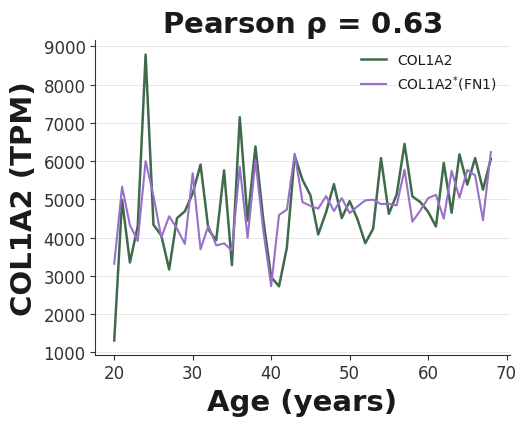

In [250]:
plot_cross_map_comparison(
    quasits,
    Y_tilde,
    gene="COL1A2",
    via_gene="FN1",
    xlabel="Age (years)",
    ylabel=None,
    ax=None,
    figsize=(5.4, 4.4),
    color_observed=None,
    color_reconstructed=None,
    rho=None,
    panel_label=None,
)
plt.savefig('./newfigures/COL1A2_via_FN1.pdf',bbox_inches='tight')

In [54]:
COLSM=shadowManifold(quasits['COL1A2'],3)
FNSM=shadowManifold(quasits['FN1'],3)

In [219]:
COLSM[0]

2    3350.612500
1    4984.111111
0    1312.000000
Name: COL1A2, dtype: float64

In [218]:
COLSM[0].iloc[-1]

1312.0

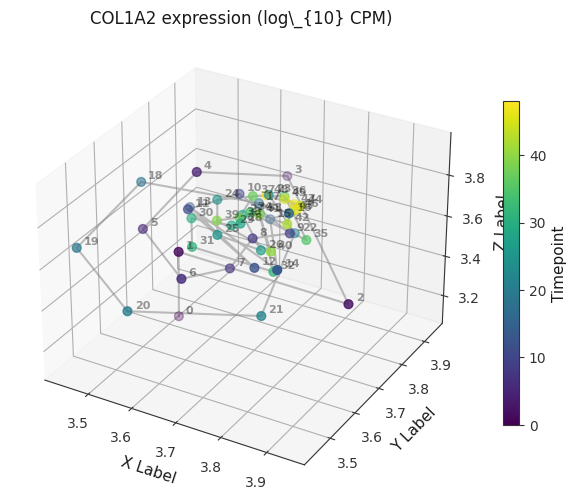

In [87]:
fig = plt.figure(figsize=(8, 6))
ax = fig.add_subplot(projection='3d')

# 2. Generate random 3D data
x_raw = [i.iloc[0] for i in COLSM]
y_raw = [i.iloc[1] for i in COLSM]
z_raw = [i.iloc[2] for i in COLSM]
time_index=np.arange(len(x_raw))

# --- WORKAROUND: Manually log-transform the data ---
x = np.log10(x_raw)
y = np.log10(y_raw)
z = np.log10(z_raw)

# 3. Create the 3D scatter plot
ax.plot(x, y, z, color='gray', alpha=0.5, linestyle='-', linewidth=1.5, zorder=1)
sc = ax.scatter(x, y, z, c=time_index, cmap='viridis', s=40,zorder=2)


# 4. Add labels and color bar
ax.set_xlabel('X Label')
ax.set_ylabel('Y Label')
ax.set_zlabel('Z Label')
ax.set_title('COL1A2 expression (log\_{10} CPM)')
fig.colorbar(sc, label='Timepoint', shrink=0.7)
#ax.view_init(elev=30, azim=45)

# --- NEW: Add time index numbers next to points ---
# Adjust 'stride' to avoid overlapping. 'stride=5' labels every 5th point.
stride = 1
for i in range(0, len(time_index), stride):
    # ax.text(x, y, z, text_string)
    # Adding a slight offset to x, y, z coordinates so the text doesn't sit directly on the dot
    ax.text(
        x[i] + 0.01, 
        y[i] + 0.01, 
        z[i] + 0.01, 
        str(time_index[i]), 
        fontsize=8, 
        color='black', 
        alpha=0.4,
        weight='bold'
    )
plt.savefig('./figures/SM_COL1A2.pdf')
plt.show()

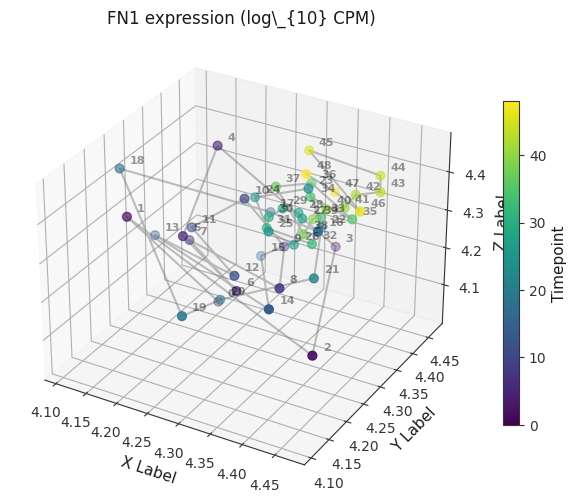

In [89]:
fig = plt.figure(figsize=(8, 6))
ax = fig.add_subplot(projection='3d')

# 2. Generate random 3D data
x_raw = [i.iloc[0] for i in FNSM]
y_raw = [i.iloc[1] for i in FNSM]
z_raw = [i.iloc[2] for i in FNSM]
time_index=np.arange(len(x))

# --- WORKAROUND: Manually log-transform the data ---
x = np.log10(x_raw)
y = np.log10(y_raw)
z = np.log10(z_raw)

# 3. Create the 3D scatter plot
ax.plot(x, y, z, color='gray', alpha=0.5, linestyle='-', linewidth=1.5, zorder=1)
sc = ax.scatter(x, y, z, c=time_index, cmap='viridis', s=40,zorder=2)


# 4. Add labels and color bar
ax.set_xlabel('X Label')
ax.set_ylabel('Y Label')
ax.set_zlabel('Z Label')
ax.set_title('FN1 expression (log\_{10} CPM)')
fig.colorbar(sc, label='Timepoint', shrink=0.7)
#ax.view_init(elev=30, azim=45)

# --- NEW: Add time index numbers next to points ---
# Adjust 'stride' to avoid overlapping. 'stride=5' labels every 5th point.
stride = 1
for i in range(0, len(time_index), stride):
    # ax.text(x, y, z, text_string)
    # Adding a slight offset to x, y, z coordinates so the text doesn't sit directly on the dot
    ax.text(
        x[i] + 0.01, 
        y[i] + 0.01, 
        z[i] + 0.01, 
        str(time_index[i]), 
        fontsize=8, 
        color='black', 
        alpha=0.4,
        weight='bold'
    )

plt.savefig('./figures/SM_FN1.pdf')
plt.show()

In [261]:
"""
Figure 1, Panel D (left) and (middle) -- 3D delay embeddings of a single
gene's quasi-time series, with a red ring (and, optionally, a second,
differently-colored/dashed ring) marking spatially-close clusters of
timepoints that correspond between the two panels.

Real figure-generating code (safe to publish). Both panels are generated by
the SAME function below, called once per gene (COL1A2 for D_left, FN1 for
D_middle) -- the original ad hoc version we were given was, likewise,
"virtually identical code" copy-pasted per gene:

    fig = plt.figure(figsize=(8, 6))
    ax = fig.add_subplot(projection='3d')
    x_raw = [i.iloc[0] for i in COLSM]
    y_raw = [i.iloc[1] for i in COLSM]
    z_raw = [i.iloc[2] for i in COLSM]
    time_index = np.arange(len(x_raw))
    x = np.log10(x_raw); y = np.log10(y_raw); z = np.log10(z_raw)
    ax.plot(x, y, z, color='gray', alpha=0.5, linestyle='-', linewidth=1.5, zorder=1)
    sc = ax.scatter(x, y, z, c=time_index, cmap='viridis', s=40, zorder=2)
    ax.set_xlabel('X Label'); ax.set_ylabel('Y Label'); ax.set_zlabel('Z Label')
    ax.set_title('COL1A2 expression (log\\_{10} CPM)')
    fig.colorbar(sc, label='Timepoint', shrink=0.7)
    for i in range(0, len(time_index), 1):
        ax.text(x[i]+0.01, y[i]+0.01, z[i]+0.01, str(time_index[i]),
                 fontsize=8, color='black', alpha=0.4, weight='bold')

Changes beyond restyling (each flagged because it changes what the figure
actually says, not just how it looks):

  1. Time-index labeling. The raw version's `time_index = np.arange(len(x_raw))`
     labels points 0..N-1 by their ROW position, not by the actual quasi-time
     index t of F(t) -- but a delay embedding of (F(t), F(t-1), F(t-2)) can
     only start once t>=2 (there's no F(-1)/F(-2) to embed t=0 or t=1 with).
     This version labels each embedded point by its real t (t = 2 .. len(series)-1),
     matching how every other panel in this project refers to quasi-time
     index (e.g. fig1_panelD_right's "Quasi-time index" x-axis), and --
     more importantly -- so a timepoint number here means the same thing as
     that same number in fig1_panelD_right, and so the D_left/D_middle
     panels' shared cluster indices actually refer to the same real
     timepoints rather than two different re-numbered index systems.
  2. The `log\\_{10}` in the raw title string doesn't render as anything
     sensible (an unescaped backslash isn't valid mathtext) -- fixed to
     proper mathtext, `$\\log_{10}$`.
  3. The ring(s) marking corresponding cluster(s): not present in the raw
     scatter-only version we were given (that was traced by hand in
     Inkscape for the original full panel D). Added here via
     `style.highlight_ring_3d`, driven by an explicit `clusters` list you
     choose, so the correspondence is drawn programmatically and
     reproducibly instead of by hand -- see that function's docstring for
     how each ring is built to look correct from a specific (elev, azim),
     and for how its sizing (`pad` / `extra_margin_frac`) is chosen so the
     ring clears the marker dots and time-index labels rather than cutting
     through them.
  4. Orthographic 3D projection (`ax.set_proj_type('ortho')`) instead of
     mplot3d's default perspective projection. Matters here specifically
     because the whole point of these two panels is showing that a set of
     points forms a genuinely tight SPATIAL cluster -- a perspective
     projection can make points look more or less clustered purely as a
     function of their distance from the camera, which would misrepresent
     exactly the thing being illustrated. `style.highlight_ring_3d`'s ring
     math also assumes this (see its docstring).

Usage (same pattern as every other panel in this project):

    import paper_style as style
    from fig1_panelD_leftmiddle_delay_embedding import plot_delay_embedding

    style.apply()

    clusters = [
        {"timepoints": [3, 7, 8, 13, 20]},  # solid HIGHLIGHT_RING_COLOR by default
        {"timepoints": [5, 11, 17, 19, 24],
         "color": style.HIGHLIGHT_RING_COLOR_ALT, "linestyle": "dashed"},
    ]

    fig, ax = plot_delay_embedding(
        quasits["COL1A2"], gene="COL1A2", elev=0, azim=137,
        clusters=clusters, panel_label="D",
    )
    fig.savefig("Figure1_PanelD_left_COL1A2_embedding.pdf", bbox_inches="tight")

    fig, ax = plot_delay_embedding(
        quasits["FN1"], gene="FN1", elev=27.5, azim=183.5, clusters=clusters,
    )
    fig.savefig("Figure1_PanelD_middle_FN1_embedding.pdf", bbox_inches="tight")

`clusters`, `elev`, and `azim` are deliberately real, chosen-by-you
arguments rather than baked-in defaults -- which timepoints form a good,
cleanly-separable cluster and which viewing angle best shows it (or them)
off are genuinely data-dependent questions (see the project style-guidelines
note on this panel for how these particular numbers were picked). Pass one
dict in `clusters` for a single ring, or several for multiple -- each dict's
`color`/`linestyle` default to HIGHLIGHT_RING_COLOR/"solid" if omitted, so
give the second (and any further) cluster an explicit override or they'll
all render identically. The two panels don't have to share the same
`elev`/`azim`, or the same `clusters`, if a different view/cluster set
happens to separate one gene's embedding better than the other's -- see the
module docstring of style.highlight_ring_3d.

See _preview_delay_embedding.py for the synthetic-data smoke test (not for
publication).
"""

from __future__ import annotations

import numpy as np

import paper_style as style


def plot_delay_embedding(
    series,
    gene,
    elev,
    azim,
    clusters,
    ax=None,
    figsize=(7.6, 6.2),
    point_size=45,
    label_fontsize=8,
    label_color="#333333",
    label_alpha=0.55,
    ring_pad=1.5,
    ring_extra_margin_frac=0.10,
    panel_label=None,
):
    """Recreate the log10 3D delay embedding of one gene's quasi-time series,
    with one ring per entry of `clusters` drawn to look clean from (`elev`,
    `azim`) -- see module docstring for what changed vs. the raw version and
    why.

    `series` is the raw (non-log) expression values in quasi-time order,
    index 0..len(series)-1 (e.g. `quasits[gene]`). Colors/labels each
    embedded point by its real quasi-time index t (t=2..len(series)-1, since
    a (F(t), F(t-1), F(t-2)) embedding needs two prior points to exist).

    `clusters` is a list of dicts, one per ring to draw, each:
        {"timepoints": [...], "color": <optional>, "linestyle": <optional>}
    `timepoints` are real quasi-time indices t to ring (must be a subset of
    the valid range above); `color`/`linestyle` default to
    HIGHLIGHT_RING_COLOR/"solid" for the first cluster missing them and
    should be overridden explicitly for any additional cluster (e.g.
    HIGHLIGHT_RING_COLOR_ALT/"dashed") so multiple rings stay visually and
    redundantly (color + linestyle) distinct -- see highlight_ring_3d.
    """
    values = np.asarray(series, dtype=float)
    log_values = np.log10(values)

    t = np.arange(2, len(log_values))
    embedding = np.column_stack([log_values[t], log_values[t - 1], log_values[t - 2]])

    if ax is None:
        import matplotlib.pyplot as plt

        fig = plt.figure(figsize=figsize)
        ax = fig.add_subplot(projection="3d")
    else:
        fig = ax.figure
    ax.set_proj_type("ortho")

    ax.plot(
        embedding[:, 0],
        embedding[:, 1],
        embedding[:, 2],
        color=style.SLATE,
        alpha=0.45,
        linewidth=1.3,
        zorder=1,
    )

    cmap = style.sequential_multihue_cmap()
    sc = ax.scatter(
        embedding[:, 0],
        embedding[:, 1],
        embedding[:, 2],
        c=quasits['age'].values[2:],
        cmap=cmap,
        s=point_size,
        edgecolors="white",
        linewidths=0.4,
        zorder=2,
    )

    for i, ti in enumerate(quasits['age'].values[2:]):
        ax.text(
            embedding[i, 0] + 0.01,
            embedding[i, 1] + 0.01,
            embedding[i, 2] + 0.01,
            str(ti),
            fontsize=label_fontsize,
            color=label_color,
            alpha=label_alpha,
            weight="bold",
            zorder=3,
        )

    ax.set_xlabel(f"{gene}(t)")
    ax.set_ylabel(f"{gene}(t-1)")
    ax.set_zlabel(f"{gene}(t-2)")
    ax.set_title(rf"{gene} expression ($\log_{{10}}$ TPM)")

    style.clean_3d_axes(ax)

    cbar = fig.colorbar(sc, ax=ax, shrink=0.65, pad=0.13)
    cbar.set_label("Age (years)")
    cbar.outline.set_linewidth(0.8)

    ax.view_init(elev=elev, azim=azim)

    default_color = style.HIGHLIGHT_RING_COLOR
    default_linestyle = "solid"
    for spec in clusters:
        cluster_mask = np.isin(t, list(spec["timepoints"]))
        style.highlight_ring_3d(
            ax,
            embedding,
            cluster_mask,
            elev=elev,
            azim=azim,
            pad=ring_pad,
            extra_margin_frac=ring_extra_margin_frac,
            color=spec.get("color", default_color),
            linestyle=spec.get("linestyle", default_linestyle),
        )

    if panel_label:
        ax.text2D(
            -0.08,
            1.02,
            panel_label,
            transform=ax.transAxes,
            fontsize=14,
            fontweight="bold",
            va="bottom",
            ha="left",
        )

    fig.tight_layout()
    return fig, ax


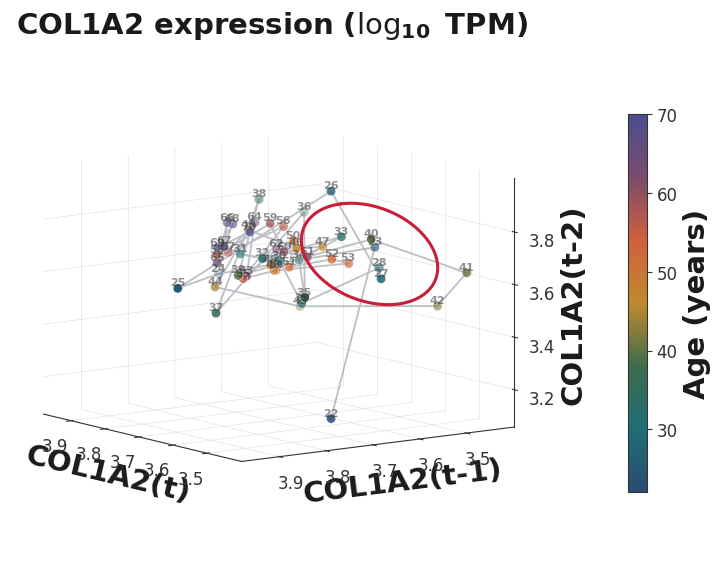

In [262]:
clusters = [{"timepoints": [3, 7, 8, 13, 20]}]
plot_delay_embedding(
    quasits["COL1A2"], gene="COL1A2", elev=10, azim=144,
    clusters=clusters, panel_label="",
)
plt.savefig('./newfigures/SM_COL1A2.pdf',bbox_inches='tight')

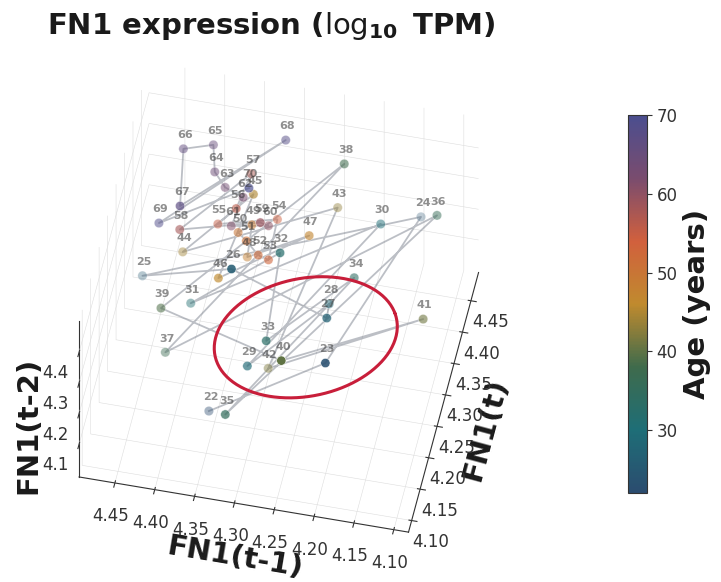

In [263]:
plot_delay_embedding(
    quasits["FN1"], gene="FN1", elev=52, azim=192,
    clusters=clusters,
)
plt.savefig('./newfigures/SM_FN1.pdf',bbox_inches='tight')

## Panel F

In [224]:
BiogridAnnot=DataDict['Figure1']['Biogrid']
BiogridAnnot.head()

,Gene 1,Gene 2,NumberLitRefs
0,ANXA2,MORF4L2,1
1,ANXA2,IL10RB,0
2,ANXA2,PRDX4,2
3,ANXA2,ACOT9,0
4,ANXA2,MTHFD1,0


In [225]:
RawAnnot=BiogridAnnot.NumberLitRefs.values

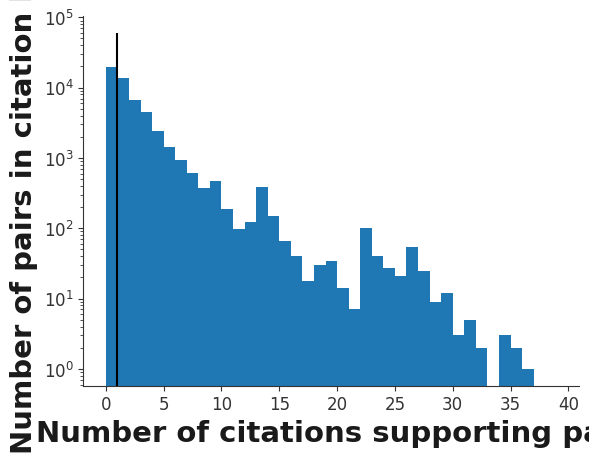

In [226]:
plt.hist(RawAnnot,bins=range(0,40),log=True)
plt.xlabel('Number of citations supporting pair')
plt.ylabel('Number of pairs in citation bin')
plt.vlines(1,0,60000, color='k')

plt.savefig('./figures/BiogridFig.pdf')

### Claude glow-up

In [227]:
"""
Figure 1, Panel E -- BioGRID citation support per interaction pair.

Real figure-generating code (safe to publish). Statistically identical to
the original:

    plt.hist(RawAnnot, bins=range(0,40), log=True)
    plt.xlabel('Number of citations supporting pair')
    plt.ylabel('Number of pairs in citation bin')
    plt.vlines(1, 0, 60000, color='k')

Same data, same integer bin edges (bins=range(0,40)), same log-scaled
y-axis, same reference line at x=1. Only the visual treatment changes.

Usage:

    import paper_style as style
    from fig1_panelE_biogrid_citations import plot_citation_hist

    style.apply()
    fig, ax = plot_citation_hist(RawAnnot)
    fig.savefig("Figure1_PanelE_biogrid_citations.pdf", bbox_inches="tight")

See _preview_biogrid_citations.py for the synthetic-data smoke test (not
for publication).
"""

from __future__ import annotations

import matplotlib.pyplot as plt

import paper_style as style


def plot_citation_hist(
    raw_annot,
    bins=None,
    xlabel="Number of citations supporting pair",
    ylabel="Number of pairs in citation bin",
    ax=None,
    figsize=(5.8, 4.6),
    fill_color=None,
    edge_color=None,
    threshold=1,
    threshold_label=None,
    panel_label=None,
):
    """Recreate the BioGRID citations-per-pair histogram with house styling.

    fill_color defaults to the shared house TEAL (this panel's assigned
    accent -- see paper_style.py's usage log). The x=1 cutoff is drawn as
    the shared neutral REFERENCE_LINE_COLOR (dashed), matching the
    convention used for the zero-line in panel C: accent colors carry data,
    gray dashed lines carry reference/threshold annotations, consistently
    across every panel.
    """
    fill_color = fill_color or style.TEAL
    edge_color = edge_color or style.darken(fill_color, 0.35)
    bins = bins if bins is not None else range(0, 40)

    if ax is None:
        fig, ax = plt.subplots(figsize=figsize)
    else:
        fig = ax.figure

    ax.hist(
        raw_annot,
        bins=bins,
        log=True,
        color=fill_color,
        edgecolor=edge_color,
        linewidth=0.5,
    )

    if threshold is not None:
        ax.axvline(
            threshold,
            color=style.REFERENCE_LINE_COLOR,
            linestyle="--",
            linewidth=1.2,
            zorder=3,
        )
        if threshold_label:
            ax.annotate(
                threshold_label,
                xy=(threshold, 1),
                xytext=(threshold + 0.6, 3),
                fontsize=9,
                color=style.REFERENCE_LINE_COLOR,
            )

    ax.set_xlabel(xlabel)
    ax.set_ylabel(ylabel)
    ax.yaxis.grid(True, which="major", linewidth=0.5, color="#dddddd", zorder=0)
    ax.set_axisbelow(True)
    style.despine_clean(ax)

    if panel_label:
        ax.text(
            -0.16,
            1.04,
            panel_label,
            transform=ax.transAxes,
            fontsize=14,
            fontweight="bold",
            va="bottom",
            ha="left",
        )

    fig.tight_layout()
    return fig, ax


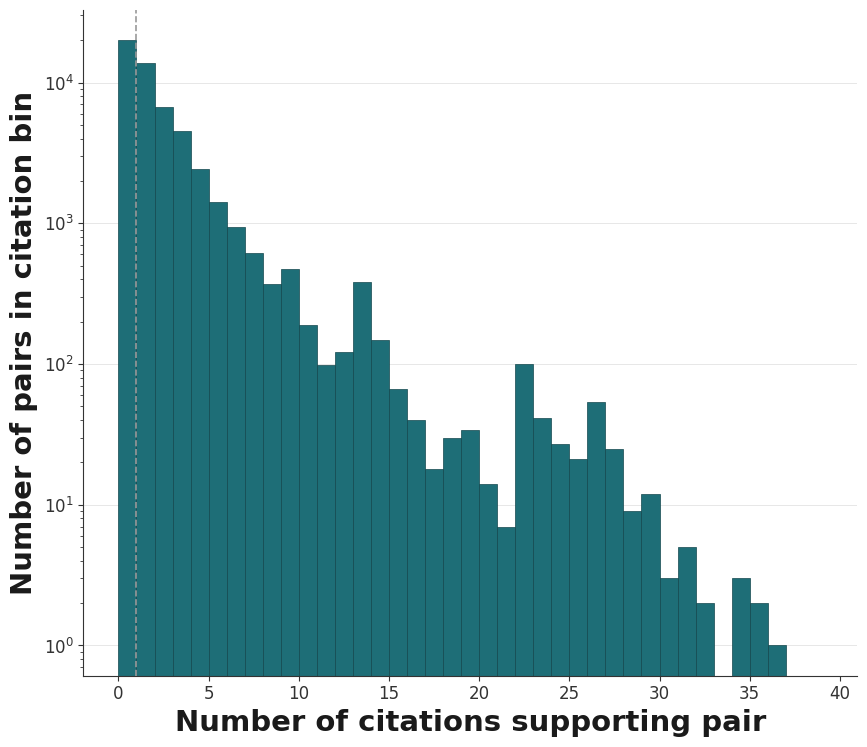

In [229]:
plot_citation_hist(
    RawAnnot,
    bins=None,
    xlabel="Number of citations supporting pair",
    ylabel="Number of pairs in citation bin",
    ax=None,
    figsize=(8.8, 7.6),
    fill_color=None,
    edge_color=None,
    threshold=1,
    threshold_label=None,
    panel_label=None,
)
plt.savefig('./newfigures/BiogridAnnot.pdf')

# Figure 2

Panel B was made in Inkscape. Figures 2, 3, and 4 use an (admittedly slightly Byzantine) color-labeling scheme to compress information about the gene's expression trajectory over time and some basic ontological sorting, which requires the following line(s):

In [264]:
with open('LibLabelDict.pkl','rb') as test:
    liblabeldict=pickle.load(test)
liblabeldict.keys()

dict_keys(['color', 'tritile'])

In [265]:
# fix liblabel tritile
lld={}
for key in liblabeldict['tritile'].keys():
    if liblabeldict['tritile'][key]=='_ ':
        lld[key]='- '
    else:
        lld[key]=liblabeldict['tritile'][key]
lld['OLD']=''; lld['YOUNG']=''
lld['P16']='C '; lld['DNAJB12']='/ '; lld['C5ORF24']='- '; lld['NFIX']='- '; lld['MARK3']='/ '
lld['YARS']='/ '; lld['DDX49']='/ '; lld['H3-M']='C '; lld['CDC42EP3']='- '; lld['C6ORF106']='/ '
lld['SIRT6']='C '; lld['HNRNPK']='/ '; lld['C12ORF10']='- '; lld['GABARAP']='\\ '; lld['USO1']='\\ '
lld['TEX261']='- '; lld['EFTUD2']='/ '; lld['FADD']='_ '
liblabeldict['tritile']=lld


liblabeldict['color']['OLD']='k'; liblabeldict['color']['YOUNG']='k'
liblabeldict['color']['P16']='k'; liblabeldict['color']['DNAJB12']='k'; liblabeldict['color']['C5ORF24']='k'; liblabeldict['color']['NFIX']='k'; liblabeldict['color']['MARK3']='k'
liblabeldict['color']['YARS']='k'; liblabeldict['color']['DDX49']='k'; liblabeldict['color']['H3-M']='k'; liblabeldict['color']['CDC42EP3']='k'; liblabeldict['color']['C6ORF106']='k'
liblabeldict['color']['SIRT6']='k'; liblabeldict['color']['HNRNPK']='k'; liblabeldict['color']['C12ORF10']='k'; liblabeldict['color']['GABARAP']='k'; liblabeldict['color']['USO1']='k'
liblabeldict['color']['TEX261']='k'; liblabeldict['color']['EFTUD2']='k'; liblabeldict['color']['FADD']='k'

## Panel A

In [266]:
DataDict['Figure2'].keys()

dict_keys(['RankScores_and_Other_Gene_Info', 'Adata_Obs', 'Adata_UMAP', 'Edglist', 'ComparativeNetworkStatistics', 'ComparandaPrecisions', 'DEdict'])

In [267]:
sumdf_total=DataDict['Figure2']['RankScores_and_Other_Gene_Info']
sumdf_total.head()

,Gene,RNAYS,RNA_AbFrac,YouthScore_Hybrid,MasterScore,MeanMito%,StdMito%,MeanRibo%,StdRibo%,MeanMalat%,...,NumNeither,OddsRatio,pvals,scRNA_cellcount,Master Score tritile,TF/surface marker/secreted factor,Reactome: Cellular responses to stimuli,Reactome: Intracellular core functions,Reactome: Immune system,CellCountCP
0,ANXA2,0.236025,0.069364,0.180877,-0.021485,1.625959,0.573768,0.944102,0.313470,2.361226,...,3816.0,1.645974,1.131976e-07,519.0,control,Secreted Factor,0.0,0.0,0.0,1665.0
1,OLD,0.247183,0.067234,0.145214,NaN,1.246700,0.438352,1.075207,0.388175,2.029116,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,139533.0
2,YOUNG,0.767124,0.071813,0.885398,NaN,1.318644,0.543593,1.146731,0.407127,2.057075,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,41162.0
3,TP53,0.336058,0.084910,0.181916,0.000367,1.583803,0.672274,1.184535,0.390952,1.508459,...,2010.0,0.819962,7.438840e-01,2273.0,control,Transcription Factor,0.0,0.0,0.0,3791.0
4,MRPS2,0.204873,0.059401,0.089199,0.239430,1.072958,0.924759,1.112192,0.428831,1.800366,...,1641.0,0.791076,9.970685e-01,2138.0,negative,NaN,0.0,1.0,0.0,1883.0


What we call RankScore in the paper was originally called MasterScore, which we felt deserved renaming

In [275]:
sumdf=sumdf_total[~sumdf_total['MasterScore'].isna()]
sumdf['RankScore']=sumdf['MasterScore']

<ipython-input-275-088090967ebd>:2: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  sumdf['RankScore']=sumdf['MasterScore']


<ipython-input-276-29d15f40d6e1>:8: UserWarning: FixedFormatter should only be used together with FixedLocator
  ax.set_xticklabels(newlabels)


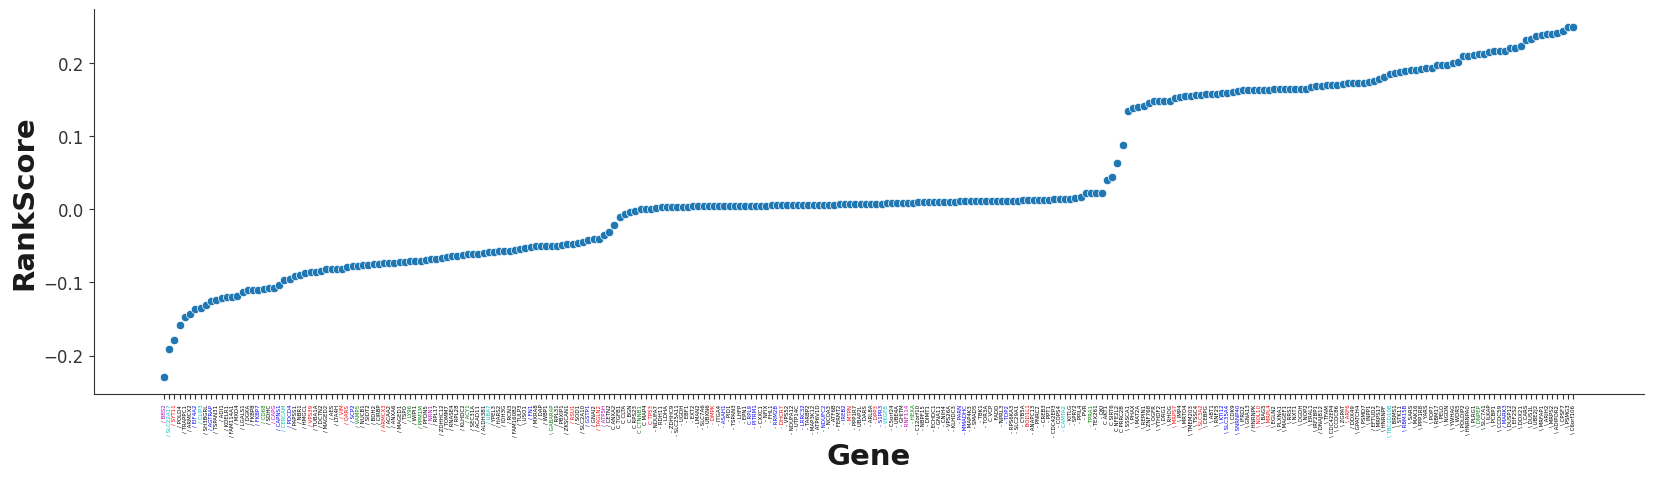

In [276]:
fig,ax=plt.subplots(figsize=(20,5))
sns.scatterplot(data=sumdf.sort_values('RankScore'),x='Gene',y='RankScore')
plt.xticks(rotation=90,fontsize=4);

labels = [item.get_text() for item in ax.get_xticklabels()]
newlabels= [liblabeldict['tritile'][i]+i for i in labels]

ax.set_xticklabels(newlabels)

for ticknum in range(len(sumdf.Gene)):
    ax.get_xticklabels()[ticknum].set_color(liblabeldict['color'][sumdf.Gene.values[ticknum]])
    
plt.savefig('./figures/RankScores.pdf')

### Claude glow-up

In [277]:
"""
Figure 2, Panel A -- per-gene MasterScore "waterfall" (genes ranked by
score, symbol- and color-coded by two independent annotations).

Real figure-generating code (safe to publish). Statistically identical to
the original:

    fig, ax = plt.subplots(figsize=(20, 5))
    sns.scatterplot(data=sumdf.sort_values('MasterScore'), x='Gene', y='MasterScore')
    plt.xticks(rotation=90, fontsize=4)
    labels = [item.get_text() for item in ax.get_xticklabels()]
    newlabels = [liblabeldict['tritile'][i] + i for i in labels]
    ax.set_xticklabels(newlabels)
    for ticknum in range(len(sumdf.Gene)):
        ax.get_xticklabels()[ticknum].set_color(liblabeldict['color'][sumdf.Gene.values[ticknum]])

Same data, same sort order, same per-gene symbol-prefix and per-gene
label-color lookups (`symbol_map` / `color_map` below are exactly
`liblabeldict['tritile']` / `liblabeldict['color']`) -- only the visual
treatment changes. Per your call: the three Reactome-category label colors
already encoded in `color_map` are left exactly as-is; this function does
not remap or restyle them, since they're just textual annotation, not the
core plotted data.

One restoration versus the current (un-legended) version: the legend box
explaining what the symbol prefixes and label colors mean -- present in
the original PaperFigParts_old/Fig2/Fig2.pdf panel a, dropped at some
point -- is rebuilt here from the same two lookup dicts, so the key
travels with the code instead of living only in an old screenshot.
DEFAULT_CATEGORY_LABELS' hex keys are a guess at the original's blue/red/
green -- swap them for whatever hex values `color_map` actually uses
(or just pass your own `category_labels` dict) so the legend text lines
up with the right colors.

Usage:

    import paper_style as style
    from fig2_panelA_masterscore import plot_masterscore_waterfall

    style.apply()
    fig, ax = plot_masterscore_waterfall(
        sumdf,
        symbol_map=liblabeldict['tritile'],
        color_map=liblabeldict['color'],
    )
    fig.savefig("Figure2_PanelA_masterscore.pdf", bbox_inches="tight")

See _preview_masterscore_waterfall.py for the synthetic-data smoke test
(not for publication).
"""

from __future__ import annotations

import matplotlib.pyplot as plt
from matplotlib.lines import Line2D

import paper_style as style


DEFAULT_SYMBOL_LABELS = {
    "/": "increasing expression with age",
    "\\": "decreasing expression with age",
    "-": "no change with age",
    "C": "control gene",
}

# Placeholder hex values -- replace with whatever color_map actually uses
# for these three categories (or pass category_labels= explicitly).
DEFAULT_CATEGORY_LABELS = {
    "#3b4cc0": "Reactome: Cellular responses to stimuli",
    "#b40426": "Reactome: Immune system",
    "#2c7c2c": "Reactome: Intracellular core functions",
}


def plot_masterscore_waterfall(
    sumdf,
    symbol_map,
    color_map,
    gene_col="Gene",
    score_col="MasterScore",
    symbol_labels=None,
    category_labels=None,
    ax=None,
    figsize=(20, 5),
    point_color=None,
    point_size=18,
    tick_fontsize=4,
    panel_label=None,
):
    """Recreate the MasterScore gene-rank scatter with house styling applied.

    point_color defaults to the shared house SLATE, since each dot here is
    a single raw observation (one gene) -- matching the "SLATE = individual
    data points" convention used in every other panel.

    symbol_map / color_map are per-gene lookups exactly like the original
    `liblabeldict['tritile']` / `liblabeldict['color']`: this function
    doesn't change what they encode, only how the figure is rendered
    around them. `symbol_labels` / `category_labels` only feed the
    rebuilt legend text.
    """
    point_color = point_color or style.SLATE
    symbol_labels = symbol_labels or DEFAULT_SYMBOL_LABELS
    category_labels = (
        category_labels if category_labels is not None else DEFAULT_CATEGORY_LABELS
    )

    plot_df = sumdf.sort_values(score_col)
    genes = plot_df[gene_col].tolist()

    if ax is None:
        fig, ax = plt.subplots(figsize=figsize)
    else:
        fig = ax.figure

    ax.scatter(
        range(len(genes)),
        plot_df[score_col].values,
        s=point_size,
        color=point_color,
        edgecolor=style.darken(point_color, 0.3),
        linewidth=0.4,
        zorder=3,
    )

    ax.set_xticks(range(len(genes)))
    tick_labels = [symbol_map.get(g, "") + g for g in genes]
    ax.set_xticklabels(tick_labels, rotation=90, fontsize=tick_fontsize)
    for tick, gene in zip(ax.get_xticklabels(), genes):
        gene_color = color_map.get(gene)
        if gene_color:
            tick.set_color(gene_color)

    ax.set_xlabel("Gene")
    ax.set_ylabel(score_col)
    ax.set_xlim(-1, len(genes))
    style.despine_clean(ax)

    # Rebuild the legend the original had (symbol key + Reactome-category
    # color key) as text-colored entries with invisible handles -- same
    # look as the original box: no swatches on the symbol rows, colored
    # text on the category rows.
    handles = []
    entry_colors = []
    for symbol, text in symbol_labels.items():
        handles.append(Line2D([], [], linestyle="none", marker="none"))
        entry_colors.append(("#1a1a1a", f"{symbol}: {text}"))
    for hex_color, text in category_labels.items():
        handles.append(Line2D([], [], linestyle="none", marker="none"))
        entry_colors.append((hex_color, text))

    legend = ax.legend(
        handles,
        [label for _, label in entry_colors],
        loc="upper left",
        frameon=True,
        framealpha=0.9,
        edgecolor="#cccccc",
        fontsize=7,
        handlelength=0,
        handletextpad=0,
        borderpad=0.6,
    )
    for text_obj, (color, _) in zip(legend.get_texts(), entry_colors):
        text_obj.set_color(color)

    if panel_label:
        ax.text(
            -0.03,
            1.06,
            panel_label,
            transform=ax.transAxes,
            fontsize=14,
            fontweight="bold",
            va="bottom",
            ha="left",
        )

    fig.tight_layout()
    return fig, ax


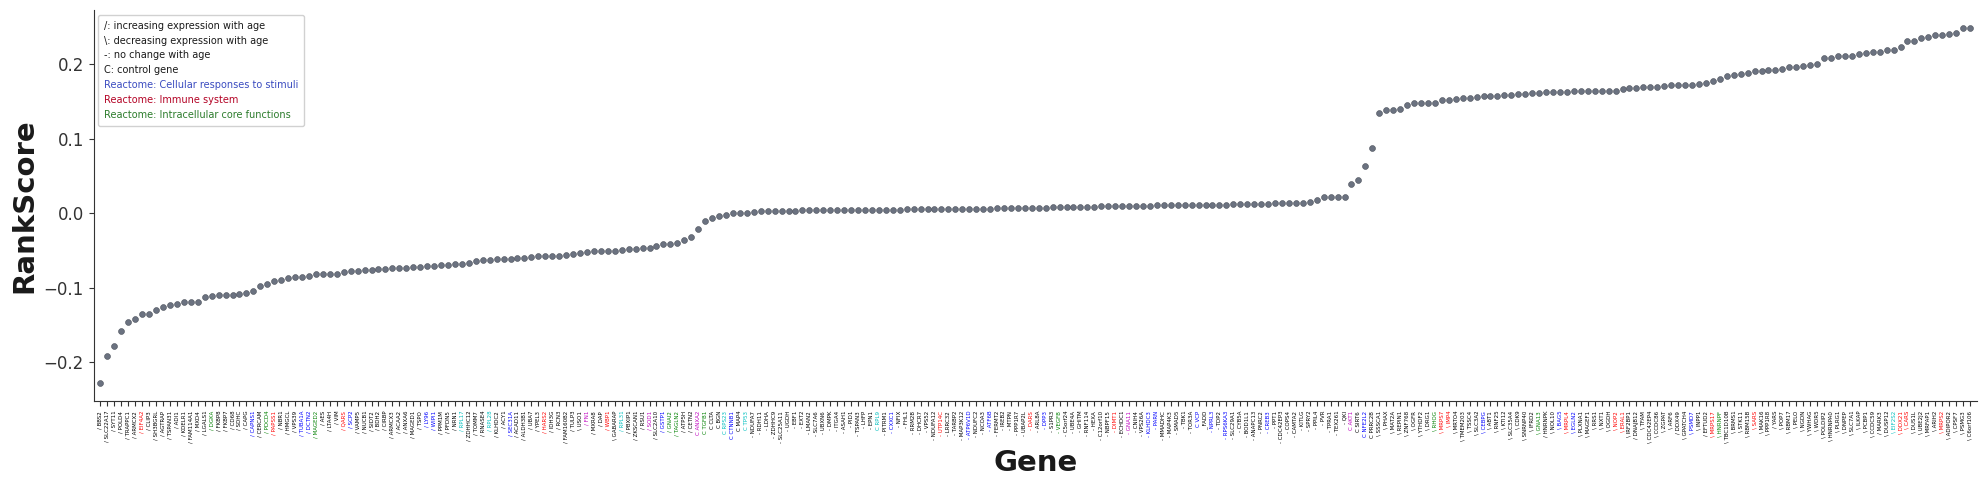

In [278]:
plot_masterscore_waterfall(
    sumdf,
    liblabeldict['tritile'],
    liblabeldict['color'],
    gene_col="Gene",
    score_col="RankScore",
    symbol_labels=None,
    category_labels=None,
    ax=None,
    figsize=(20, 5),
    point_color=None,
    point_size=18,
    tick_fontsize=4,
    panel_label=None)
plt.savefig('./newfigures/RankScores_waterfall.pdf')

## Panel C

In [279]:
DataDict['Figure2'].keys()

dict_keys(['RankScores_and_Other_Gene_Info', 'Adata_Obs', 'Adata_UMAP', 'Edglist', 'ComparativeNetworkStatistics', 'ComparandaPrecisions', 'DEdict'])

In [280]:
UMAP_coords=DataDict['Figure2']['Adata_UMAP']
UMAP_metadata=DataDict['Figure2']['Adata_Obs']

In [281]:
UMAP_metadata.reset_index(drop=True, inplace=True)
UMAP_metadata

,Gene,batch,n_genes_by_counts,total_counts,pct_counts_in_top_50_genes,pct_counts_in_top_100_genes,pct_counts_in_top_200_genes,pct_counts_in_top_500_genes,total_counts_mito,pct_counts_mito,total_counts_ribo,pct_counts_ribo,total_counts_malat,pct_counts_malat,S_score,G2M_score,phase,Color,Tritile,Age
0,OLD,0,2424,4202.000000,20.645333,27.166040,36.284321,52.982723,35.0,0.832937,39.000000,0.928129,89.0,2.118039,-0.048770,-0.114748,G1,old,,55yo
1,OLD,0,4433,11432.000000,19.889942,26.413359,34.777974,49.268735,149.0,1.303359,98.833344,0.864532,168.0,1.469559,-0.310465,0.030107,G2M,old,,55yo
2,OLD,0,1763,2792.000000,24.104587,30.578441,39.604230,57.342412,32.0,1.146132,29.000000,1.038682,79.0,2.829513,0.023805,0.042095,G2M,old,,55yo
3,OLD,0,2206,3858.000000,25.298087,31.233806,39.606021,56.341813,54.0,1.399689,66.000000,1.710731,47.0,1.218248,0.041313,-0.073496,S,old,,55yo
4,OLD,0,2847,5583.000000,25.362695,31.047808,38.867972,53.512422,33.0,0.591080,47.000000,0.841841,96.0,1.719506,-0.039879,-0.073629,G1,old,,55yo
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
532314,DCTN2,3,1855,2936.000000,22.411448,29.189378,38.646694,56.276773,54.0,1.839237,34.000000,1.158038,78.0,2.656676,-0.092736,0.176420,G2M,b,/,Perturbed with transgene
532315,DCTN2,3,1362,1963.999878,25.865577,32.688387,42.871685,59.725043,26.0,1.323829,28.833332,1.468092,48.0,2.443992,-0.018095,-0.147144,G1,b,/,Perturbed with transgene
532316,DCTN2,3,2213,3275.000000,17.353686,22.880402,31.511441,49.832046,19.0,0.580153,33.666672,1.027990,64.0,1.954198,0.338659,-0.229116,S,b,/,Perturbed with transgene
532317,DCTN2,3,5993,19437.000000,21.510407,27.307405,34.656122,47.402419,384.0,1.975613,240.000000,1.234758,165.0,0.848896,-0.166548,-0.434278,G1,b,/,Perturbed with transgene


In [282]:
UMAP_metadata.Color.unique()

['old', 'young', 'm', 'c', 'r', 'k', 'b', 'g']
Categories (8, object): ['b', 'c', 'g', 'k', 'm', 'old', 'r', 'young']

In [283]:
UMAP_metadata[UMAP_metadata.Color=='old'].index

Index([    0,     1,     2,     3,     4,     5,     6,     7,     8,     9,
       ...
       62875, 62876, 62877, 62878, 62879, 62880, 62881, 62882, 62883, 62884],
      dtype='int64', length=62885)

In [284]:
UMAP_x=[i[0] for i in UMAP_coords]; 
UMAP_y=[i[1] for i in UMAP_coords];

CPU times: user 13.7 s, sys: 154 ms, total: 13.8 s
Wall time: 13.6 s


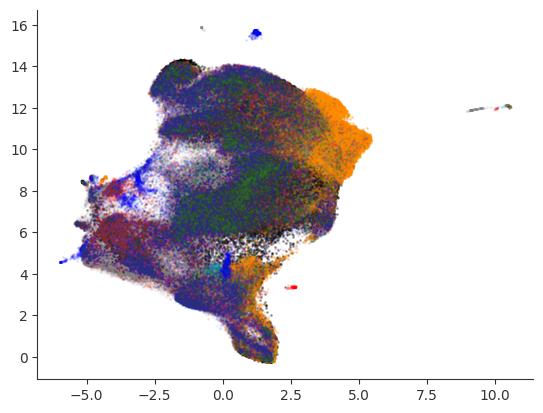

In [178]:
%%time
plt.scatter([UMAP_x[i] for i in UMAP_metadata[UMAP_metadata.Color=='old'].index],[UMAP_y[i] for i in UMAP_metadata[UMAP_metadata.Color=='old'].index],color='k',s=1,alpha=0.3)
plt.scatter([UMAP_x[i] for i in UMAP_metadata[UMAP_metadata.Color=='young'].index],[UMAP_y[i] for i in UMAP_metadata[UMAP_metadata.Color=='young'].index],color='darkorange',s=1,alpha=0.3)

plt.scatter([UMAP_x[i] for i in UMAP_metadata[UMAP_metadata.Color=='m'].index],[UMAP_y[i] for i in UMAP_metadata[UMAP_metadata.Color=='m'].index],color='m',s=1,alpha=0.1)
plt.scatter([UMAP_x[i] for i in UMAP_metadata[UMAP_metadata.Color=='c'].index],[UMAP_y[i] for i in UMAP_metadata[UMAP_metadata.Color=='c'].index],color='c',s=1,alpha=0.1)
plt.scatter([UMAP_x[i] for i in UMAP_metadata[UMAP_metadata.Color=='r'].index],[UMAP_y[i] for i in UMAP_metadata[UMAP_metadata.Color=='r'].index],color='r',s=1,alpha=0.1)
plt.scatter([UMAP_x[i] for i in UMAP_metadata[UMAP_metadata.Color=='b'].index],[UMAP_y[i] for i in UMAP_metadata[UMAP_metadata.Color=='b'].index],color='b',s=1,alpha=0.1)
plt.scatter([UMAP_x[i] for i in UMAP_metadata[UMAP_metadata.Color=='g'].index],[UMAP_y[i] for i in UMAP_metadata[UMAP_metadata.Color=='g'].index],color='g',s=1,alpha=0.1)
plt.scatter([UMAP_x[i] for i in UMAP_metadata[UMAP_metadata.Color=='k'].index],[UMAP_y[i] for i in UMAP_metadata[UMAP_metadata.Color=='k'].index],color='0.5',s=1,alpha=0.01)

plt.savefig('./figures/UMAP_schematic.pdf')

### Claude glow-up

In [285]:
"""
Figure 2, Panel C -- UMAP embedding colored by age condition + Reactome
functional annotation of the perturbed gene.

Real figure-generating code (safe to publish). Same inputs as the
original:

    plt.scatter([UMAP_x[i] for i in UMAP_metadata[UMAP_metadata.Color=='old'].index], ...)
    ... (one plt.scatter call per Color value: old, young, m, c, r, b, g, k)
    plt.savefig('./figures/UMAP_schematic.pdf')

Same UMAP_x / UMAP_y / UMAP_metadata inputs, same 'Color' categorical
column, same eight category values -- display system revised again after
seeing it run on the real data (v1 feedback: the five Reactome categories
turned out to be far from rare -- they cover most of the manifold -- so
"small opaque dots on top" buried old/young instead of protecting them).
Current layering, bottom to top, and why:

  1. 'k' ("no functional annotation") is now hexbinned as its OWN honest
     background layer -- v1 hexbinned ALL points pooled but labeled the
     legend entry "No functional annotation," a mismatch between what was
     plotted and what the legend claimed, which is exactly what made it
     read as invisible/confusing. Now the legend entry is literally what's
     drawn: a hexbin density of just the 'k' subset (falls back to all
     points only if there's no 'k' category present at all). Still one
     PatchCollection instead of N individual markers -- still the single
     biggest lever on file size.
  2. The five Reactome/functional-annotation categories are the
     BACKGROUND texture layer: small, downsampled, and at moderate alpha
     -- since they turned out to be dense rather than sparse, giving them
     full opacity on top (v1's approach) is what buried old/young. They
     still read as color, just no longer fight the age signal for
     attention.
  3. 'old' and 'young' are the TOP layer, deliberately the most visually
     dominant thing in the panel per your "very, very obvious" note: each
     is a filled KDE density cloud in a bold, high-alpha color PLUS a
     solid outline contour at the same threshold, so the age territory
     reads clearly as a distinct shape even where Reactome dots sit
     underneath it.

Color choices, revised: 'old' no longer uses SLATE -- at the alpha needed
for a KDE fill, SLATE read as generic gray and was easy to mistake for the
hexbin base layer itself. 'old' is now AGE_OLD_COLOR, a dark charcoal-navy
with enough presence to read as a deliberate color, not "the background."
'young' stays GOLD. The five functional categories still use five house
ACCENTS (ink_blue, terracotta, moss, plum, teal) instead of raw
matplotlib primaries (b/r/g/m/c) -- plum and teal stand in for the
original's magenta/cyan "combo" colors (Cellular-responses+Immune and
Cellular-responses+Intracellular-core respectively).

xlim / ylim: a small handful of outlier points (UMAP_x > 6 in your real
data) get dropped from every layer -- not just clipped from view -- via
the xlim/ylim args, so they don't cost anything in hexbin/KDE computation
or file size either.

v3 fixes (both diagnosed and confirmed against isolated synthetic repros
before being folded in here):

  * The 'young' (and 'old') filled KDE core was rendering visibly darker
    and muddier than its intended color -- GOLD's densest core read as a
    SLATE-ish grey, exactly the "looks like the old population" confusion
    you flagged. Root cause: seaborn's kdeplot(fill=True) hands its levels
    to matplotlib's contourf, which (a) samples the colormap per band at
    i/(n_bands-1) -- so even the *topmost* band never reaches the
    colormap's true endpoint color -- and (b) can hand back a dark/
    undefined "extend" color for any density above the highest explicit
    level. Fixed by replacing sns.kdeplot's fill with a hand-rolled
    _filled_kde(): compute the KDE with scipy directly, normalize it so
    the peak is exactly 1.0 (nothing left to extend past), and pick each
    band's color explicitly so the last one IS the exact intended color.
  * The 'k' ("no functional annotation") hexbin layer was still
    effectively invisible even once it was honestly showing just the 'k'
    subset (previous fix). Root cause: hexbin's default color scaling is
    LINEAR across every hexagon's count -- if the 'k' points are broadly
    spread but have even a modest denser pocket, that one hexagon sets the
    top of the scale and every sparser-but-real hexagon gets compressed
    into the bottom sliver of the colormap, rendering as near-white.
    Fixed with bins="log" (compresses the dynamic range so sparse-but-real
    regions stay visible) plus lightening the colormap's floor off pure
    white, so single-count hexagons still show a whisper of texture.

Usage:

    import paper_style as style
    from fig2_panelC_umap import plot_umap_schematic

    style.apply()
    fig, ax = plot_umap_schematic(UMAP_x, UMAP_y, UMAP_metadata, xlim=(-6, 6))
    fig.savefig("Figure2_PanelC_umap.pdf", bbox_inches="tight", dpi=300)

`dpi=300` matters here even though this is a vector PDF: the hexbin base
layer and the two KDE fills are the only things NOT explicitly
rasterized below, and 300dpi keeps them crisp without ballooning the
file the way plotting every point did.

See _preview_umap_schematic.py for the synthetic-data smoke test (not for
publication).
"""

from __future__ import annotations

import numpy as np
import matplotlib.pyplot as plt
import matplotlib.lines as mlines
from matplotlib.colors import LinearSegmentedColormap
from scipy.stats import gaussian_kde

import paper_style as style

# Reactome-category -> house accent (see module docstring for the mapping
# rationale). Keys match the original code's single-letter Color values.
REACTOME_COLOR_MAP = {
    "b": style.INK_BLUE,   # Reactome: Cellular responses to stimuli
    "r": style.TERRACOTTA,  # Reactome: Immune system
    "g": style.MOSS,        # Reactome: Intracellular core functions
    "m": style.PLUM,        # combo: Cellular responses + Immune system
    "c": style.TEAL,        # combo: Cellular responses + Intracellular core
}
REACTOME_LABELS = {
    "b": "Reactome: Cellular responses to stimuli",
    "r": "Reactome: Immune system",
    "g": "Reactome: Intracellular core functions",
    "m": "Cellular responses + Immune system",
    "c": "Cellular responses + Intracellular core",
}

# Deliberately NOT style.SLATE (see module docstring: SLATE-at-KDE-alpha
# read as generic gray, easy to confuse with the hexbin base layer). A
# dark charcoal-navy instead -- distinct from both the pale hexbin gray
# and from INK_BLUE (used below for a Reactome category).
#AGE_OLD_COLOR = "#232733"
AGE_OLD_COLOR = None
AGE_YOUNG_COLOR = None  # resolved to style.GOLD at call time


def _xy_for(UMAP_x, UMAP_y, idx):
    x = np.asarray([UMAP_x[i] for i in idx], dtype=float)
    y = np.asarray([UMAP_y[i] for i in idx], dtype=float)
    return x, y


def _maybe_downsample(x, y, cap, rng):
    if len(x) <= cap:
        return x, y
    keep = rng.choice(len(x), size=cap, replace=False)
    return x[keep], y[keep]


def _filled_kde(ax, x, y, color, alpha, thresh, n_levels, grid_size, zorder,
                 outline_color, outline_width):
    """Filled KDE density cloud, built by hand instead of via
    ``sns.kdeplot(fill=True, ...)``.

    Why: seaborn's fill builds its colormap with ``light_palette(color,
    as_cmap=True)`` and hands the *levels* straight to ``contourf``.
    ``contourf`` colors N-1 bands by sampling the colormap at
    ``i / (N-1)`` for the i-th band -- so even the topmost band never
    actually reaches the colormap's own endpoint color, AND if the true
    peak density exceeds the highest explicit level, contourf's "extend"
    handling for the overflow region can hand back a dark/undefined
    color. Both effects together are what made the densest core of a
    GOLD ('young') cloud render as a muddy grey-brown that read as
    SLATE ('old') to the eye -- confirmed by isolating the layer and
    sampling rendered pixels directly.

    Fix: compute the KDE ourselves, normalize it so the peak is exactly
    1.0 (nothing left to "extend" past), and pick each band's color
    explicitly so the last band is ``cmap(1.0)`` -- the *exact* intended
    color -- rather than whatever contourf would have sampled.
    """
    xy = np.vstack([x, y])
    kde = gaussian_kde(xy)
    xmin, xmax = x.min() - 1, x.max() + 1
    ymin, ymax = y.min() - 1, y.max() + 1
    xx, yy = np.mgrid[xmin:xmax:complex(grid_size), ymin:ymax:complex(grid_size)]
    density = kde(np.vstack([xx.ravel(), yy.ravel()])).reshape(xx.shape)
    density_norm = density / density.max()

    cmap = LinearSegmentedColormap.from_list("kde_cmap", ["#ffffff", color])
    levels = np.linspace(thresh, 1.0, n_levels)
    n_bands = len(levels) - 1
    band_colors = [cmap(i / (n_bands - 1)) for i in range(n_bands)]

    ax.contourf(
        xx, yy, density_norm, levels=levels, colors=band_colors,
        alpha=alpha, extend="neither", antialiased=True, zorder=zorder,
    )
    ax.contour(
        xx, yy, density_norm, levels=[thresh], colors=[outline_color],
        linewidths=outline_width, zorder=zorder + 0.5,
    )


def plot_umap_schematic(
    UMAP_x,
    UMAP_y,
    UMAP_metadata,
    color_col="Color",
    ax=None,
    figsize=(7.2, 6.2),
    xlim=None,
    ylim=None,
    hexbin_gridsize=140,
    kde_sample_cap=20000,
    reactome_point_cap=3000,
    reactome_alpha=0.35,
    reactome_size=3,
    kde_levels=6,
    kde_thresh=0.15,
    kde_fill_alpha=0.7,
    kde_outline_width=2.2,
    seed=0,
    panel_label=None,
):
    """Recreate the UMAP schematic with a file-size-conscious, legible
    display system. See module docstring for the full rationale and for
    what changed between v1 and this version.

    xlim / ylim: (lo, hi) tuples. When given, points outside the range are
    dropped from EVERY layer (not just clipped visually) before any
    hexbin/KDE computation, so outliers don't cost file size or skew the
    density estimates.
    """
    age_old_color = style.SLATE
    age_young_color = style.GOLD
    rng = np.random.default_rng(seed)

    if ax is None:
        fig, ax = plt.subplots(figsize=figsize)
    else:
        fig = ax.figure

    all_idx = UMAP_metadata.index
    all_x, all_y = _xy_for(UMAP_x, UMAP_y, all_idx)

    # Drop out-of-range points from every layer up front (not just the
    # view) so they cost nothing in hexbin/KDE computation or file size.
    keep_mask = np.ones(len(all_idx), dtype=bool)
    if xlim is not None:
        keep_mask &= (all_x >= xlim[0]) & (all_x <= xlim[1])
    if ylim is not None:
        keep_mask &= (all_y >= ylim[0]) & (all_y <= ylim[1])
    kept_idx = np.asarray(all_idx)[keep_mask]
    all_x, all_y = all_x[keep_mask], all_y[keep_mask]
    metadata = UMAP_metadata.loc[kept_idx]

    # --- Layer 1 (bottom): "No functional annotation" as an honest hexbin -
    # v1 hexbinned ALL points (every category pooled) but the legend
    # called it "No functional annotation" -- a mismatch between what was
    # labeled and what was actually drawn, which is exactly what made this
    # layer confusing/invisible-seeming. Now it's a hexbin of ONLY the 'k'
    # points, so the legend entry is literally what's on the page. Falls
    # back to all points only if there's no 'k' column/category to hexbin.
    if color_col in metadata.columns and (metadata[color_col] == "k").any():
        base_idx = metadata[metadata[color_col] == "k"].index
    else:
        base_idx = metadata.index
    base_x, base_y = _xy_for(UMAP_x, UMAP_y, base_idx)
    # bins="log": hexbin's default is LINEAR count-to-color scaling across
    # ALL hexagons on the plot. If the 'k' points are broadly spread but
    # have even a modest denser pocket somewhere, that single hexagon sets
    # the top of the scale and every other (sparser, but still real)
    # hexagon gets compressed into the bottom sliver of the colormap --
    # i.e. rendered nearly white, indistinguishable from "nothing plotted."
    # Confirmed by reproducing this with a deliberately uneven synthetic
    # 'k' distribution: linear scaling made the diffuse majority invisible;
    # bins="log" made it clearly visible as a stippled texture. Lightened
    # the colormap's low end off pure white too, so single-count hexagons
    # (mincnt=1) still show a whisper of texture instead of blank white.
    base_cmap = LinearSegmentedColormap.from_list("umap_base", ["#f2f2f2", "#8f8f8f"])
    ax.hexbin(
        base_x,
        base_y,
        gridsize=hexbin_gridsize,
        cmap=base_cmap,
        mincnt=1,
        bins="log",
        linewidths=0,
        rasterized=True,
        zorder=1,
        alpha=0.5,
    )

    # --- Layer 2: Reactome categories, now treated as BACKGROUND texture --
    # These turned out to be dense (covering most of the manifold), not
    # sparse as first guessed -- rendering them fully opaque on top (v1)
    # is what buried old/young. Downsampled, small, moderate alpha now.
    for key, color in REACTOME_COLOR_MAP.items():
        idx = metadata[metadata[color_col] == key].index
        if len(idx) == 0:
            continue
        x, y = _xy_for(UMAP_x, UMAP_y, idx)
        x, y = _maybe_downsample(x, y, reactome_point_cap, rng)
        ax.scatter(
            x, y, s=reactome_size, color=color, alpha=reactome_alpha,
            linewidths=0, rasterized=True, zorder=3,
        )

    # --- Layer 3 (top): old vs. young -- deliberately the most visually --
    # dominant thing in the panel: a bold filled density PLUS a solid
    # outline contour, so the age territory reads clearly no matter what's
    # underneath it.
    for label, color, zorder in (("old", age_old_color, 4), ("young", age_young_color, 5)):
        idx = metadata[metadata[color_col] == label].index
        if len(idx) == 0:
            continue
        x, y = _xy_for(UMAP_x, UMAP_y, idx)
        x, y = _maybe_downsample(x, y, kde_sample_cap, rng)
        if len(x) < 10:
            # Too few points for a KDE to mean anything -- fall back to a
            # plain, bold scatter rather than erroring out.
            ax.scatter(x, y, s=5, color=color, alpha=0.9, linewidths=0, rasterized=True, zorder=zorder)
            continue

        # Hand-rolled instead of sns.kdeplot(fill=True, ...) -- see
        # _filled_kde's docstring for why: seaborn/contourf's default band
        # coloring was rendering the densest core noticeably darker/muddier
        # than the intended color (GOLD's core read as SLATE-ish grey).
        # Bold outline at the KDE threshold is included, same as before, so
        # the boundary stays crisp even where it overlaps other layers --
        # the "very, very obvious" part.
        _filled_kde(
            ax, x, y, color, alpha=kde_fill_alpha, thresh=kde_thresh,
            n_levels=kde_levels, grid_size=150, zorder=zorder,
            outline_color=style.darken(color, 0.2), outline_width=kde_outline_width,
        )

    if xlim is not None:
        ax.set_xlim(xlim)
    if ylim is not None:
        ax.set_ylim(ylim)
    ax.set_xlabel("UMAP 1")
    ax.set_ylabel("UMAP 2")
    style.despine_clean(ax)

    # --- Legend, rebuilt with the new house colors -------------------------
    legend_rows = [
        ("55yo untreated", age_old_color),
        ("25yo untreated", age_young_color),
        (REACTOME_LABELS["b"], REACTOME_COLOR_MAP["b"]),
        (REACTOME_LABELS["r"], REACTOME_COLOR_MAP["r"]),
        (REACTOME_LABELS["g"], REACTOME_COLOR_MAP["g"]),
        (REACTOME_LABELS["m"], REACTOME_COLOR_MAP["m"]),
        (REACTOME_LABELS["c"], REACTOME_COLOR_MAP["c"]),
        ("No functional annotation (background density only)", "#c9c9c9"),
    ]
    handles = [
        mlines.Line2D([], [], marker="o", linestyle="none", markersize=6.5,
                      markerfacecolor=c, markeredgecolor=style.darken(c, 0.3) if c != "#c9c9c9" else "#999999")
        for _, c in legend_rows
    ]
    ax.legend(
        handles,
        [label for label, _ in legend_rows],
        loc="upper left",
        bbox_to_anchor=(1.02, 1.0),
        frameon=True,
        framealpha=0.95,
        edgecolor="#cccccc",
        fontsize=8.5,
        handletextpad=0.6,
        borderpad=0.7,
    )

    if panel_label:
        ax.text(
            -0.08, 1.04, panel_label, transform=ax.transAxes,
            fontsize=14, fontweight="bold", va="bottom", ha="left",
        )

    fig.tight_layout()
    return fig, ax


CPU times: user 15.5 s, sys: 1.72 s, total: 17.2 s
Wall time: 14.1 s


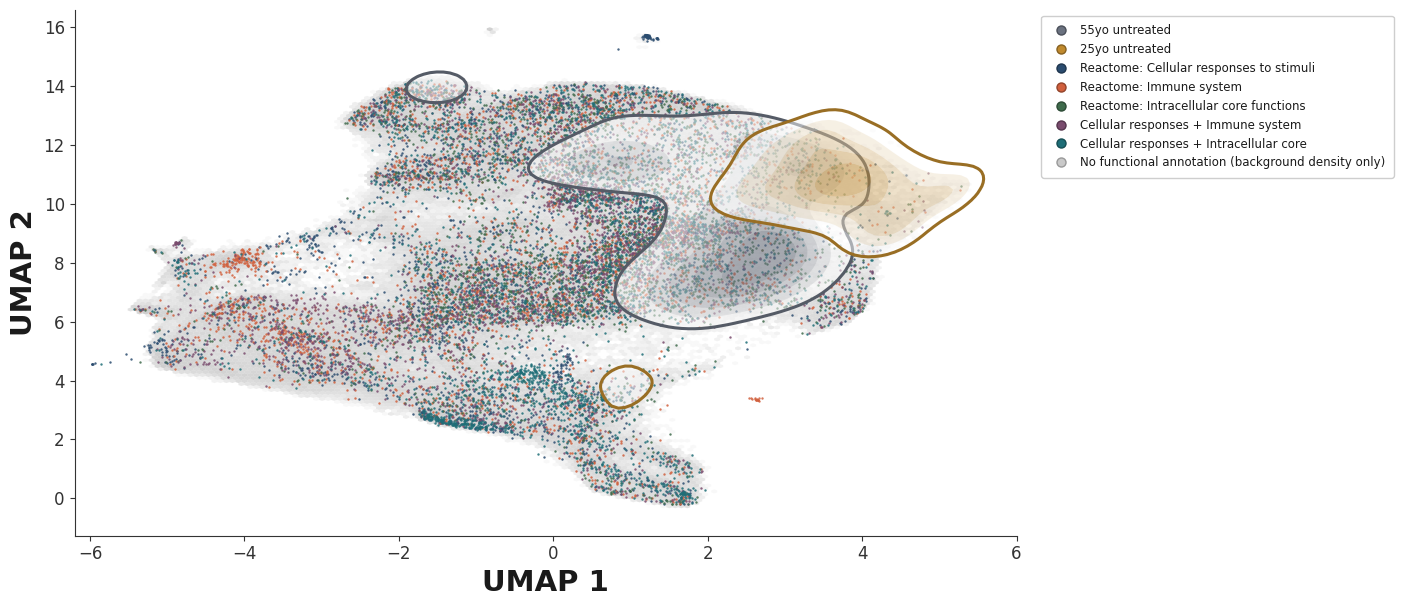

In [286]:
%%time
plot_umap_schematic(
    UMAP_x,
    UMAP_y,
    UMAP_metadata,
    color_col="Color",
    ax=None,
    figsize=(14.2, 6.2),
    xlim=[-6.2,6],
    ylim=None,
    hexbin_gridsize=140,
    kde_sample_cap=20000,
    reactome_point_cap=3000,
    reactome_alpha=0.85,
    reactome_size=3,
    kde_levels=6,
    kde_thresh=0.18,
    kde_fill_alpha=0.5,
    kde_outline_width=2.2,
    seed=0,
    panel_label=None)
plt.savefig('./newfigures/UMAP_schematic.pdf',bbox_inches='tight')

## Panel D* read accompanying note 

This one requires extensive graph visualization packages. It also alters basic plotting parameters (from Matplotlib) in a way that may make other figures not render correctly, and should therefore largely be run ON ITS OWN KERNEL

In [5]:
import networkx as nx
import holoviews as hv

This next cell can throw some non-essential errors

In [6]:
sc.settings.verbosity = 3  # verbosity: errors (0), warnings (1), info (2), hints (3)
sc.settings.set_figure_params(dpi=80, frameon=False, figsize=(5, 5), facecolor='white')  # low dpi (dots per inch) yields small inline figures

from holoviews import opts
import datashader
#import scikit-image
import networkx as nx
from holoviews.operation.datashader import datashade, bundle_graph

hv.extension('matplotlib')
defaults = dict(width=400, height=400)
hv.opts.defaults(
    opts.EdgePaths(**defaults), opts.Graph(**defaults), opts.Nodes(**defaults))

/opt/conda/lib/python3.9/site-packages/dask/dataframe/__init__.py:42: FutureWarning: 
Dask dataframe query planning is disabled because dask-expr is not installed.

You can install it with `pip install dask[dataframe]` or `conda install dask`.
This will raise in a future version.

  warnings.warn(msg, FutureWarning)


<img src='data:image/png;base64,iVBORw0KGgoAAAANSUhEUgAAAEAAAABACAYAAACqaXHeAAAABHNCSVQICAgIfAhkiAAAAAlwSFlz
AAAB+wAAAfsBxc2miwAAABl0RVh0U29mdHdhcmUAd3d3Lmlua3NjYXBlLm9yZ5vuPBoAAA6zSURB
VHic7ZtpeFRVmsf/5966taWqUlUJ2UioBBJiIBAwCZtog9IOgjqACsogKtqirT2ttt069nQ/zDzt
tI4+CrJIREFaFgWhBXpUNhHZQoKBkIUASchWla1S+3ar7r1nPkDaCAnZKoQP/D7mnPOe9/xy76n3
nFSAW9ziFoPFNED2LLK5wcyBDObkb8ZkxuaoSYlI6ZcOKq1eWFdedqNzGHQBk9RMEwFAASkk0Xw3
ETacDNi2vtvc7L0ROdw0AjoSotQVkKSvHQz/wRO1lScGModBFbDMaNRN1A4tUBCS3lk7BWhQkgpD
lG4852/+7DWr1R3uHAZVQDsbh6ZPN7CyxUrCzJMRouusj0ipRwD2uKm0Zn5d2dFwzX1TCGhnmdGo
G62Nna+isiUqhkzuKrkQaJlPEv5mFl2fvGg2t/VnzkEV8F5ioioOEWkLG86fvbpthynjdhXYZziQ
x1hC9J2NFyi8vCTt91Fh04KGip0AaG9zuCk2wQCVyoNU3Hjezee9bq92duzzTmxsRJoy+jEZZZYo
GTKJ6SJngdJqAfRzpze0+jHreUtPc7gpBLQnIYK6BYp/uGhw9YK688eu7v95ysgshcg9qSLMo3JC
4jqLKQFBgdKDPoQ+Pltb8dUyQLpeDjeVgI6EgLIQFT5tEl3rn2losHVsexbZ3EyT9wE1uGdkIPcy
BGxn8QUq1QrA5nqW5i2tLqvrrM9NK6AdkVIvL9E9bZL/oyfMVd/jqvc8LylzRBKDJSzIExwhQzuL
QYGQj4rHfFTc8mUdu3E7yoLtbTe9gI4EqVgVkug2i5+uXGo919ixbRog+3fTbQ8qJe4ZOYNfMoTI
OoshUNosgO60AisX15aeI2PSIp5KiFLI9ubb1vV3Qb2ltwLakUCDAkWX7/nHKRmmGIl9VgYsUhJm
2NXjKYADtM1ygne9QQDIXlk49FBstMKx66D1v4+XuQr7vqTe0VcBHQlRWiOCbmmSYe2SqtL6q5rJ
zsTb7lKx3FKOYC4DoqyS/B5bvLPxvD9Qtf6saxYLQGJErmDOdOMr/zo96km1nElr8bmPOBwI9COv
HnFPRIwmkSOv9kcAS4heRsidOkpeWBgZM+UBrTFAXNYL5Vf2ii9c1trNzpYdaoVil3WIc+wdk+gQ
noie3ecCcxt9ITcLAPWt/laGEO/9U6PmzZkenTtsSMQ8uYywJVW+grCstAvCIaAdArAsIWkRDDs/
KzLm2YcjY1Lv0UdW73HabE9n6V66cxSzfEmuJssTpKGVp+0vHq73FwL46eOjpMpbRAnNmJFrGJNu
Ukf9Yrz+3rghiumCKNXXWPhLYcjxGsIpoCMsIRoFITkW8AuyM8jC1+/QLx4bozCEJIq38+1rtpR6
V/yzb8eBlRb3fo5l783N0CWolAzJHaVNzkrTzlEp2bQ2q3TC5gn6wpnoQAmwSiGh2GitnTmVMc5O
UyfKWUKCIsU7+fZDKwqdT6DDpvkzAX4/+AMFjk0tDp5GRXLpQ2MUmhgDp5gxQT8+Y7hyPsMi8uxF
71H0oebujHALECjFKaW9Lm68n18wXp2kVzIcABytD5iXFzg+WVXkegpAsOOYziqo0OkK76GyquC3
ltZAzMhhqlSNmmWTE5T6e3IN05ITFLM4GdN0vtZ3ob8Jh1NAKXFbm5PtLU/eqTSlGjkNAJjdgn/N
aedXa0tdi7+t9G0FIF49rtMSEgAs1kDLkTPO7ebm4IUWeyh1bKomXqlgMG6kJmHcSM0clYLJ8XtR
1GTnbV3F6I5wCGikAb402npp1h1s7LQUZZSMIfALFOuL3UUrfnS8+rez7v9qcold5tilgHbO1fjK
9ubb17u9oshxzMiUBKXWqJNxd+fqb0tLVs4lILFnK71H0Ind7uiPgACVcFJlrb0tV6DzxqqTIhUM
CwDf1/rrVhTa33/3pGPxJYdQ2l2cbgVcQSosdx8uqnDtbGjh9SlDVSMNWhlnilfqZk42Th2ZpLpf
xrHec5e815zrr0dfBZSwzkZfqsv+1FS1KUknUwPARVvItfKUY+cn57yP7qv07UE3p8B2uhUwLk09
e0SCOrK+hbdYHYLjRIl71wWzv9jpEoeOHhGRrJAzyEyNiJuUqX0g2sBN5kGK6y2Blp5M3lsB9Qh4
y2Ja6x6+i0ucmKgwMATwhSjdUu49tKrQ/pvN5d53ml2CGwCmJipmKjgmyuaXzNeL2a0AkQ01Th5j
2DktO3Jyk8f9vcOBQHV94OK+fPumJmvQHxJoWkaKWq9Vs+yUsbq0zGT1I4RgeH2b5wef7+c7bl8F
eKgoHVVZa8ZPEORzR6sT1BzDUAD/d9F78e2Tzv99v8D+fLVTqAKAsbGamKey1Mt9Ann4eH3gTXTz
idWtAJ8PQWOk7NzSeQn/OTHDuEikVF1R4z8BQCy+6D1aWRfY0tTGG2OM8rRoPaeIj5ZHzJxszElN
VM8K8JS5WOfv8mzRnQAKoEhmt8gyPM4lU9SmBK1MCQBnW4KONT86v1hZ1PbwSXPw4JWussVjtH9Y
NCoiL9UoH/6PSu8jFrfY2t36erQHXLIEakMi1SydmzB31h3GGXFDFNPaK8Rme9B79Ixrd0WN+1ij
NRQ/doRmuFLBkHSTOm5GruG+pFjFdAmorG4IXH1Qua6ASniclfFtDYt+oUjKipPrCQB7QBQ2lrgP
fFzm+9XWUtcqJ3/5vDLDpJ79XHZk3u8nGZ42qlj1+ydtbxysCezrydp6ugmipNJ7WBPB5tydY0jP
HaVNzs3QzeE4ZpTbI+ZbnSFPbVOw9vsfnVvqWnirPyCNGD08IlqtYkh2hjZ5dErEQzoNm+6ykyOt
Lt5/PQEuSRRKo22VkydK+vvS1XEKlhCJAnsqvcVvH7f/ZU2R67eXbMEGAMiIV5oWZWiWvz5Fv2xG
sjqNJQRvn3Rs2lji/lNP19VjAQDgD7FHhujZB9OGqYxRkZxixgRDVlqS6uEOFaJUVu0rPFzctrnF
JqijImVp8dEKVWyUXDk92zAuMZ6bFwpBU1HrOw6AdhQgUooChb0+ItMbWJitSo5Ws3IAOGEOtL53
0vHZih9sC4vtofZ7Qu6523V/fmGcds1TY3V36pUsBwAbSlxnVh2xLfAD/IAIMDf7XYIkNmXfpp2l
18rkAJAy9HKFaIr/qULkeQQKy9zf1JgDB2uaeFNGijo5QsUyacNUUTOnGO42xSnv4oOwpDi1zYkc
efUc3I5Gk6PhyTuVKaOGyLUAYPGIoY9Pu/atL/L92+4q9wbflRJ2Trpm/jPjdBtfnqB/dIThcl8A
KG7hbRuKnb8qsQsVvVlTrwQAQMUlf3kwJI24Z4JhPMtcfng5GcH49GsrxJpGvvHIaeem2ma+KSjQ
lIwUdYyCY8j4dE1KzijNnIP2llF2wcXNnsoapw9XxsgYAl6k+KzUXbi2yP3KR2ecf6z3BFsBICdW
nvnIaG3eHybqX7vbpEqUMT+9OL4Qpe8VON7dXuFd39v19FoAABRVePbGGuXTszO0P7tu6lghUonE
llRdrhArLvmKdh9u29jcFiRRkfLUxBiFNiqSU9icoZQHo5mYBI1MBgBH6wMNb+U7Pnw337H4gi1Y
ciWs+uks3Z9fztUvfzxTm9Ne8XXkvQLHNytOOZeiD4e0PgkAIAYCYknKUNUDSXEKzdWNpnil7r4p
xqkjTarZMtk/K8TQ6Qve78qqvXurGwIJqcOUKfUWHsm8KGvxSP68YudXq4pcj39X49uOK2X142O0
Tz5/u/7TVybqH0rSya6ZBwD21/gubbrgWdDgEOx9W

ValueError: In opts.EdgePaths(...), unexpected option 'width' for EdgePaths type across all extensions. Similar options for current extension ('matplotlib') are: ['cbar_width', 'linewidth'].

In [7]:
DataDict['Figure2'].keys()

dict_keys(['RankScores_and_Other_Gene_Info', 'Adata_Obs', 'Adata_UMAP', 'Edglist', 'ComparativeNetworkStatistics', 'ComparandaPrecisions', 'DEdict'])

In [8]:
EdgeList=DataDict['Figure2']['Edglist']
print(len(EdgeList))
EdgeList[0:5]

107250


[('ANXA2', 'ITGA10'),
 ('ANXA2', 'IFT52'),
 ('ANXA2', 'SF3B6'),
 ('ANXA2', 'CHD1L'),
 ('ANXA2', 'OTUD5')]

In [9]:
EdgeListDf=pd.DataFrame(EdgeList)
EdgeListDf.columns=['Causer','Causee']
EdgeListDf.head()

,Causer,Causee
0,ANXA2,ITGA10
1,ANXA2,IFT52
2,ANXA2,SF3B6
3,ANXA2,CHD1L
4,ANXA2,OTUD5


In [10]:
Gm=nx.from_edgelist(EdgeList)

In [11]:
DEdict=DataDict['Figure2']['DEdict']

This next cell essentially indexes which edges predicted by CCM were substantiated or not substantiated by DE

In [12]:
EDMdict={}
for gene in DEdict.keys():
    try:
        EDMdict[gene]=list(EdgeListDf[EdgeListDf.Causer==gene].Causee.values)
    except:
        EDMdict[gene]=[]

OverlapDict={}
for gene in EDMdict.keys():
    OverlapDict[gene]=list(set(DEdict[gene]).intersection(set(EDMdict[gene])))

ConfirmedEdges=[]
for key in OverlapDict.keys():
    for val in OverlapDict[key]:
        ConfirmedEdges.append((key,val))
        
ConfirmedEdges[0:5]

[('ANXA2', 'GSK3B'),
 ('ANXA2', 'PKM'),
 ('ANXA2', 'MLLT1'),
 ('ANXA2', 'PLSCR4'),
 ('ANXA2', 'ZDHHC16')]

Store these in the NetworkX object (can take a few minutes)

In [13]:
%%time
for node, _ in enumerate(Gm.nodes()):
    #print(node)
    #print(_)
    if _ in EDMdict.keys():
        Gm.nodes[_]['type']=1
    else:
        Gm.nodes[_]['type']=0
        
for node, _ in enumerate(Gm.edges()):
    #print(node)
    #print(_)

    if _ in ConfirmedEdges:
        Gm.edges[_]['confirmation']=1
    else:
        Gm.edges[_]['confirmation']=0

CPU times: user 2min 16s, sys: 0 ns, total: 2min 16s
Wall time: 2min 16s


In [14]:
kwargs = dict(width=800, height=800, xaxis=None, yaxis=None)
opts.defaults(opts.Nodes(**kwargs), opts.Graph(**kwargs))

ValueError: In opts.Nodes(...), unexpected option 'width' for Nodes type across all extensions. Similar options for current extension ('matplotlib') are: ['cbar_width', 'linewidth'].

In [20]:
%%time
N = hv.Graph.from_networkx(Gm, nx.layout.fruchterman_reingold_layout,k=None,iterations=250).opts(
                                                                          node_size=5,
                                                                          node_color='type',
                                                                          cmap = ['orange','blue'],
                                                                              edge_line_color='confirmation', fig_size=750,edge_line_width=0.25)#,fig_size=750


CPU times: user 3min 18s, sys: 0 ns, total: 3min 18s
Wall time: 3min 18s


This SHOULD produce a result that looks like the paper's figure, up to rotation. But I am not positive that any RNG element to Fruchterman-Reingold will not result in a different embedding. At some point, it might be necessary to take our word that the visualization in the figure arises from the same edge list. In any case, the size of the network in the figure and the bundling of the edges makes the figure more of a schematic than a verifiable object.

CPU times: user 5min 22s, sys: 5min 12s, total: 10min 34s
Wall time: 5min 37s


:Graph   [start,end]   (confirmation)
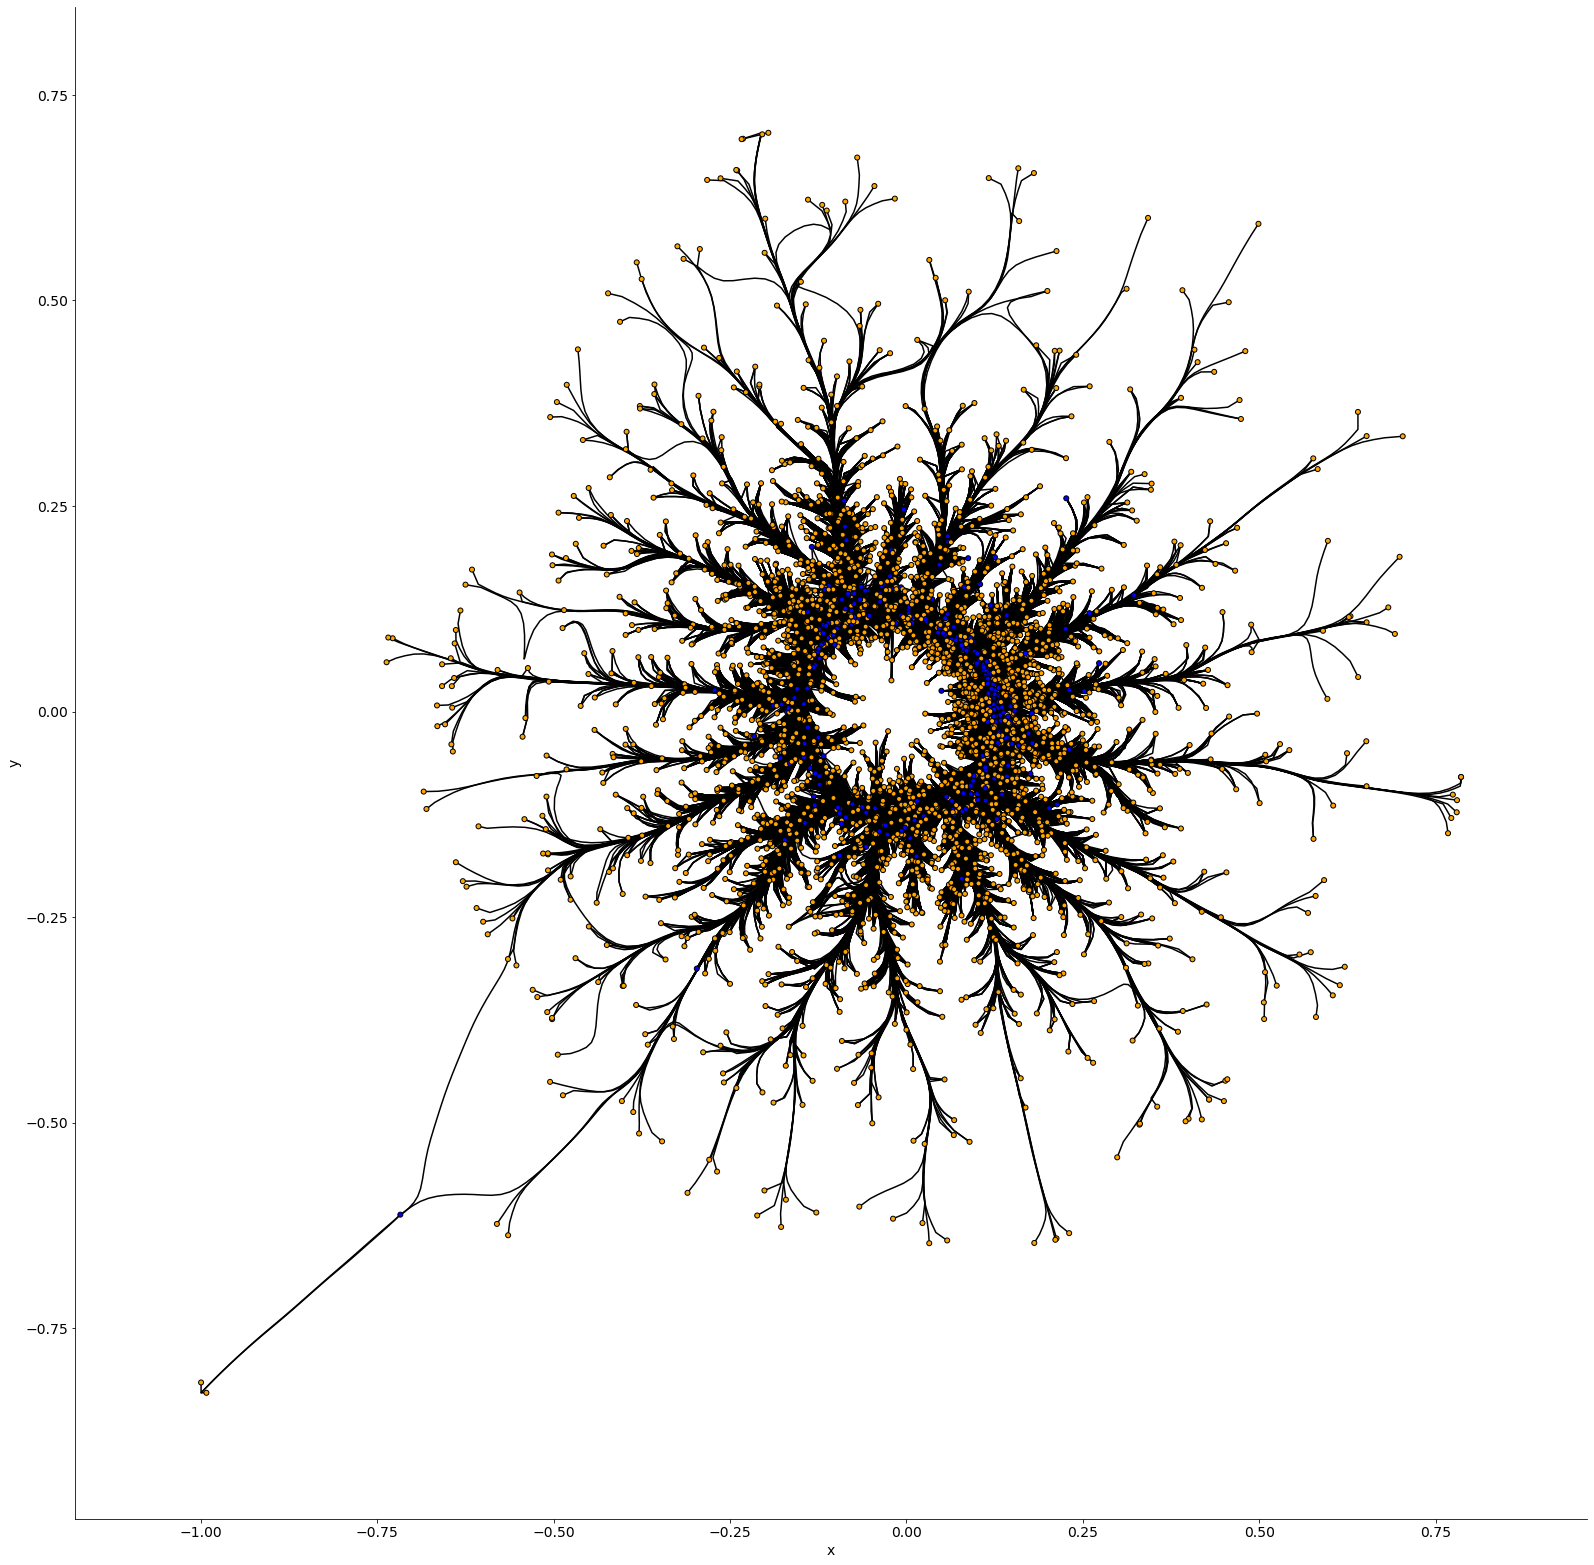

In [21]:
%%time
bundled = bundle_graph(N)
bundled

In [22]:
hv.save(bundled,'./figures/bundled_edges.png',fmt='png')

In [24]:
hv.save(bundled,'./figures/bundled_edges.pdf',fmt='pdf')

## Panel E

In [289]:
DataDict['Figure2'].keys()

dict_keys(['RankScores_and_Other_Gene_Info', 'Adata_Obs', 'Adata_UMAP', 'Edglist', 'ComparativeNetworkStatistics', 'ComparandaPrecisions', 'DEdict'])

In [287]:
Comparanda=DataDict['Figure2']['ComparandaPrecisions']
Comparanda.keys()

dict_keys(['WithGFP_true', 'NoGFP_true', 'WithGFP_RandomDeg', 'NoGFP_RandomDeg'])

In [288]:
baseprec=0.537866495; basenogfp=0.300774110
pcorr=0.477577803; pcorrnogfp=0.220868
semprec=0.42268041; semnogfp=0.219512195

In [289]:
from scipy.stats import gaussian_kde

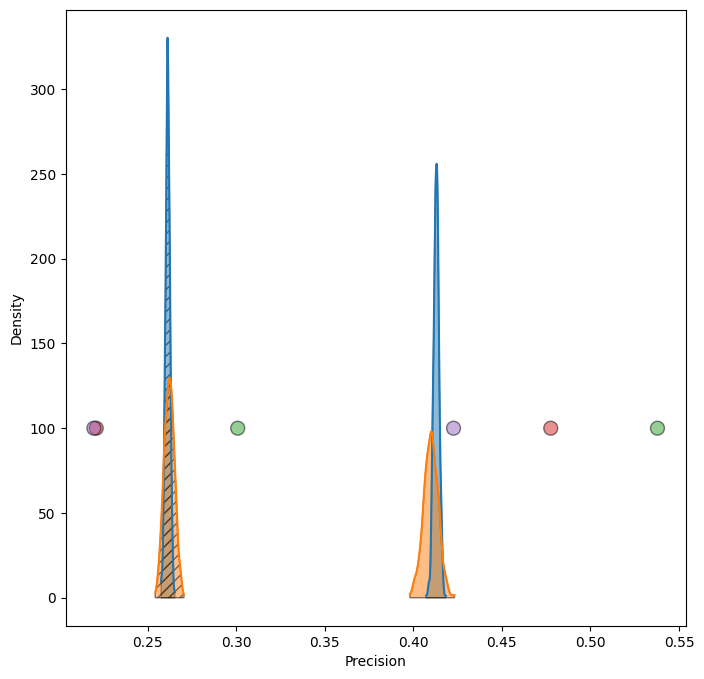

In [71]:
fig,ax=plt.subplots(figsize=(8,8))



kde1=gaussian_kde(Comparanda['WithGFP_true']); x1=np.linspace(min(Comparanda['WithGFP_true']), max(Comparanda['WithGFP_true']), 1000); y1=kde1(x1)
kde2=gaussian_kde(Comparanda['WithGFP_RandomDeg']); x2=np.linspace(min(Comparanda['WithGFP_RandomDeg']), max(Comparanda['WithGFP_RandomDeg']), 1000); y2=kde2(x2)
kde3=gaussian_kde(Comparanda['NoGFP_true']); x3=np.linspace(min(Comparanda['NoGFP_true']), max(Comparanda['NoGFP_true']), 1000); y3=kde3(x3)
kde4=gaussian_kde(Comparanda['NoGFP_RandomDeg']); x4=np.linspace(min(Comparanda['NoGFP_RandomDeg']), max(Comparanda['NoGFP_RandomDeg']), 1000); y4=kde4(x4)

ax.plot(x1, y1, color='tab:blue')
ax.fill_between(x1, y1, color='tab:blue', hatch='', edgecolor='black',alpha=0.5)
ax.plot(x2, y2, color='tab:orange')
ax.fill_between(x2, y2, color='tab:orange', hatch='', edgecolor='black',alpha=0.5)
ax.plot(x3, y3, color='tab:blue')
ax.fill_between(x3, y3, color='tab:blue', hatch='///', edgecolor='black',alpha=0.5)
ax.plot(x4, y4, color='tab:orange')
ax.fill_between(x4, y4, color='tab:orange', hatch='///', edgecolor='black',alpha=0.5)

xdot=[baseprec,pcorr,semprec,basenogfp,pcorrnogfp,semnogfp]; ydot=[100,100,100,100,100,100]; 
colors=['tab:green','tab:red','tab:purple','tab:green','tab:red','tab:purple']
scatter = ax.scatter(xdot, ydot, s=100, c=colors, marker='o', edgecolors='black',alpha=0.5)

# paths = scatter.findobj(match=lambda x: type(x).__name__ == 'PathCollection')
# hatches = ['///', '///', '///', '///', '///', '///']
# for i, path in enumerate(paths):
#     path.set_hatch(hatches[i % len(hatches)])
    

#plt.legend(['a','b','c','d','e','f','a','b','c','d','e','f','a','b','c','d','e','f'])
plt.xlabel('Precision')
plt.ylabel('Density')

#plt.xlim([0.2,0.5])
plt.savefig('./figures/PrecNullCombo.pdf')
plt.show()

### Claude glow-up

In [292]:
"""
Figure 2, Panel E -- observed ("true") vs. null ("random degree-matched")
outdegree-precision distributions, for two gene sets ("all genes included"
and "viral differential expression profile removed"), plus single-point
precision estimates from three alternative network-inference methods
(CCM, Partial correlations, DeepSEM) for each gene set.

Real figure-generating code (safe to publish). Same inputs as the
original:

    kde1 = gaussian_kde(Comparanda['WithGFP_true']);        x1 = linspace(...); y1 = kde1(x1)
    kde2 = gaussian_kde(Comparanda['WithGFP_RandomDeg']);   x2 = linspace(...); y2 = kde2(x2)
    kde3 = gaussian_kde(Comparanda['NoGFP_true']);          x3 = linspace(...); y3 = kde3(x3)
    kde4 = gaussian_kde(Comparanda['NoGFP_RandomDeg']);     x4 = linspace(...); y4 = kde4(x4)
    ax.plot/fill_between(...) x4  (blue = true, orange = random, hatch='///' on the
        NoGFP pair only)
    xdot = [baseprec, pcorr, semprec, basenogfp, pcorrnogfp, semnogfp]
    ax.scatter(xdot, [100]*6, c=['tab:green','tab:red','tab:purple']*2, ...)

Usage:

    import paper_style as style
    from fig2_panelE_precision_null import plot_precision_null_combo

    style.apply()
    fig, ax = plot_precision_null_combo(
        Comparanda, baseprec, pcorr, semprec, basenogfp, pcorrnogfp, semnogfp,
        panel_label="e",
    )
    fig.savefig("Figure2_PanelE_precision_null.pdf", bbox_inches="tight")

See _preview_precision_null.py for the synthetic-data smoke test (not for
publication).
"""

from __future__ import annotations

import numpy as np
import matplotlib.pyplot as plt
import matplotlib.lines as mlines
from scipy.stats import gaussian_kde

import paper_style as style

TRUE_COLOR = style.INK_BLUE
RANDOM_COLOR = style.GOLD
METHOD_COLORS = {
    "CCM": style.MOSS,
    "Partial correlations": style.TERRACOTTA,
    "DeepSEM": style.PLUM,
}
CONDITION_LABELS = ("All genes included", "    Viral differential expression\nprofile removed")
# Redundant with color/position: line style for the KDE outlines and
# marker shape for the point estimates both encode the same "which gene
# set" distinction, so the split still reads even without the legend.
CONDITION_LINESTYLES = ("-", (0, (4, 2)))
CONDITION_MARKERS = ("o", "D")


def _kde_xy(values, n_points):
    values = np.asarray(values, dtype=float)
    kde = gaussian_kde(values)
    x = np.linspace(values.min(), values.max(), n_points)
    return x, kde(x)


def plot_precision_null_combo(
    Comparanda,
    baseprec,
    pcorr,
    semprec,
    basenogfp,
    pcorrnogfp,
    semnogfp,
    all_genes_true_col="WithGFP_true",
    all_genes_random_col="WithGFP_RandomDeg",
    viral_removed_true_col="NoGFP_true",
    viral_removed_random_col="NoGFP_RandomDeg",
    ax=None,
    figsize=(8.4, 5.6),
    kde_points=1000,
    fill_alpha=0.55,
    dot_height_frac=0.32,
    stack_step_frac=0.16,
    value_fontsize=6.8,
    panel_label=None,
):
    """Single-shared-axis redesign of the true-vs-null precision KDE panel.
    See module docstring for the full rationale (and why this replaced an
    earlier two-row version).

    Comparanda: dict-like (e.g. a dict of arrays, or a DataFrame) with the
    four distribution columns named by *_true_col / *_random_col above.
    baseprec / pcorr / semprec: CCM / Partial correlations / DeepSEM
    precision point-estimates for the "all genes included" gene set.
    basenogfp / pcorrnogfp / semnogfp: the same three methods' estimates
    for the "viral differential expression profile removed" gene set.
    """
    if ax is None:
        fig, ax = plt.subplots(figsize=figsize)
    else:
        fig = ax.figure

    x_ag_true, y_ag_true = _kde_xy(Comparanda[all_genes_true_col], kde_points)
    x_ag_rand, y_ag_rand = _kde_xy(Comparanda[all_genes_random_col], kde_points)
    x_vr_true, y_vr_true = _kde_xy(Comparanda[viral_removed_true_col], kde_points)
    x_vr_rand, y_vr_rand = _kde_xy(Comparanda[viral_removed_random_col], kde_points)

    global_peak = max(y_ag_true.max(), y_ag_rand.max(), y_vr_true.max(), y_vr_rand.max())

    all_x = np.concatenate([x_ag_true, x_ag_rand, x_vr_true, x_vr_rand,
                             [baseprec, pcorr, semprec, basenogfp, pcorrnogfp, semnogfp]])
    xpad = 0.09 * (all_x.max() - all_x.min())
    xlim = (all_x.min() - xpad, all_x.max() + xpad)

    # --- KDEs: fill color = true/random, OUTLINE STYLE = which gene set ---
    def _draw_kde(x, y, color, linestyle):
        ax.plot(x, y, color=color, lw=1.4, linestyle=linestyle, zorder=3)
        ax.fill_between(x, 0, y, color=color, alpha=fill_alpha, linewidth=0, zorder=2)

    _draw_kde(x_ag_true, y_ag_true, TRUE_COLOR, CONDITION_LINESTYLES[0])
    _draw_kde(x_ag_rand, y_ag_rand, RANDOM_COLOR, CONDITION_LINESTYLES[0])
    _draw_kde(x_vr_true, y_vr_true, TRUE_COLOR, CONDITION_LINESTYLES[1])
    _draw_kde(x_vr_rand, y_vr_rand, RANDOM_COLOR, CONDITION_LINESTYLES[1])

    ax.axhline(0, color="#cccccc", lw=1, zorder=1)

    # --- method precision points, as labeled lollipops -------------------
    # All six dots sit on ONE shared baseline height (a fixed fraction of
    # the tallest KDE peak, same idea as the original's fixed y=100) --
    # marker SHAPE (not just position) marks which gene set each belongs
    # to. Real data can put two or three values within a hair of each
    # other (confirmed in the "viral DE profile removed" cluster); stack
    # such close points at increasing heights instead of letting their
    # text labels overlap into an unreadable smear.
    base_dot_y = dot_height_frac * global_peak
    stack_step = stack_step_frac * global_peak
    min_gap = 0.05 * (xlim[1] - xlim[0])

    def _stacked_levels(entries):
        placed = []
        out = []
        for x, color, name, marker in sorted(entries, key=lambda e: e[0]):
            level = 0
            for px, plevel in placed:
                if abs(x - px) < min_gap:
                    level = max(level, plevel + 1)
            placed.append((x, level))
            out.append((x, color, name, marker, level))
        return out

    entries = _stacked_levels([
        (baseprec, METHOD_COLORS["CCM"], "CCM", CONDITION_MARKERS[0]),
        (pcorr, METHOD_COLORS["Partial correlations"], "Partial correlations", CONDITION_MARKERS[0]),
        (semprec, METHOD_COLORS["DeepSEM"], "DeepSEM", CONDITION_MARKERS[0]),
        (basenogfp, METHOD_COLORS["CCM"], "CCM", CONDITION_MARKERS[1]),
        (pcorrnogfp, METHOD_COLORS["Partial correlations"], "Partial correlations", CONDITION_MARKERS[1]),
        (semnogfp, METHOD_COLORS["DeepSEM"], "DeepSEM", CONDITION_MARKERS[1]),
    ])
    dot_tops = {CONDITION_MARKERS[0]: 0.0, CONDITION_MARKERS[1]: 0.0}
    for x, color, name, marker, level in entries:
        y = base_dot_y + level * stack_step
        dot_tops[marker] = max(dot_tops[marker], y + stack_step * 1.6)
        ax.plot([x, x], [0, y], color=color, lw=0.9, alpha=0.6, zorder=4)
        ax.scatter([x], [y], s=46, color=color, marker=marker, edgecolor="black",
                   linewidth=0.6, zorder=5)
        ax.text(x, y + stack_step * 0.32, f"{name}\n{x:.3f}", ha="center", va="bottom",
                fontsize=value_fontsize, color=style.darken(color, 0.35))

    # --- condition labels, placed directly above each condition's own ---
    # KDE peak (or its own dot stack, whichever is taller) -- names the
    # split outright next to the data, rather than relying on a
    # hatch/pattern legend entry. Computed per-condition, NOT off a
    # shared/global height, so a lower-peaked condition's label sits right
    # above its own curve rather than floating in whichever condition
    # happens to be tallest overall.
    label_y_ag = max(y_ag_true.max(), y_ag_rand.max(), dot_tops[CONDITION_MARKERS[0]]) * 1.08
    label_y_vr = max(y_vr_true.max(), y_vr_rand.max(), dot_tops[CONDITION_MARKERS[1]]) * 1.08
    ax.text(x_ag_true[np.argmax(y_ag_true)], label_y_ag,
            CONDITION_LABELS[0], ha="center", va="bottom", fontsize=9, fontweight="bold")
    ax.text(x_vr_true[np.argmax(y_vr_true)], label_y_vr,
            CONDITION_LABELS[1], ha="center", va="bottom", fontsize=9, fontweight="bold")

    ax.set_ylim(0, max(label_y_ag, label_y_vr, global_peak) * 1.18)
    ax.set_xlim(xlim)
    ax.set_xlabel("Precision")
    ax.set_ylabel("Density")
    style.despine_clean(ax)

    # --- legend ------------------------------------------------------------
    legend_handles = [
        mlines.Line2D([], [], color="#555555", linestyle=CONDITION_LINESTYLES[0],
                      marker=CONDITION_MARKERS[0], markersize=6, markerfacecolor="#555555",
                      markeredgecolor="black", label=CONDITION_LABELS[0]),
        mlines.Line2D([], [], color="#555555", linestyle=CONDITION_LINESTYLES[1],
                      marker=CONDITION_MARKERS[1], markersize=6, markerfacecolor="#555555",
                      markeredgecolor="black", label=CONDITION_LABELS[1]),
        mlines.Line2D([], [], color=TRUE_COLOR, lw=6, alpha=fill_alpha, label="True outdegree"),
        mlines.Line2D([], [], color=RANDOM_COLOR, lw=6, alpha=fill_alpha, label="Random outdegree"),
    ] + [
        mlines.Line2D([], [], marker="o", linestyle="none", markersize=6.5,
                      markerfacecolor=c, markeredgecolor="black", label=name)
        for name, c in METHOD_COLORS.items()
    ]
    ax.legend(
        handles=legend_handles, loc="upper left", bbox_to_anchor=(1.02, 1.0),
        frameon=True, framealpha=0.95, edgecolor="#cccccc", fontsize=8.5,
        handletextpad=0.6, borderpad=0.7,
    )

    if panel_label:
        ax.text(-0.1, 1.02, panel_label, transform=ax.transAxes, fontsize=14,
                fontweight="bold", va="bottom", ha="left")

    fig.tight_layout()
    return fig, ax


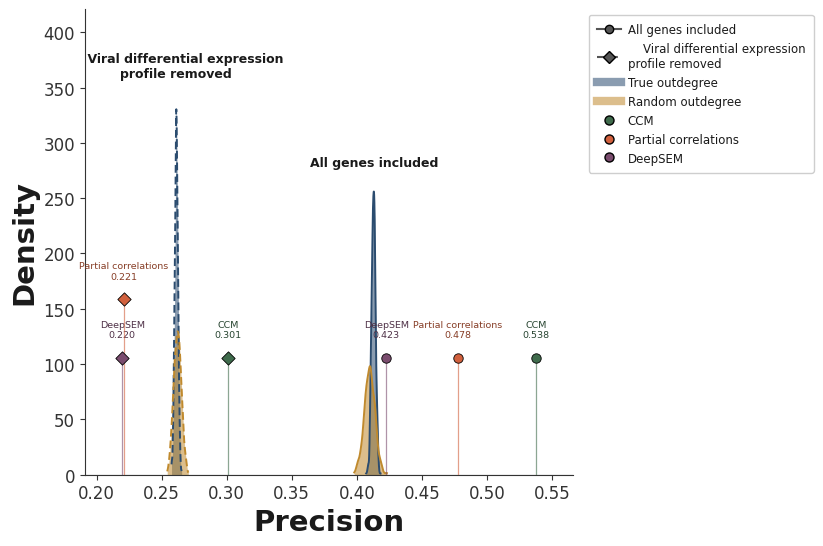

In [293]:
plot_precision_null_combo(
    Comparanda,
    baseprec,
    pcorr,
    semprec,
    basenogfp,
    pcorrnogfp,
    semnogfp,
    all_genes_true_col="WithGFP_true",
    all_genes_random_col="WithGFP_RandomDeg",
    viral_removed_true_col="NoGFP_true",
    viral_removed_random_col="NoGFP_RandomDeg",
    ax=None,
    figsize=(8.4, 5.6),
    kde_points=1000,
    fill_alpha=0.55,
    dot_height_frac=0.32,
    stack_step_frac=0.16,
    value_fontsize=6.8,
    panel_label=None,
)
plt.savefig('./newfigures/PrecNullCombo.pdf',bbox_inches='tight')

## Panel F

In [294]:
cns2=DataDict['Figure2']['ComparativeNetworkStatistics']
cns2.head()

,index,Gene,NumDEGenes,NumCCMTargets,NumOverlapping,NumNeither,OddsRatio,pvals
0,0,ANXA2,96,77,8,848,1.117260,0.448805
2,3,MRPS2,393,159,49,510,0.660412,0.990924
4,5,MAP3K12,288,68,14,671,0.634901,0.951397
6,7,DNPEP,295,154,37,601,0.736666,0.947880
7,8,UBE2J2,328,161,43,567,0.724978,0.963008


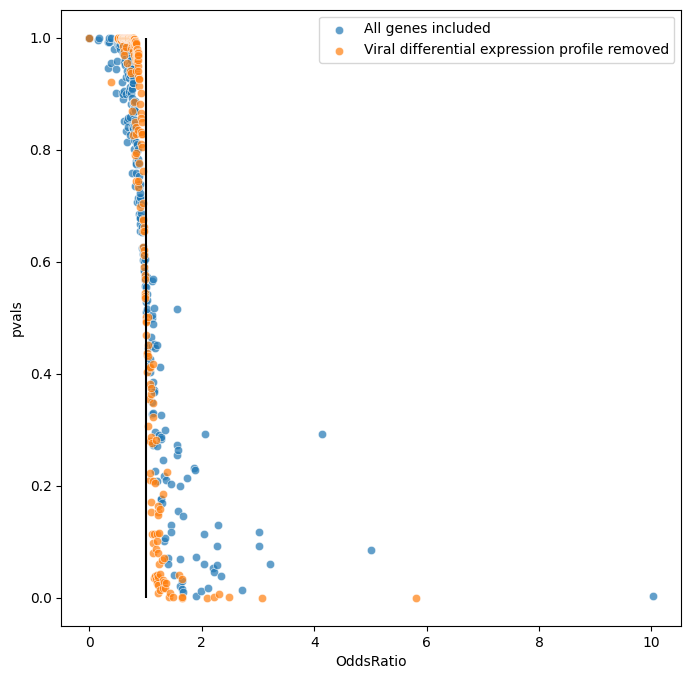

In [63]:
fig,ax=plt.subplots(figsize=(8,8))
sns.scatterplot(data=cns2.sort_values('OddsRatio'),x='OddsRatio',y='pvals',alpha=0.7)
sns.scatterplot(data=sumdf.sort_values('OddsRatio'),x='OddsRatio',y='pvals',alpha=0.7)

plt.vlines(1,0,1,'k')
plt.legend(['All genes included','Viral differential expression profile removed'])
plt.savefig('./figures/FisherOddsCombo.pdf')
plt.show()

### Claude glow-up

In [297]:
"""
Figure 2, Panel F -- Fisher Exact test results (odds ratio vs. p-value) for
gene-set enrichment, compared between "all genes included" and "viral
differential expression profile removed" -- the same two conditions as
Panel E.

Real figure-generating code (safe to publish). Same inputs as the
original:

    sns.scatterplot(data=cns2.sort_values('OddsRatio'), x='OddsRatio', y='pvals', alpha=0.7)
    sns.scatterplot(data=sumdf.sort_values('OddsRatio'), x='OddsRatio', y='pvals', alpha=0.7)
    plt.vlines(1, 0, 1, 'k')
    plt.legend(['All genes included', 'Viral differential expression profile removed'])

('cns2' = "all genes included"; 'sumdf' = "viral differential expression
profile removed" -- same condition pair and order as Panel E's
baseprec/basenogfp etc.)



Usage:

    import paper_style as style
    from fig2_panelF_fisher_odds import plot_fisher_odds_combo

    style.apply()
    fig, ax = plot_fisher_odds_combo(cns2, sumdf, panel_label="f")
    fig.savefig("Figure2_PanelF_fisher_odds.pdf", bbox_inches="tight")

See _preview_fisher_odds.py for the synthetic-data smoke test (not for
publication).
"""

from __future__ import annotations

import matplotlib.pyplot as plt
import matplotlib.lines as mlines

import paper_style as style

ALL_GENES_COLOR = style.INK_BLUE
VIRAL_REMOVED_COLOR = style.TERRACOTTA
ALL_GENES_MARKER = "o"
VIRAL_REMOVED_MARKER = "D"


def plot_fisher_odds_combo(
    all_genes_df,
    viral_removed_df,
    x_col="OddsRatio",
    y_col="pvals",
    all_genes_label="All genes included",
    viral_removed_label="Viral differential expression profile removed",
    ax=None,
    figsize=(7.2, 6.2),
    point_size=42,
    alpha=0.7,
    null_odds_ratio=1.0,
    panel_label=None,
):
    """Fisher Exact odds-ratio-vs-p-value scatter for the two gene sets.
    See module docstring for the full rationale.

    all_genes_df / viral_removed_df: dataframes with x_col/y_col columns
    (defaults match the original 'OddsRatio'/'pvals'). Order matches the
    original code's cns2 (all genes included) then sumdf (viral DE
    profile removed).
    """
    if ax is None:
        fig, ax = plt.subplots(figsize=figsize)
    else:
        fig = ax.figure

    ax.axvline(null_odds_ratio, color=style.REFERENCE_LINE_COLOR, linestyle="--",
               linewidth=1.2, zorder=2)

    common = dict(s=point_size, alpha=alpha, linewidth=0.5, rasterized=True)
    ax.scatter(
        all_genes_df[x_col], all_genes_df[y_col], color=ALL_GENES_COLOR,
        marker=ALL_GENES_MARKER, edgecolor=style.darken(ALL_GENES_COLOR, 0.3),
        zorder=3, **common,
    )
    ax.scatter(
        viral_removed_df[x_col], viral_removed_df[y_col], color=VIRAL_REMOVED_COLOR,
        marker=VIRAL_REMOVED_MARKER, edgecolor=style.darken(VIRAL_REMOVED_COLOR, 0.3),
        zorder=4, **common,
    )

    ax.set_xlabel("Fisher Exact Odds Ratio")
    ax.set_ylabel(r"Fisher Exact $\it{p}$-value")
    style.despine_clean(ax)

    legend_handles = [
        mlines.Line2D([], [], marker=ALL_GENES_MARKER, linestyle="none", markersize=7,
                      markerfacecolor=ALL_GENES_COLOR, markeredgecolor=style.darken(ALL_GENES_COLOR, 0.3),
                      label=all_genes_label),
        mlines.Line2D([], [], marker=VIRAL_REMOVED_MARKER, linestyle="none", markersize=7,
                      markerfacecolor=VIRAL_REMOVED_COLOR, markeredgecolor=style.darken(VIRAL_REMOVED_COLOR, 0.3),
                      label=viral_removed_label),
    ]
    ax.legend(
        handles=legend_handles, loc="upper right", frameon=True, framealpha=0.95,
        edgecolor="#cccccc", fontsize=8.5, handletextpad=0.6, borderpad=0.7,
    )

    if panel_label:
        ax.text(-0.1, 1.02, panel_label, transform=ax.transAxes, fontsize=14,
                fontweight="bold", va="bottom", ha="left")

    fig.tight_layout()
    return fig, ax


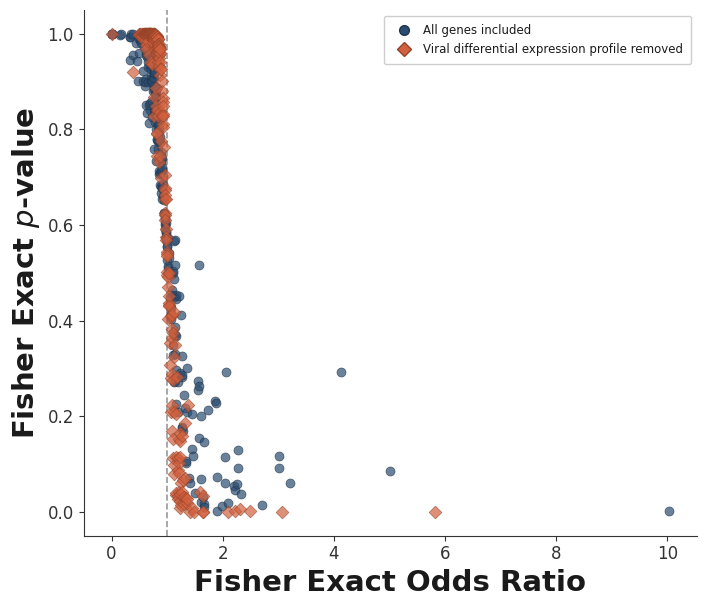

In [298]:
plot_fisher_odds_combo(
    cns2.sort_values('OddsRatio'),
    sumdf.sort_values('OddsRatio'),
    x_col="OddsRatio",
    y_col="pvals",
    all_genes_label="All genes included",
    viral_removed_label="Viral differential expression profile removed",
    ax=None,
    figsize=(7.2, 6.2),
    point_size=42,
    alpha=0.7,
    null_odds_ratio=1.0,
    panel_label=None,
)
plt.savefig('./newfigures/FisherOddsCombo.pdf',bbox_inches='tight')

# Figure 3

Panel A was made in Inkscape

In [299]:
with open('LibLabelDict.pkl','rb') as test:
    liblabeldict=pickle.load(test)
liblabeldict.keys()

dict_keys(['color', 'tritile'])

In [300]:
# fix liblabel tritile
lld={}
for key in liblabeldict['tritile'].keys():
    if liblabeldict['tritile'][key]=='_ ':
        lld[key]='- '
    else:
        lld[key]=liblabeldict['tritile'][key]
lld['OLD']=''; lld['YOUNG']=''
lld['P16']='C '; lld['DNAJB12']='/ '; lld['C5ORF24']='- '; lld['NFIX']='- '; lld['MARK3']='/ '
lld['YARS']='/ '; lld['DDX49']='/ '; lld['H3-M']='C '; lld['CDC42EP3']='- '; lld['C6ORF106']='/ '
lld['SIRT6']='C '; lld['HNRNPK']='/ '; lld['C12ORF10']='- '; lld['GABARAP']='\\ '; lld['USO1']='\\ '
lld['TEX261']='- '; lld['EFTUD2']='/ '; lld['FADD']='_ '
liblabeldict['tritile']=lld


liblabeldict['color']['OLD']='k'; liblabeldict['color']['YOUNG']='k'
liblabeldict['color']['P16']='k'; liblabeldict['color']['DNAJB12']='k'; liblabeldict['color']['C5ORF24']='k'; liblabeldict['color']['NFIX']='k'; liblabeldict['color']['MARK3']='k'
liblabeldict['color']['YARS']='k'; liblabeldict['color']['DDX49']='k'; liblabeldict['color']['H3-M']='k'; liblabeldict['color']['CDC42EP3']='k'; liblabeldict['color']['C6ORF106']='k'
liblabeldict['color']['SIRT6']='k'; liblabeldict['color']['HNRNPK']='k'; liblabeldict['color']['C12ORF10']='k'; liblabeldict['color']['GABARAP']='k'; liblabeldict['color']['USO1']='k'
liblabeldict['color']['TEX261']='k'; liblabeldict['color']['EFTUD2']='k'; liblabeldict['color']['FADD']='k'

## Panel B

In [301]:
sumdf=DataDict['Figure3']['RankScores_and_Other_Gene_Info']
sumdf.head()

,Gene,RNAYS,RNA_AbFrac,YouthScore_Hybrid,MasterScore,MeanMito%,StdMito%,MeanRibo%,StdRibo%,MeanMalat%,...,NumNeither,OddsRatio,pvals,scRNA_cellcount,Master Score tritile,TF/surface marker/secreted factor,Reactome: Cellular responses to stimuli,Reactome: Intracellular core functions,Reactome: Immune system,CellCountCP
0,ANXA2,0.236025,0.069364,0.180877,-0.021485,1.625959,0.573768,0.944102,0.313470,2.361226,...,3816.0,1.645974,1.131976e-07,519.0,control,Secreted Factor,0.0,0.0,0.0,1665.0
1,OLD,0.247183,0.067234,0.145214,NaN,1.246700,0.438352,1.075207,0.388175,2.029116,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,139533.0
2,YOUNG,0.767124,0.071813,0.885398,NaN,1.318644,0.543593,1.146731,0.407127,2.057075,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,41162.0
3,TP53,0.336058,0.084910,0.181916,0.000367,1.583803,0.672274,1.184535,0.390952,1.508459,...,2010.0,0.819962,7.438840e-01,2273.0,control,Transcription Factor,0.0,0.0,0.0,3791.0
4,MRPS2,0.204873,0.059401,0.089199,0.239430,1.072958,0.924759,1.112192,0.428831,1.800366,...,1641.0,0.791076,9.970685e-01,2138.0,negative,NaN,0.0,1.0,0.0,1883.0


In [306]:
#rnadf=sumdf[(~sumdf.RNAYS.isna())&(~sumdf.MasterScore.isna())]
rnadf=sumdf[(~sumdf.RNAYS.isna())]
rnadf['Transcriptomic YouthScore']=rnadf['RNAYS']

<ipython-input-306-1dafb2367119>:3: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  rnadf['Transcriptomic YouthScore']=rnadf['RNAYS']


<ipython-input-303-0d9555d770d9>:11: UserWarning: FixedFormatter should only be used together with FixedLocator
  ax.set_xticklabels(newlabels)


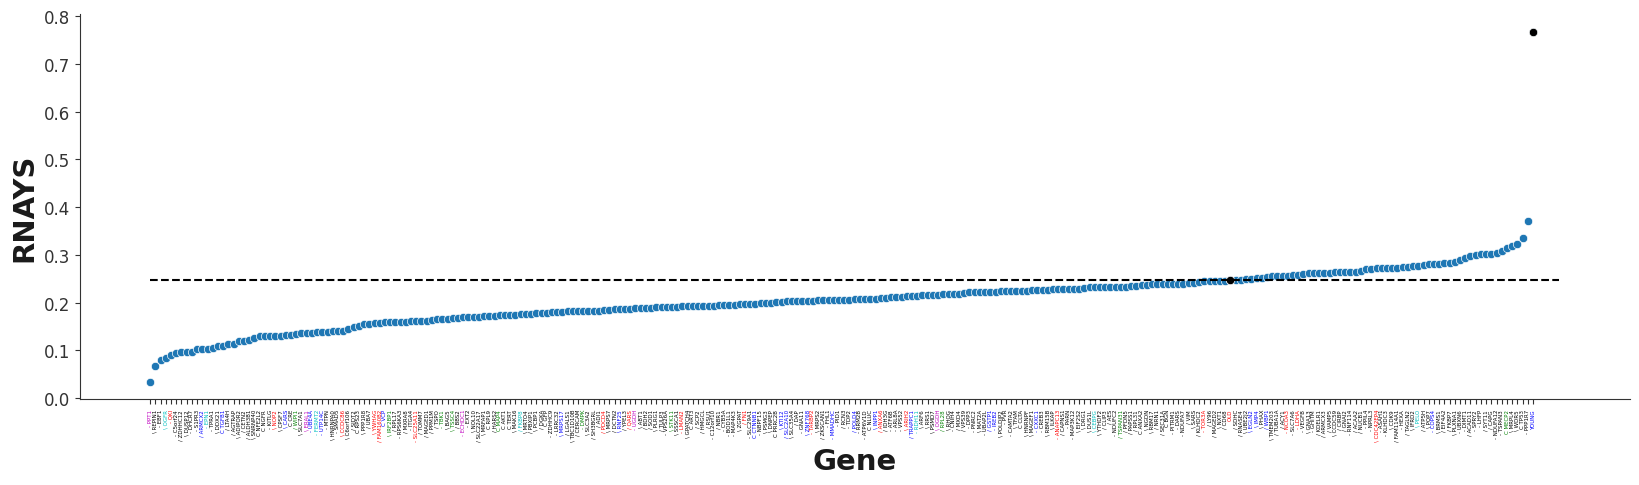

In [303]:
fig,ax=plt.subplots(figsize=(20,5))
sns.scatterplot(data=rnadf.sort_values('RNAYS'),x='Gene',y='RNAYS')
sns.scatterplot(data=rnadf[rnadf.Gene.isin(['OLD','YOUNG'])].sort_values('RNAYS'),x='Gene',y='RNAYS',color='k')

plt.xticks(rotation=90,fontsize=4);
plt.hlines(0.2472,0,270,linestyle='--',color='k')

labels = [item.get_text() for item in ax.get_xticklabels()]
newlabels= [liblabeldict['tritile'][i]+i for i in labels]

ax.set_xticklabels(newlabels)

for ticknum in range(len(rnadf.Gene)):
    ax.get_xticklabels()[ticknum].set_color(liblabeldict['color'][rnadf.Gene.values[ticknum]])
    
plt.savefig('./figures/RNAYS.pdf')
plt.show()

### Claude glow-up

In [304]:
"""
Figure 3, Panel B -- per-gene RNAYS "waterfall" (genes ranked by score,
symbol- and color-coded by two independent annotations), with the 'OLD'
and 'YOUNG' reference genes called out as distinguished points.

This panel is deliberately built as a close sibling of Fig2 Panel A's
MasterScore waterfall (fig2_panelA_masterscore.py) -- same `liblabeldict`
symbol-prefix / label-color convention, same overall layout -- so the two
read as one visual family across figures, per your note that they should
stay similar. The differences are additive, not a different design:

Real figure-generating code (safe to publish). Statistically identical to
the original:

    fig, ax = plt.subplots(figsize=(20, 5))
    sns.scatterplot(data=rnadf.sort_values('RNAYS'), x='Gene', y='RNAYS')
    sns.scatterplot(data=rnadf[rnadf.Gene.isin(['OLD', 'YOUNG'])].sort_values('RNAYS'),
                     x='Gene', y='RNAYS', color='k')
    plt.xticks(rotation=90, fontsize=4)
    plt.hlines(0.2472, 0, 270, linestyle='--', color='k')
    labels = [item.get_text() for item in ax.get_xticklabels()]
    newlabels = [liblabeldict['tritile'][i] + i for i in labels]
    ax.set_xticklabels(newlabels)
    for ticknum in range(len(rnadf.Gene)):
        ax.get_xticklabels()[ticknum].set_color(liblabeldict['color'][rnadf.Gene.values[ticknum]])

Same data, same sort order, same per-gene symbol-prefix and label-color
lookups (`symbol_map` / `color_map` are exactly `liblabeldict['tritile']` /
`liblabeldict['color']`, same as Fig2 A) -- this function doesn't change
what they encode, only how the figure is rendered around them.



Usage:

    import paper_style as style
    from fig3_panelB_rnays import plot_rnays_waterfall

    style.apply()
    fig, ax = plot_rnays_waterfall(
        rnadf,
        symbol_map=liblabeldict['tritile'],
        color_map=liblabeldict['color'],
        reference_line_y=0.2472,
        panel_label="b",
    )
    fig.savefig("Figure3_PanelB_rnays.pdf", bbox_inches="tight")

See _preview_rnays_waterfall.py for the synthetic-data smoke test (not for
publication).
"""

from __future__ import annotations

import matplotlib.pyplot as plt
from matplotlib.lines import Line2D

import paper_style as style


DEFAULT_SYMBOL_LABELS = {
    "/": "increasing expression with age",
    "\\": "decreasing expression with age",
    "-": "no change with age",
    "C": "control gene",
}

# Placeholder hex values -- replace with whatever color_map actually uses
# for these three categories (or pass category_labels= explicitly). Kept
# identical to Fig2 A's defaults since this is the same lookup convention.
DEFAULT_CATEGORY_LABELS = {
    "#3b4cc0": "Reactome: Cellular responses to stimuli",
    "#b40426": "Reactome: Immune system",
    "#2c7c2c": "Reactome: Intracellular core functions",
}


def plot_rnays_waterfall(
    rnadf,
    symbol_map,
    color_map,
    gene_col="Gene",
    score_col="RNAYS",
    highlighted_genes=("OLD", "YOUNG"),
    highlighted_color="#000000",
    highlighted_size_mult=4.0,
    guideline_alpha=0.55,
    reference_line_y=None,
    symbol_labels=None,
    category_labels=None,
    ax=None,
    figsize=(20, 5),
    point_color=None,
    point_size=18,
    tick_fontsize=4,
    panel_label=None,
):
    """Recreate the RNAYS gene-rank scatter with house styling applied,
    matching Fig2 Panel A's design plus extra-visible 'OLD'/'YOUNG' points.

    point_color defaults to the shared house SLATE, since each regular dot
    here is a single raw observation (one gene) -- same convention as
    Fig2 A. highlighted_genes are drawn larger, in `highlighted_color`
    (black, matching the original), each with its own full-height dashed
    guide line through its x-position.

    symbol_map / color_map are per-gene lookups exactly like the original
    `liblabeldict['tritile']` / `liblabeldict['color']`. `symbol_labels` /
    `category_labels` only feed the rebuilt legend text.
    """
    point_color = point_color or style.SLATE
    symbol_labels = symbol_labels or DEFAULT_SYMBOL_LABELS
    category_labels = (
        category_labels if category_labels is not None else DEFAULT_CATEGORY_LABELS
    )
    highlighted_genes = set(highlighted_genes)

    plot_df = rnadf.sort_values(score_col)
    genes = plot_df[gene_col].tolist()
    scores = plot_df[score_col].values

    if ax is None:
        fig, ax = plt.subplots(figsize=figsize)
    else:
        fig = ax.figure

    # Guide lines drawn first (lowest zorder) so they run BEHIND every
    # point rather than obscuring anything.
    for gene in highlighted_genes:
        if gene not in genes:
            continue
        x = genes.index(gene)
        ax.axvline(x, color=style.REFERENCE_LINE_COLOR, linestyle="--",
                   linewidth=1.1, alpha=guideline_alpha, zorder=1)

    if reference_line_y is not None:
        ax.axhline(reference_line_y, color=style.REFERENCE_LINE_COLOR,
                   linestyle="--", linewidth=1.2, zorder=2)

    ax.scatter(
        range(len(genes)), scores, s=point_size, color=point_color,
        edgecolor=style.darken(point_color, 0.3), linewidth=0.4, zorder=3,
    )

    # 'OLD' / 'YOUNG' re-plotted larger and on top, same as the original's
    # second sns.scatterplot call -- just bigger this time, per your ask.
    hi_x = [i for i, g in enumerate(genes) if g in highlighted_genes]
    hi_y = [scores[i] for i in hi_x]
    if hi_x:
        ax.scatter(
            hi_x, hi_y, s=point_size * highlighted_size_mult, color=highlighted_color,
            edgecolor=style.darken(highlighted_color, 0.3) if highlighted_color != "#000000" else "#000000",
            linewidth=0.6, zorder=5,
        )

    ax.set_xticks(range(len(genes)))
    tick_labels = [symbol_map.get(g, "") + g for g in genes]
    ax.set_xticklabels(tick_labels, rotation=90, fontsize=tick_fontsize)
    for tick, gene in zip(ax.get_xticklabels(), genes):
        gene_color = color_map.get(gene)
        if gene_color:
            tick.set_color(gene_color)
        if gene in highlighted_genes:
            tick.set_fontweight("bold")

    ax.set_xlabel("Gene")
    ax.set_ylabel(score_col)
    ax.set_xlim(-1, len(genes))
    style.despine_clean(ax)

    # Rebuild the legend the original had (symbol key + Reactome-category
    # color key), identical to Fig2 A's approach: invisible handles, text
    # colored per entry instead of swatches.
    handles = []
    entry_colors = []
    for symbol, text in symbol_labels.items():
        handles.append(Line2D([], [], linestyle="none", marker="none"))
        entry_colors.append(("#1a1a1a", f"{symbol}: {text}"))
    for hex_color, text in category_labels.items():
        handles.append(Line2D([], [], linestyle="none", marker="none"))
        entry_colors.append((hex_color, text))

    legend = ax.legend(
        handles,
        [label for _, label in entry_colors],
        loc="upper left",
        frameon=True,
        framealpha=0.9,
        edgecolor="#cccccc",
        fontsize=7,
        handlelength=0,
        handletextpad=0,
        borderpad=0.6,
    )
    for text_obj, (color, _) in zip(legend.get_texts(), entry_colors):
        text_obj.set_color(color)

    if panel_label:
        ax.text(
            -0.03,
            1.06,
            panel_label,
            transform=ax.transAxes,
            fontsize=14,
            fontweight="bold",
            va="bottom",
            ha="left",
        )

    fig.tight_layout()
    return fig, ax


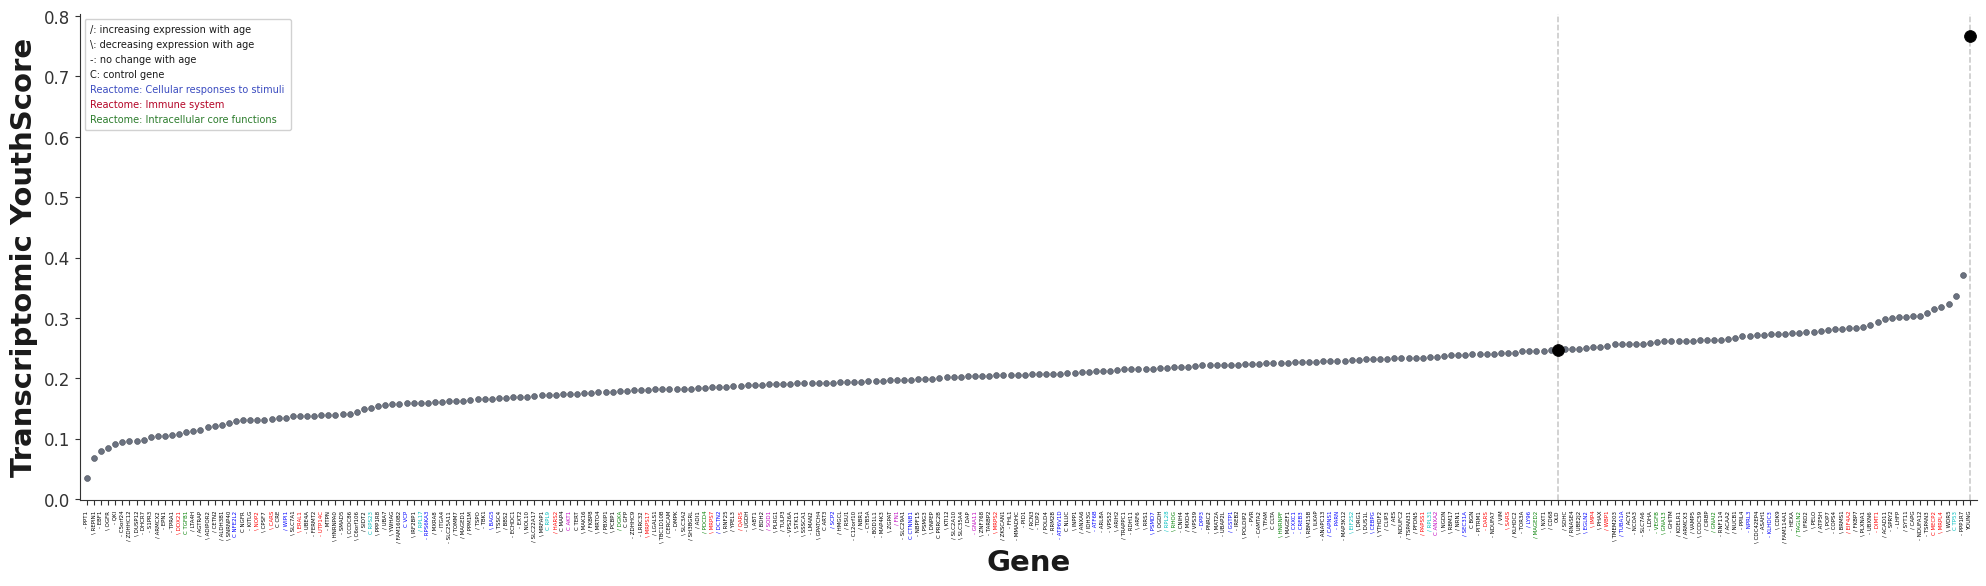

In [308]:
plot_rnays_waterfall(
    rnadf,
    liblabeldict['tritile'],
    liblabeldict['color'],
    gene_col="Gene",
    score_col="Transcriptomic YouthScore",
    highlighted_genes=("OLD", "YOUNG"),
    highlighted_color="#000000",
    highlighted_size_mult=4.0,
    guideline_alpha=0.55,
    reference_line_y=None,
    symbol_labels=None,
    category_labels=None,
    ax=None,
    figsize=(20, 6),
    point_color=None,
    point_size=18,
    tick_fontsize=4,
    panel_label=None,
)
plt.savefig('./newfigures/RNAYS.pdf',bbox_inches='tight')

## Panel C

In [309]:
sumdf=DataDict['Figure3']['RankScores_and_Other_Gene_Info']
sumdf.head()

,Gene,RNAYS,RNA_AbFrac,YouthScore_Hybrid,MasterScore,MeanMito%,StdMito%,MeanRibo%,StdRibo%,MeanMalat%,...,NumNeither,OddsRatio,pvals,scRNA_cellcount,Master Score tritile,TF/surface marker/secreted factor,Reactome: Cellular responses to stimuli,Reactome: Intracellular core functions,Reactome: Immune system,CellCountCP
0,ANXA2,0.236025,0.069364,0.180877,-0.021485,1.625959,0.573768,0.944102,0.313470,2.361226,...,3816.0,1.645974,1.131976e-07,519.0,control,Secreted Factor,0.0,0.0,0.0,1665.0
1,OLD,0.247183,0.067234,0.145214,NaN,1.246700,0.438352,1.075207,0.388175,2.029116,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,139533.0
2,YOUNG,0.767124,0.071813,0.885398,NaN,1.318644,0.543593,1.146731,0.407127,2.057075,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,41162.0
3,TP53,0.336058,0.084910,0.181916,0.000367,1.583803,0.672274,1.184535,0.390952,1.508459,...,2010.0,0.819962,7.438840e-01,2273.0,control,Transcription Factor,0.0,0.0,0.0,3791.0
4,MRPS2,0.204873,0.059401,0.089199,0.239430,1.072958,0.924759,1.112192,0.428831,1.800366,...,1641.0,0.791076,9.970685e-01,2138.0,negative,NaN,0.0,1.0,0.0,1883.0


In [312]:
rnadf=sumdf[(~sumdf.RNAYS.isna())&(sumdf.Gene!='YOUNG')]
rnadf['Transcriptomic YouthScore']=rnadf['RNAYS']

<ipython-input-312-d040107d83fd>:2: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  rnadf['Transcriptomic YouthScore']=rnadf['RNAYS']


In [311]:
print(stats.pearsonr(rnadf.RNAYS,rnadf['MeanRibo%']))
print(stats.pearsonr(rnadf.RNAYS,rnadf['MeanMito%']))

PearsonRResult(statistic=0.44721628653253176, pvalue=1.953740074050269e-14)
PearsonRResult(statistic=0.10896433749133111, pvalue=0.07661033291023117)


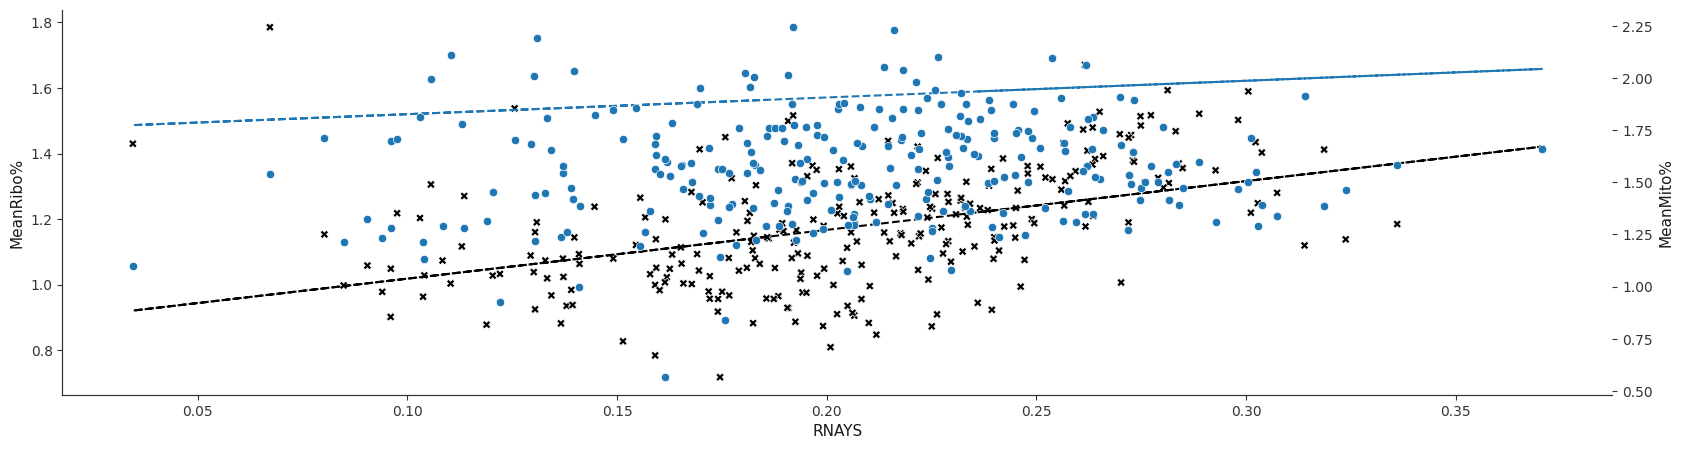

In [333]:
## NOTE -- Claude discovered an inherent bug in the original formulation of the plot -- the second curve (the MeanRibo% curve) is actually 
# plotted such that its y-values are on the PRIMARY axis (the MeanMito% one). So the black line below is actually much steeper, as reflected
# in the publication-shipped figure. 

fig,ax=plt.subplots(figsize=(20,5))
g=sns.scatterplot(data=rnadf,x='RNAYS',y='MeanRibo%',color='k',style='Gene',markers=['X' for i in rnadf.RNAYS],legend=False)
sns.scatterplot(data=rnadf,x='RNAYS',y='MeanMito%',ax=g.axes.twinx())
ax.plot(rnadf.RNAYS,np.poly1d(np.polyfit(rnadf.RNAYS, rnadf['MeanMito%'], 1))(rnadf.RNAYS),linestyle='--', color='C0')
ax.plot(rnadf.RNAYS,np.poly1d(np.polyfit(rnadf.RNAYS, rnadf['MeanRibo%'], 1))(rnadf.RNAYS),linestyle='--', color='k')

plt.savefig('./figures/MitoRiboYS.pdf')

### Claude glow-up

In [313]:
"""
Figure 3, Panel C -- ribosomal and mitochondrial transcript density vs.
Transcriptomic YouthScore, on a shared x-axis with two independent y-axes
(one per transcript-density measure), each annotated with its own Pearson
correlation.

Original figure-generating code:

    fig,ax=plt.subplots(figsize=(20,5))
    g=sns.scatterplot(data=rnadf,x='RNAYS',y='MeanRibo%',color='k',style='Gene',
                       markers=['X' for i in rnadf.RNAYS],legend=False)
    sns.scatterplot(data=rnadf,x='RNAYS',y='MeanMito%',ax=g.axes.twinx())
    ax.plot(rnadf.RNAYS,np.poly1d(np.polyfit(rnadf.RNAYS, rnadf['MeanMito%'], 1))(rnadf.RNAYS),
            linestyle='--', color='C0')
    ax.plot(rnadf.RNAYS,np.poly1d(np.polyfit(rnadf.RNAYS, rnadf['MeanRibo%'], 1))(rnadf.RNAYS),
            linestyle='--', color='k')


Usage:

    import paper_style as style
    from fig3_panelC_ribomito import plot_ribo_mito_youthscore

    style.apply()
    fig, ax, ax2 = plot_ribo_mito_youthscore(rnadf, panel_label="c")
    fig.savefig("Figure3_PanelC_ribomito.pdf", bbox_inches="tight")

See _preview_ribomito.py for the synthetic-data smoke test (not for
publication).
"""

from __future__ import annotations

import numpy as np
import matplotlib.pyplot as plt
from scipy import stats

import paper_style as style

RIBO_COLOR = "#1a1a1a"     # same value as rcParams text.color -- kept from
                            # the original's black, reads as the "default"
                            # axis so only the Mito side needs to visually
                            # announce itself as the "other" scale
MITO_COLOR = style.INK_BLUE


def plot_ribo_mito_youthscore(
    rnadf,
    score_col="RNAYS",
    ribo_col="MeanRibo%",
    mito_col="MeanMito%",
    ribo_color=RIBO_COLOR,
    mito_color=MITO_COLOR,
    score_label="Transcriptomic YouthScore",
    ribo_label="Ribosomal transcript density",
    mito_label="Mitochondrial transcript density",
    ribo_marker="x",
    mito_marker="o",
    point_size=16,
    ax=None,
    figsize=(20, 5),
    annotate_fontsize=13,
    annotate_x_frac=0.985,
    mito_annotate_y_frac=0.95,
    ribo_annotate_y_frac=0.78,
    panel_label=None,
):
    """Recreate the ribo/mito transcript-density-vs-YouthScore dual-axis
    scatter with house styling: color-coded axes, per-series fit lines
    drawn on their OWN axis, and an on-plot Pearson annotation per series.

    Returns (fig, ax, ax2) -- ax is the Ribo (left) axis, ax2 the Mito
    (right) twin axis, in case the caller wants to tweak either further.
    """
    if ax is None:
        fig, ax = plt.subplots(figsize=figsize)
    else:
        fig = ax.figure
    ax2 = ax.twinx()

    x = rnadf[score_col].to_numpy(dtype=float)
    ribo = rnadf[ribo_col].to_numpy(dtype=float)
    mito = rnadf[mito_col].to_numpy(dtype=float)
    order = np.argsort(x)
    x_sorted = x[order]

    rho_ribo, p_ribo = stats.pearsonr(x, ribo)
    rho_mito, p_mito = stats.pearsonr(x, mito)
    ribo_fit = np.poly1d(np.polyfit(x, ribo, 1))
    mito_fit = np.poly1d(np.polyfit(x, mito, 1))

    # Points first (low zorder), fit lines on top of points but under text.
    ax.scatter(x, ribo, marker=ribo_marker, s=point_size, color=ribo_color,
               linewidth=0.9, alpha=0.85, zorder=3)
    ax2.scatter(x, mito, marker=mito_marker, s=point_size, color=mito_color,
                edgecolor=style.darken(mito_color, 0.25), linewidth=0.3,
                alpha=0.7, zorder=3)

    # Each fit line drawn on ITS OWN axis -- see docstring point 3 above;
    # the original drew both on the primary axis.
    ax.plot(x_sorted, ribo_fit(x_sorted), linestyle="--", color=ribo_color,
             linewidth=1.6, zorder=4)
    ax2.plot(x_sorted, mito_fit(x_sorted), linestyle="--", color=mito_color,
              linewidth=1.6, zorder=4)

    # Small x-padding so the fit lines/points aren't flush against the frame.
    xpad = 0.02 * (x.max() - x.min())
    ax.set_xlim(x.min() - xpad, x.max() + xpad)

    # Stats annotations: FIXED axes-fraction positions, not tied to either
    # fit line's actual data value -- see v2 fix A in the module docstring
    # for why (the two lines can converge on real data and the old
    # data-anchored placement let their labels collide). ax/ax2 share the
    # same bounding box under twinx(), so ax.transAxes is valid for both.
    # A translucent white backing box keeps each label legible regardless
    # of whichever fit line or data points happen to pass behind it.
    label_bbox = dict(boxstyle="round,pad=0.28", facecolor="white",
                       edgecolor="none", alpha=0.82)
    ax.text(annotate_x_frac, mito_annotate_y_frac, style.fmt_pearson(rho_mito, p_mito),
             transform=ax.transAxes, color=mito_color, ha="right", va="top",
             fontsize=annotate_fontsize, zorder=6, bbox=label_bbox)
    ax.text(annotate_x_frac, ribo_annotate_y_frac, style.fmt_pearson(rho_ribo, p_ribo),
             transform=ax.transAxes, color=ribo_color, ha="right", va="top",
             fontsize=annotate_fontsize, zorder=6, bbox=label_bbox)

    ax.set_xlabel(score_label)
    ax.set_ylabel(ribo_label)
    ax2.set_ylabel(mito_label)
    style.despine_twin(ax, ax2, ribo_color, mito_color)

    if panel_label:
        ax.text(-0.03, 1.06, panel_label, transform=ax.transAxes, fontsize=14,
                 fontweight="bold", va="bottom", ha="left")

    fig.tight_layout()
    return fig, ax, ax2


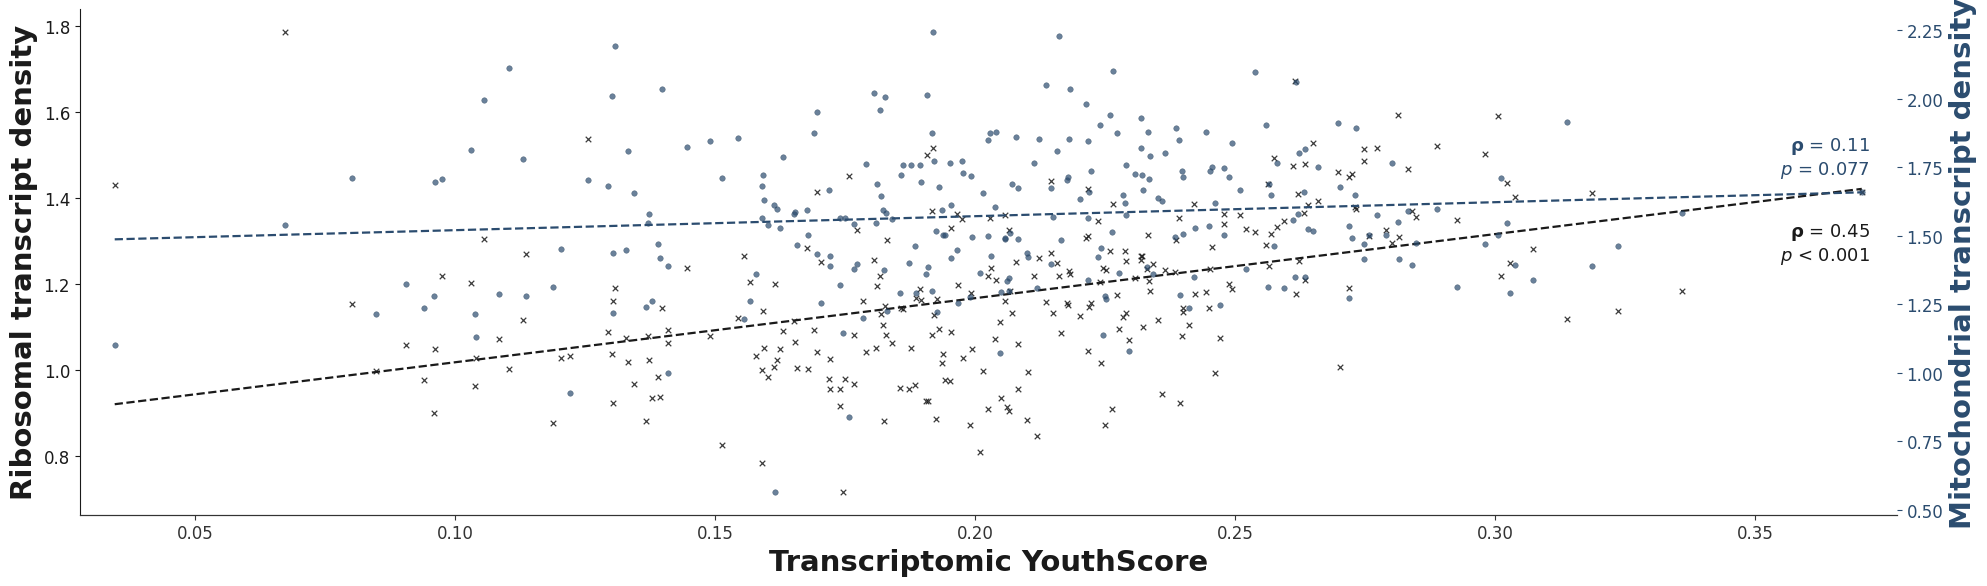

In [315]:
plot_ribo_mito_youthscore(
    rnadf,
    score_col="RNAYS",
    ribo_col="MeanRibo%",
    mito_col="MeanMito%",
    ribo_color=RIBO_COLOR,
    mito_color=MITO_COLOR,
    score_label="Transcriptomic YouthScore",
    ribo_label="Ribosomal transcript density",
    mito_label="Mitochondrial transcript density",
    ribo_marker="x",
    mito_marker="o",
    point_size=16,
    ax=None,
    figsize=(20, 6),
    annotate_fontsize=13,
    annotate_x_frac=0.985,
    mito_annotate_y_frac=0.75,
    ribo_annotate_y_frac=0.58,
    panel_label=None,
)
plt.savefig('./newfigures/MitoRiboYS.pdf')

## Panel D

In [25]:
DataDict['Figure3'].keys()

dict_keys(['RankScores_and_Other_Gene_Info', 'SignedClassifierFeatures'])

In [27]:
ClassFeatures=DataDict['Figure3']['SignedClassifierFeatures']
print(len(ClassFeatures))
ClassFeatures.head()

8114


,Gene,Importance,SignedImportance
3684,PRRG4,0.094117,-0.094117
1298,MPPED2,0.053092,0.053092
1196,CYTL1,0.039705,0.039705
3470,ADGRG7,0.036995,-0.036995
2156,SERPINE2,0.034728,0.034728


In [28]:
CFsmall=ClassFeatures.iloc[:50,:]

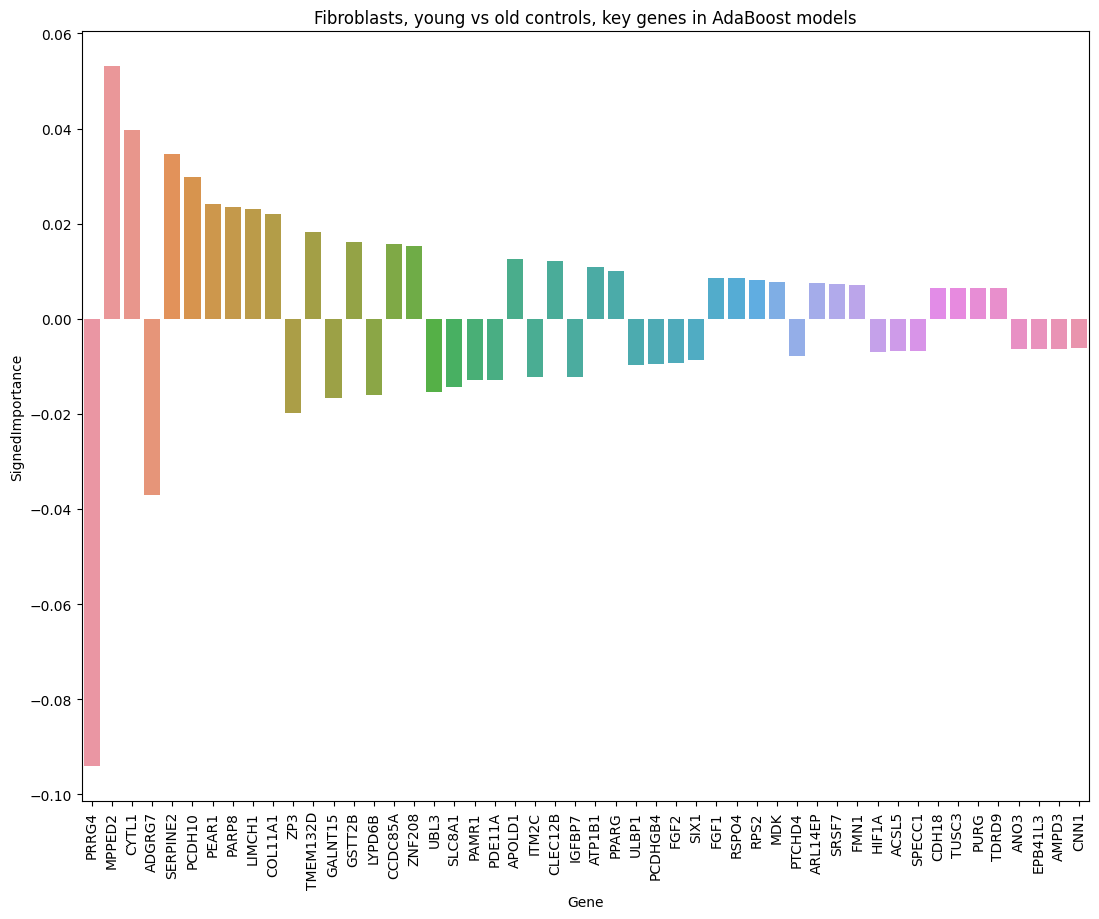

In [30]:
#plt.plot(figsize=(13,10))
fig, ax = plt.subplots(figsize=(13,10))
sns.barplot(CFsmall,x='Gene',y='SignedImportance')
plt.xticks(rotation=90)
plt.title('Fibroblasts, young vs old controls, key genes in AdaBoost models')
plt.savefig('./figures/FeatureImportance_RNA_signed.pdf')
plt.show()

In [33]:
enr = gseapy.enrichr(
    gene_list=list(ClassFeatures[ClassFeatures.Importance>0].Gene.values),                              # or "./tests/data/gene_list.txt"
    gene_sets=['Reactome_2022'],
    background=AllAdaGenes.Gene.values,
    outdir=None,                                       # keep results in memory only
)
enr.results

,Gene_set,Term,P-value,Adjusted P-value,Old P-value,Old adjusted P-value,Odds Ratio,Combined Score,Genes
0,Reactome_2022,Transport Of Small Molecules R-HSA-382551,0.000069,0.036687,0,0,3.420374,32.773980,ABCC4;ATP8B4;TUSC3;SLC39A10;ATP1B1;SLC8A1;ANO3...
1,Reactome_2022,Cellular Responses To Stress R-HSA-2262752,0.000197,0.049828,0,0,4.089274,34.886883,RPL7A;PSMD5;HSPA4L;ATP6V1B2;GPX7;IGFBP7;NOX5;R...
2,Reactome_2022,Cellular Responses To Stimuli R-HSA-8953897,0.000281,0.049828,0,0,3.912281,31.991520,RPL7A;PSMD5;HSPA4L;ATP6V1B2;GPX7;IGFBP7;NOX5;R...
3,Reactome_2022,Glutathione Conjugation R-HSA-156590,0.001071,0.142421,0,0,18.820331,128.718209,GSTM4;GSTT2B;GSTM5
4,Reactome_2022,Signaling By Hippo R-HSA-2028269,0.001833,0.195064,0,0,56.112676,353.601440,TJP1;SAV1
...,...,...,...,...,...,...,...,...,...
527,Reactome_2022,Leishmania Infection R-HSA-9658195,0.880981,0.887655,0,0,0.469368,0.059478,CALCRL
528,Reactome_2022,Signaling By GPCR R-HSA-372790,0.969423,0.974920,0,0,0.424972,0.013197,PDE11A;FZD2;CALCRL
529,Reactome_2022,GPCR Ligand Binding R-HSA-500792,0.973882,0.977557,0,0,0.357616,0.009464,FZD2;CALCRL
530,Reactome_2022,GPCR Downstream Signaling R-HSA-388396,0.985484,0.987340,0,0,0.317047,0.004636,PDE11A;CALCRL


In [34]:
from gseapy import barplot

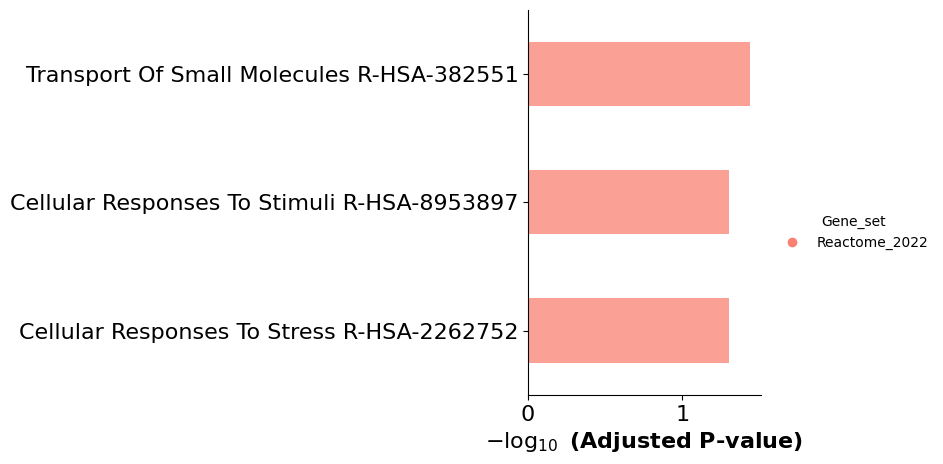

In [35]:
ax = barplot(
    enr.results,
    column="Adjusted P-value",
    group='Gene_set',      # group bars by library (multi-library comparison)
    size=5,
    top_term=5,
    figsize=(3, 5),
    color={'Reactome_2022': 'salmon'},
)
plt.savefig('./figures/fig3d_enrichrpiece.pdf',bbox_inches='tight')

### Claude glow-up

In [40]:
"""
Figure 3, Panel D -- classifier feature importance (signed Gini importance
per gene) as a horizontal bar chart, with a Reactome enrichment result
(via gseapy) shown as an inset in the chart's own whitespace.

Original figure-generating code (two separate primitives, per your
message):

    # FeatureImportance_RNA_signed2.pdf
    fig, ax = plt.subplots(figsize=(13,10))
    sns.barplot(CFsmall,x='Gene',y='Importance')
    plt.xticks(rotation=90)
    plt.title('Fibroblasts, young vs old controls, key genes in AdaBoost models')

    # fig3d_enrichrpiece.pdf (gseapy)
    ax = barplot(
        enr.results,
        column="Adjusted P-value",
        group='Gene_set',
        size=5,
        top_term=5,
        figsize=(3, 5),
        color={'Reactome_2022': 'salmon'},
    )

Same two inputs (CFsmall's Gene/Importance columns, and gseapy's
enr.results), same data -- this rewrite changes how they're drawn and
combines them into one panel matching the published Fig3d.pdf crop:

  1. ROTATED 90 DEGREES, per your explicit request: genes now run down the
     Y-AXIS (row order preserved exactly from CFsmall -- the first row in
     your dataframe lands at the TOP of the chart, same left-to-right
     order the original vertical version used, just transposed) and
     Signed Gini importance runs along the X-axis, with the value axis
     moved to the TOP of the panel (`ax.xaxis.tick_top()` +
     `set_label_position('top')`) -- this is how it's laid out in the
     published Fig3d.pdf crop, and it keeps the axis readable at the top
     of a panel that's otherwise dominated by a long gene list running
     down the page.

  2. HOUSE GRADIENT instead of matplotlib/seaborn's default categorical
     cycle: the original renders each contiguous block of ~5-6 bars in a
     different color (salmon/orange/olive/green/teal/blue/purple/pink --
     visible in FeatureImportance_RNA_signed2.pdf) -- your one-line code
     doesn't show a `palette=`/`hue=` argument, so CFsmall most likely
     carries its own per-gene grouping column (a community/cluster id?)
     that the paraphrased snippet omitted. Rather than guess at that
     column's name, `plot_feature_importance_horizontal()` takes an
     optional `color_col`: pass it and each unique value gets its own
     color from `style.gene_importance_gradient()` (new in paper_style.py
     -- a smooth ramp built from the house ACCENTS, so this many-colored
     panel still reads as part of the same coordinated palette as every
     other panel, rather than a literal default rainbow). If you don't
     have/want a real grouping column, it falls back to coloring
     positional blocks of `n_color_blocks` bars each (default 9,
     approximating the original's visual block count) so the panel still
     looks intentional without one. TELL ME the real column name if
     CFsmall has one and I'll wire it in directly.

  3. HOUSE REFERENCE LINE + light gridlines: a real `ax.axvline(0, ...)`
     in REFERENCE_LINE_COLOR marks the positive/negative importance
     boundary (the original just relied on bars visually starting at 0),
     and restrained vertical gridlines (present in the published Fig3d.pdf
     crop but not in the original bare seaborn render) help a reader trace
     a specific bar's length across 51 rows.

  4. ENRICHR INSET: `plot_enrichr_inset()` draws the gseapy Reactome result
     as a small inset via `ax.inset_axes(...)`, positioned in the chart's
     own whitespace (its `inset_bbox` argument is axes-fraction
     [x0, y0, width, height] on the MAIN chart -- I don't have your real
     Importance values, so this is a starting guess at the lower-left
     quadrant where the original's small-magnitude bars leave the most
     room; nudge `inset_bbox` once you see it against real data). Colored
     GOLD (not the original's salmon-adjacent "TERRACOTTA", which Panel E
     already uses elsewhere in THIS figure -- the house rule is to avoid a
     color clash within one figure, and Panel D/E are both in Figure 3).
     Dropped the redundant "Gene_set: Reactome_2022" legend swatch (there's
     only ever one Gene_set value here) in favor of a small title reading
     "Reactome_2022 enrichment" -- more legible at inset scale.

Usage:

    import paper_style as style
    from fig3_panelD_feature_importance import plot_panel_d

    style.apply()
    fig, ax, axins = plot_panel_d(
        CFsmall, enr.results, panel_label="d",
        color_col=None,  # or the real per-gene grouping column, if any
    )
    fig.savefig("Figure3_PanelD_feature_importance.pdf", bbox_inches="tight")

See _preview_panelD.py for the synthetic-data smoke test (not for
publication).
"""

from __future__ import annotations

import textwrap

import numpy as np
import matplotlib.pyplot as plt

import paper_style as style


def plot_feature_importance_horizontal(
    df,
    gene_col="Gene",
    importance_col="Importance",
    color_col=None,
    n_color_blocks=9,
    ax=None,
    figsize=(6.6, 11.5),
    bar_height=0.72,
    title="Fibroblasts, young vs old controls, key genes in AdaBoost models",
    x_label="Signed Gini importance",
    y_label="Gene",
    gene_label_fontsize=6.5,
    panel_label=None,
):
    """Horizontal (rotated 90 degrees) version of the signed Gini
    importance bar chart. Row order is preserved exactly from `df` --
    first row plots at the top. Returns (fig, ax).

    color_col: optional column name in `df` giving each gene's real
    grouping/cluster; if omitted, bars are colored in positional blocks of
    `n_color_blocks` genes each along `style.gene_importance_gradient()`.
    """
    if ax is None:
        fig, ax = plt.subplots(figsize=figsize)
    else:
        fig = ax.figure

    genes = df[gene_col].tolist()
    values = df[importance_col].to_numpy(dtype=float)
    n = len(genes)
    y = np.arange(n)

    if color_col is not None and color_col in df.columns:
        groups = df[color_col].tolist()
        uniques = list(dict.fromkeys(groups))  # first-appearance order
        gradient = style.gene_importance_gradient(len(uniques))
        color_of = dict(zip(uniques, gradient))
        bar_colors = [color_of[g] for g in groups]
    else:
        gradient = style.gene_importance_gradient(n_color_blocks)
        bar_colors = [gradient[min(i * n_color_blocks // max(n, 1), n_color_blocks - 1)]
                      for i in range(n)]

    ax.barh(
        y, values, height=bar_height, color=bar_colors,
        edgecolor=[style.darken(c, 0.25) for c in bar_colors], linewidth=0.4,
        zorder=3,
    )

    ax.axvline(0, color=style.REFERENCE_LINE_COLOR, linestyle="-", linewidth=0.9, zorder=2)
    ax.xaxis.grid(True, color="#e6e6e6", linewidth=0.8, zorder=0)
    ax.set_axisbelow(True)

    # A little breathing room so the longest bar isn't flush with the panel
    # edge (and so its value tick doesn't get clipped by bbox_inches='tight').
    v_min, v_max = float(values.min()), float(values.max())
    pad = 0.08 * (v_max - v_min if v_max > v_min else abs(v_max) or 1.0)
    ax.set_xlim(v_min - pad, v_max + pad)

    ax.set_yticks(y)
    ax.set_yticklabels(genes, fontsize=gene_label_fontsize)
    ax.invert_yaxis()  # first row of df at the TOP
    ax.set_ylim(n - 0.5, -0.5)

    # Value axis on TOP, matching the published Fig3d.pdf crop.
    ax.xaxis.tick_top()
    ax.xaxis.set_label_position("top")
    ax.set_xlabel(x_label)
    ax.set_ylabel(y_label)

    ax.spines["bottom"].set_visible(False)
    ax.spines["right"].set_visible(False)
    ax.spines["top"].set_visible(True)
    ax.spines["left"].set_visible(True)
    ax.tick_params(axis="x", direction="out", top=True, bottom=False)
    ax.tick_params(axis="y", length=0)

    if title:
        ax.text(0.5, -0.015, title, transform=ax.transAxes, ha="center", va="top",
                fontsize=10)

    if panel_label:
        ax.text(-0.18, 1.015, panel_label, transform=ax.transAxes, fontsize=14,
                fontweight="bold", va="bottom", ha="left")

    return fig, ax


def plot_enrichr_inset(
    ax,
    enrich_df,
    term_col="Term",
    pvalue_col="Adjusted P-value",
    inset_bbox=(0.32, 0.03, 0.62, 0.20),
    color=None,
    top_term=3,
    title="Reactome_2022 enrichment",
    term_fontsize=5.8,
    term_wrap=30,
):
    """Draw a gseapy-style Reactome enrichment barplot (-log10 adjusted
    p-value per term) as an inset on `ax` (the main feature-importance
    axes), in `ax`'s own whitespace. `inset_bbox` is
    [x0, y0, width, height] in AXES-FRACTION coordinates of `ax` -- adjust
    once you see this against real Importance values, since the right
    amount of whitespace depends on where the real small-magnitude bars
    fall. `inset_bbox`'s default x0 (0.32) is deliberately well clear of 0
    -- an inset placed right against the parent axes' left edge puts its
    own y-tick labels in the same display region as the main gene-name
    column (they overflow to the left of the inset's own spine), which
    reads as one garbled mess of text; term labels are also wrapped
    in-place (`term_wrap` chars/line) rather than left as one long
    unwrapped line, for the same reason -- both fixed after the first
    synthetic-data preview showed the collision. Returns the inset Axes.
    """
    color = color or style.GOLD

    plot_df = enrich_df.head(top_term).iloc[::-1]  # smallest p at top like gseapy
    terms = plot_df[term_col].tolist()
    wrapped_terms = ["\n".join(textwrap.wrap(t, term_wrap)) for t in terms]
    neglog_p = -np.log10(plot_df[pvalue_col].to_numpy(dtype=float))

    axins = ax.inset_axes(inset_bbox)
    # Opaque white backing so the inset -- including its own tick labels --
    # stays legible over whatever main-chart bars happen to sit behind it.
    axins.patch.set_facecolor("white")
    axins.patch.set_alpha(0.96)

    y = np.arange(len(terms))
    axins.barh(y, neglog_p, height=0.55, color=color,
               edgecolor=style.darken(color, 0.25), linewidth=0.4, zorder=3)
    axins.set_yticks(y)
    axins.set_yticklabels(wrapped_terms, fontsize=term_fontsize, linespacing=0.92)
    axins.set_xlabel(r"$-\log_{10}$ (Adjusted P-value)", fontsize=6.5)
    axins.set_title(title, fontsize=6.5, fontweight="bold", pad=3)
    axins.tick_params(axis="x", labelsize=5.5, length=2)
    axins.tick_params(axis="y", length=0)
    axins.margins(x=0.12)
    style.despine_clean(axins)

    return axins


def plot_panel_d(
    df,
    enrich_df,
    gene_col="Gene",
    importance_col="Importance",
    color_col=None,
    n_color_blocks=9,
    term_col="Term",
    pvalue_col="Adjusted P-value",
    inset_bbox=(0.32, 0.03, 0.62, 0.20),
    inset_color=None,
    figsize=(6.6, 11.5),
    panel_label=None,
):
    """Full Panel D: rotated feature-importance bar chart plus the
    Reactome enrichment inset. Returns (fig, ax, axins)."""
    fig, ax = plot_feature_importance_horizontal(
        df, gene_col=gene_col, importance_col=importance_col,
        color_col=color_col, n_color_blocks=n_color_blocks,
        figsize=figsize, panel_label=panel_label,
    )
    axins = plot_enrichr_inset(
        ax, enrich_df, term_col=term_col, pvalue_col=pvalue_col,
        inset_bbox=inset_bbox, color=inset_color,
    )
    fig.tight_layout()
    return fig, ax, axins


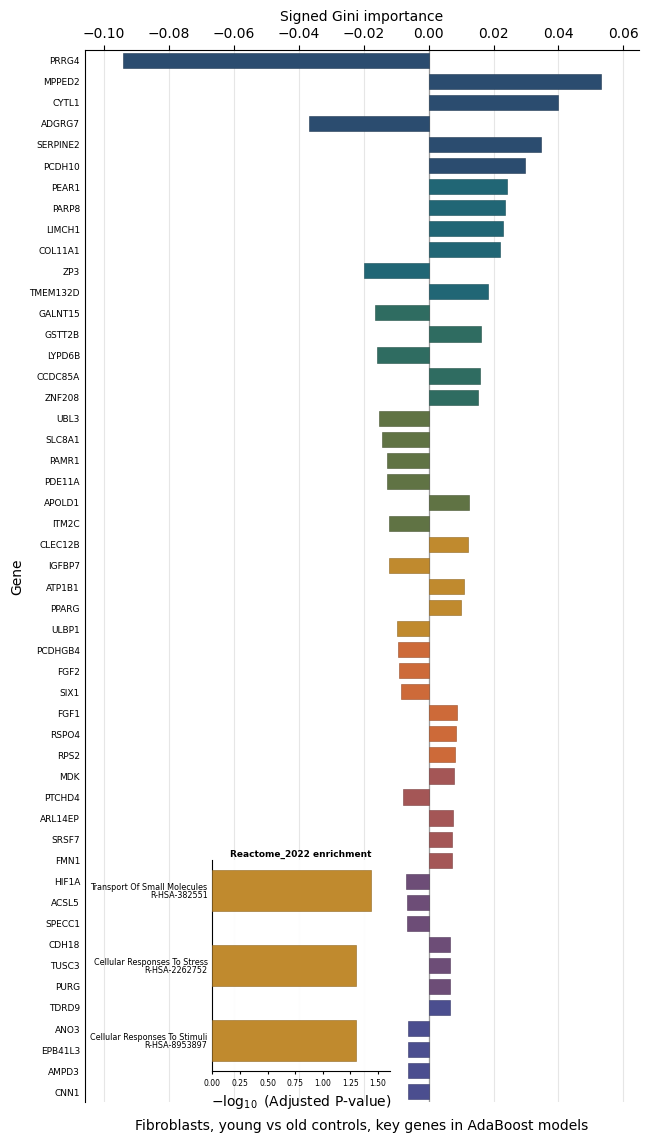

In [41]:
plot_panel_d(
    ClassFeatures.iloc[:50,:],
    enr.results,
    gene_col="Gene",
    importance_col="SignedImportance",
    color_col=None,
    n_color_blocks=9,
    term_col="Term",
    pvalue_col="Adjusted P-value",
    inset_bbox=(0.23, 0.03, 0.32, 0.20),
    inset_color=None,
    figsize=(6.6, 11.5),
    panel_label=None,
)
plt.savefig('./newfigures/FeatureImportance_RNA_signed.pdf',bbox_inches='tight')

## Panel E

In [326]:
sumdf=DataDict['Figure3']['RankScores_and_Other_Gene_Info']
sumdf.head()

,Gene,RNAYS,RNA_AbFrac,YouthScore_Hybrid,MasterScore,MeanMito%,StdMito%,MeanRibo%,StdRibo%,MeanMalat%,...,NumNeither,OddsRatio,pvals,scRNA_cellcount,Master Score tritile,TF/surface marker/secreted factor,Reactome: Cellular responses to stimuli,Reactome: Intracellular core functions,Reactome: Immune system,CellCountCP
0,ANXA2,0.236025,0.069364,0.180877,-0.021485,1.625959,0.573768,0.944102,0.313470,2.361226,...,3816.0,1.645974,1.131976e-07,519.0,control,Secreted Factor,0.0,0.0,0.0,1665.0
1,OLD,0.247183,0.067234,0.145214,NaN,1.246700,0.438352,1.075207,0.388175,2.029116,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,139533.0
2,YOUNG,0.767124,0.071813,0.885398,NaN,1.318644,0.543593,1.146731,0.407127,2.057075,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,41162.0
3,TP53,0.336058,0.084910,0.181916,0.000367,1.583803,0.672274,1.184535,0.390952,1.508459,...,2010.0,0.819962,7.438840e-01,2273.0,control,Transcription Factor,0.0,0.0,0.0,3791.0
4,MRPS2,0.204873,0.059401,0.089199,0.239430,1.072958,0.924759,1.112192,0.428831,1.800366,...,1641.0,0.791076,9.970685e-01,2138.0,negative,NaN,0.0,1.0,0.0,1883.0


In [327]:
sumdf2=sumdf[(~sumdf.MasterScore.isna())&(~sumdf.RNAYS.isna())]

In [328]:
print(stats.pearsonr(sumdf2.MasterScore,sumdf2.RNAYS))
print(stats.pearsonr(sumdf2[sumdf2.pvals<0.05].MasterScore,sumdf2[sumdf2.pvals<0.05].RNAYS))

PearsonRResult(statistic=-0.06315086120720609, pvalue=0.31323505020634446)
PearsonRResult(statistic=-0.2893943934591354, pvalue=0.13525700930568846)


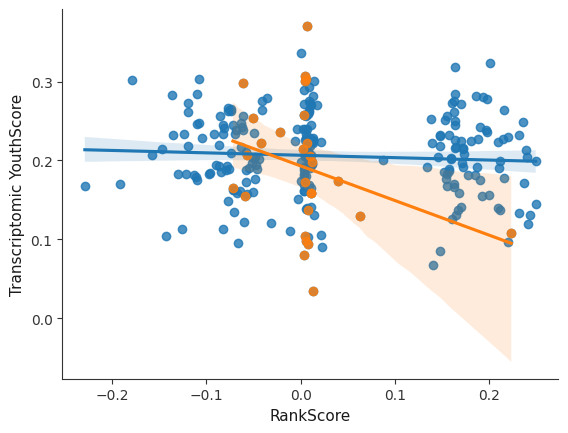

In [395]:
sns.regplot(data=sumdf2,x='MasterScore',y='RNAYS')
sns.regplot(data=sumdf2[sumdf2.pvals<0.05],x='MasterScore',y='RNAYS')

plt.ylabel('Transcriptomic YouthScore')
plt.xlabel('RankScore')


plt.savefig('./figures/regplot.pdf')

### Claude glow-up

In [329]:
"""
Figure 3, Panel E -- RankScore vs. Transcriptomic YouthScore, for the
entire library and for the subset of genes with a significant Fisher Exact
subnetwork-precision result (pFisher < 0.05).

Original figure-generating code:

    sns.regplot(data=sumdf2, x='MasterScore', y='RNAYS')
    sns.regplot(data=sumdf2[sumdf2.pvals<0.05], x='MasterScore', y='RNAYS')
    plt.ylabel('Transcriptomic YouthScore')
    plt.xlabel('RankScore')

Same two regressions, same underlying seaborn regplot machinery (so the
line, its 95%% CI band, and the fit itself are unchanged) -- this rewrite
only restyles what was left at seaborn's defaults and adds what the
published Fig3d.pdf crop already carries but the code didn't:

  1. HOUSE COLORS, not the default matplotlib blue/orange: "Entire
     dataset" -> SLATE (this panel's population is every library gene's
     raw observation, the same semantic role SLATE plays everywhere else
     in the figure set) and the "pFisher < 0.05" subset -> TERRACOTTA, the
     closest house accent to the original's tab:orange (same
     closest-hue-match approach used for Fig2 F's ink_blue/terracotta
     swap). Terracotta already means something else in Fig2 F ("viral DE
     profile removed"), but that's a different figure a reader isn't
     flipping between side-by-side, and every other accent color in this
     project is already reused across figures for different meanings
     (ink_blue alone means four different things across Fig1 A / Fig2 E /
     Fig2 F / Fig3 C) -- the house "don't reuse a color" caution is about
     two panels of the SAME figure, not the whole paper.

  2. REDUNDANT ENCODING (reusing the Fig2 E/F two-condition convention,
     workflow #4 in the house-style notes): marker shape and line style
     both also carry the entire/subset distinction (circle+solid for
     "Entire dataset", diamond+dashed for the significant subset), not
     just color -- consistent with how every other two-condition panel in
     this project already reads.

  3. ON-PLOT PEARSON STATS for BOTH regressions (via `scipy.stats.pearsonr`
     + `style.fmt_pearson()`, exactly the convention introduced on Panel C
     -- bold rho, italic p, translucent white backing box), which the
     original code never computed or displayed at all despite the
     published Fig3d.pdf crop showing them. Uses Panel C's v2 fix too:
     FIXED axes-fraction stacked positions rather than anchoring to either
     line's data value, so the two labels can't collide.

  4. A REBUILT LEGEND ("Entire dataset" / a mathtext "$p_{Fisher}$ < 0.05"
     matching the italic-p house convention) -- the original had none;
     seaborn's auto-legend from two unlabeled regplot calls wouldn't have
     produced one either.

Usage:

    import paper_style as style
    from fig3_panelE_rankscore_youthscore import plot_rankscore_youthscore

    style.apply()
    fig, ax = plot_rankscore_youthscore(sumdf2, panel_label="e")
    fig.savefig("Figure3_PanelE_rankscore_youthscore.pdf", bbox_inches="tight")

See _preview_rankscore_youthscore.py for the synthetic-data smoke test
(not for publication).
"""

from __future__ import annotations

import matplotlib.pyplot as plt
from matplotlib.lines import Line2D
import seaborn as sns
from scipy import stats

import paper_style as style

ENTIRE_COLOR = style.SLATE
SUBSET_COLOR = style.TERRACOTTA


def plot_rankscore_youthscore(
    df,
    x_col="MasterScore",
    y_col="RNAYS",
    sig_col="pvals",
    sig_threshold=0.05,
    x_label="RankScore",
    y_label="Transcriptomic YouthScore",
    entire_color=ENTIRE_COLOR,
    subset_color=SUBSET_COLOR,
    entire_marker="o",
    subset_marker="D",
    entire_label="Entire dataset",
    subset_label=r"$p_{Fisher}$ < 0.05",
    point_size=42,
    ax=None,
    figsize=(6.6, 5.6),
    annotate_fontsize=13,
    annotate_x_frac=0.96,
    entire_annotate_y_frac=0.97,
    subset_annotate_y_frac=0.20,
    panel_label=None,
):
    """Recreate the RankScore-vs-YouthScore regression panel with house
    styling: house colors + redundant marker/linestyle encoding for the
    two gene sets, on-plot Pearson stats per regression, and a real
    legend. Returns (fig, ax).

    `df` is the full library (`sumdf2` in the original); the significant
    subset is derived here via `df[sig_col] < sig_threshold`, same as the
    original's inline `sumdf2[sumdf2.pvals<0.05]`.
    """
    if ax is None:
        fig, ax = plt.subplots(figsize=figsize)
    else:
        fig = ax.figure

    subset = df[df[sig_col] < sig_threshold]

    rho_entire, p_entire = stats.pearsonr(df[x_col], df[y_col])
    rho_subset, p_subset = stats.pearsonr(subset[x_col], subset[y_col])

    # Entire dataset: solid line, circle markers, SLATE.
    sns.regplot(
        data=df, x=x_col, y=y_col, ax=ax, color=entire_color, marker=entire_marker,
        scatter_kws=dict(s=point_size, alpha=0.75, zorder=3,
                          edgecolor=style.darken(entire_color, 0.25), linewidths=0.4),
        line_kws=dict(linestyle="-", linewidth=1.8, zorder=4),
        truncate=True,
    )
    # Significant subset: dashed line, diamond markers, TERRACOTTA -- drawn
    # second/on top since it's the smaller, headline-relevant group.
    sns.regplot(
        data=subset, x=x_col, y=y_col, ax=ax, color=subset_color, marker=subset_marker,
        scatter_kws=dict(s=point_size * 1.15, alpha=0.9, zorder=5,
                          edgecolor=style.darken(subset_color, 0.25), linewidths=0.5),
        line_kws=dict(linestyle=(0, (4, 2)), linewidth=1.8, zorder=6),
        truncate=True,
    )

    # Stats annotations: fixed axes-fraction positions (Panel C v2
    # convention) so they can never collide with each other or with either
    # line, plus a translucent backing box for legibility over the points.
    label_bbox = dict(boxstyle="round,pad=0.28", facecolor="white",
                       edgecolor="none", alpha=0.82)
    ax.text(annotate_x_frac, entire_annotate_y_frac, style.fmt_pearson(rho_entire, p_entire),
            transform=ax.transAxes, color=entire_color, ha="right", va="top",
            fontsize=annotate_fontsize, zorder=7, bbox=label_bbox)
    ax.text(annotate_x_frac, subset_annotate_y_frac, style.fmt_pearson(rho_subset, p_subset),
            transform=ax.transAxes, color=subset_color, ha="right", va="top",
            fontsize=annotate_fontsize, zorder=7, bbox=label_bbox)

    ax.set_xlabel(x_label)
    ax.set_ylabel(y_label)
    style.despine_clean(ax)

    handles = [
        Line2D([0], [0], marker=entire_marker, linestyle="-", color=entire_color,
               markerfacecolor=entire_color, markeredgecolor=style.darken(entire_color, 0.25),
               markersize=7, label=entire_label),
        Line2D([0], [0], marker=subset_marker, linestyle=(0, (4, 2)), color=subset_color,
               markerfacecolor=subset_color, markeredgecolor=style.darken(subset_color, 0.25),
               markersize=7, label=subset_label),
    ]
    ax.legend(handles=handles, loc="lower left", frameon=True, framealpha=0.9,
              edgecolor="#cccccc", fontsize=10, handletextpad=0.6, borderpad=0.6)

    if panel_label:
        ax.text(-0.15, 1.03, panel_label, transform=ax.transAxes, fontsize=14,
                fontweight="bold", va="bottom", ha="left")

    fig.tight_layout()
    return fig, ax


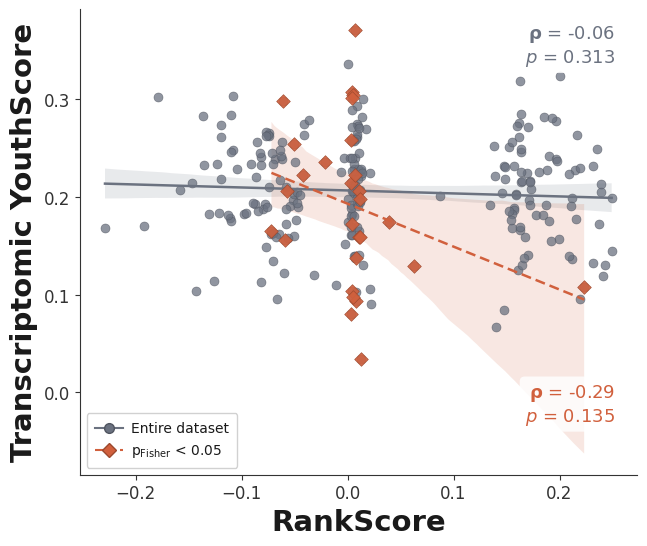

In [330]:
plot_rankscore_youthscore(
    sumdf2,
    x_col="MasterScore",
    y_col="RNAYS",
    sig_col="pvals",
    sig_threshold=0.05,
    x_label="RankScore",
    y_label="Transcriptomic YouthScore",
    entire_color=ENTIRE_COLOR,
    subset_color=SUBSET_COLOR,
    entire_marker="o",
    subset_marker="D",
    entire_label="Entire dataset",
    subset_label=r"$p_{Fisher}$ < 0.05",
    point_size=42,
    ax=None,
    figsize=(6.6, 5.6),
    annotate_fontsize=13,
    annotate_x_frac=0.96,
    entire_annotate_y_frac=0.97,
    subset_annotate_y_frac=0.20,
    panel_label=None,
)
plt.savefig('./newfigures/regplot.pdf',bbox_inches='tight')

## Panel F

In [45]:
sumdf=DataDict['Figure3']['RankScores_and_Other_Gene_Info']
sumdf.head()

,Gene,RNAYS,RNA_AbFrac,YouthScore_Hybrid,MasterScore,MeanMito%,StdMito%,MeanRibo%,StdRibo%,MeanMalat%,...,NumNeither,OddsRatio,pvals,scRNA_cellcount,Master Score tritile,TF/surface marker/secreted factor,Reactome: Cellular responses to stimuli,Reactome: Intracellular core functions,Reactome: Immune system,CellCountCP
0,ANXA2,0.236025,0.069364,0.180877,-0.021485,1.625959,0.573768,0.944102,0.313470,2.361226,...,3816.0,1.645974,1.131976e-07,519.0,control,Secreted Factor,0.0,0.0,0.0,1665.0
1,OLD,0.247183,0.067234,0.145214,NaN,1.246700,0.438352,1.075207,0.388175,2.029116,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,139533.0
2,YOUNG,0.767124,0.071813,0.885398,NaN,1.318644,0.543593,1.146731,0.407127,2.057075,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,41162.0
3,TP53,0.336058,0.084910,0.181916,0.000367,1.583803,0.672274,1.184535,0.390952,1.508459,...,2010.0,0.819962,7.438840e-01,2273.0,control,Transcription Factor,0.0,0.0,0.0,3791.0
4,MRPS2,0.204873,0.059401,0.089199,0.239430,1.072958,0.924759,1.112192,0.428831,1.800366,...,1641.0,0.791076,9.970685e-01,2138.0,negative,NaN,0.0,1.0,0.0,1883.0


In [46]:
def RNA_RejuvFracBootstrap(df,qle):
    # This calculates the "rejuvenative fraction" = the fraction of EXAMINED genes with transcriptomic YouthScores greater than old.
    # This will be examined for different subsets of the data. 
    df2=df[~df.MasterScore.isna()]; columns=df2.columns; n=len(df2) 
    bs=pd.DataFrame(df2.values[np.random.randint(n, size=n)], columns=columns) # Bootstrap 
    low=np.quantile(bs.MasterScore,qle)
    subdf=bs[bs.MasterScore>=low]
    return len(subdf[subdf.RNAYS>df[df.Gene=='OLD'].RNAYS.values[0]])/len(subdf)
    

In [47]:
%%time

#Now, sweep over a grid of RankScore inclusions, and bootstrap for many trials:

QuantileBox=[0.05,0.1,0.15,0.2,0.25,0.3,0.35,0.4,0.45,0.5,0.55,0.6,0.65,0.7,0.75,0.8,0.85,0.9,0.95]
ResultBox=[]
for qle in QuantileBox:
    bootstrapbox=[]
    for trial in range(1000):
        bootstrapbox.append(RNA_RejuvFracBootstrap(sumdf,qle))
    ResultBox.append(bootstrapbox)

CPU times: user 41.9 s, sys: 12.3 ms, total: 41.9 s
Wall time: 41.9 s


In [48]:
MeanBox=[np.mean(i) for i in ResultBox]
StdBox=[np.std(i) for i in ResultBox]

Note that RESULTS MAY DIFFER (slightly -- probably inscrutably, given the number of bootstraps) because we do not pin down the RNG seed

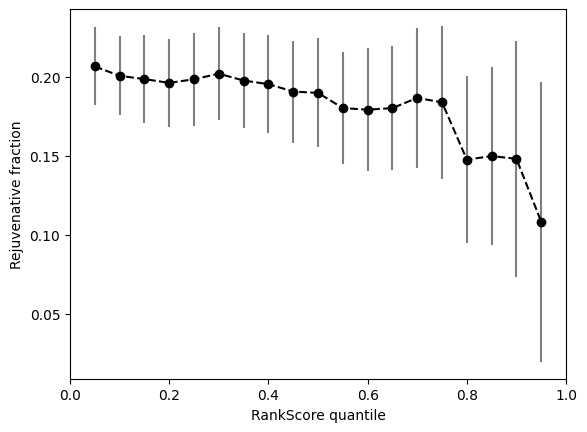

In [49]:
plt.errorbar(QuantileBox,MeanBox,StdBox,fmt='o',color='k',ecolor='tab:gray',linestyle='--')
plt.xlim([0,1])
plt.xlabel('RankScore quantile')
plt.ylabel('Rejuvenative fraction')

plt.savefig('./figures/RejuvenativeFractions_scRNA.pdf')

### Claude glow-up

In [334]:
"""
Figure 3, Panel F -- rejuvenative fraction vs. RankScore quantile, redesigned
around the fact that each of the 19 x-positions IS a full bootstrapped
distribution (1000 numbers), not just a mean and a standard deviation.

Original figure-generating code:

    QuantileBox=[0.05,0.1,0.15,0.2,0.25,0.3,0.35,0.4,0.45,0.5,0.55,0.6,0.65,
                 0.7,0.75,0.8,0.85,0.9,0.95]
    MeanBox=[np.mean(i) for i in ResultBox]
    StdBox=[np.std(i) for i in ResultBox]
    plt.errorbar(QuantileBox,MeanBox,StdBox,fmt='o',color='k',ecolor='tab:gray',
                 linestyle='--')
    plt.xlim([0,1])
    plt.xlabel('RankScore quantile')
    plt.ylabel('Rejuvenative fraction')

Same underlying data (`ResultBox`, a list of 19 arrays -- the full
bootstrapped distribution behind each quantile bin), and the same headline
trend (a flat-ish plateau around ~0.20 that breaks downward in the top
quantiles) -- but per your explicit note that the point+whisker version
"is much too plain" and should "leverage the fact that each of the 19
points ... is a 1000-number distribution," this is a full redesign rather
than a restyle:

  1. EACH X-POSITION IS NOW A VIOLIN, not a mean dot + a symmetric std bar.
     `ax.violinplot()` draws the actual kernel-density SHAPE of each
     bootstrap distribution (skew, bimodality, tail weight -- anything a
     mean+std pair throws away is visible here), restyled to house spec:
     flat house TEAL fill (not matplotlib's default purple/blue violin
     colors), no default black min/max whisker spike through the middle
     (`showextrema=False` -- replaced by the quartile/percentile overlay in
     #2, which is more informative and less visually busy than the
     built-in one anyway).

  2. QUARTILE + 5TH/95TH PERCENTILE OVERLAY drawn BY HAND directly from each
     bootstrap array (`np.percentile`, not `np.std`) inside each violin: a
     thick short IQR bar (Q1-Q3), a median dot, and a thin 5th-95th whisker
     -- i.e. this keeps every honest summary statistic the original
     errorbar-style plot showed (in fact adds the median, which the
     original never computed -- it only ever plotted the MEAN), while the
     violin body around it shows the shape those numbers were summarizing.
     Using real percentiles rather than mean +/- std also means a skewed
     bootstrap distribution (very plausible for a bounded fraction sitting
     near a floor/ceiling) is represented honestly instead of implying a
     symmetric spread it may not have.

  3. MEDIAN TREND LINE connects the 19 medians (solid, darkened TEAL) --
     carries forward the one thing the original's dashed connecting line
     was for (showing the trend across quantiles) without implying, the
     way a single dot does, that each quantile bin reduces to one number.

  4. HOUSE COLOR: TEAL -- the one house accent not yet used anywhere else
     in Figure 3 (B/C = slate+black/ink_blue, D = the full gradient+gold,
     E = slate+terracotta), so Panel F reads as its own distinct series
     while still drawing from the same six-color house set.

This is ONE proposed redesign (a "violin + quartile overlay" hybrid,
sometimes called a raincloud plot without the raw-point cloud, dropped here
since 1000 points x 19 bins would be too dense to read as individual dots
even at low alpha) -- if you'd rather see a ridgeline/joyplot instead (each
distribution as a horizontal density curve, offset vertically), or the raw
per-quantile histograms as small multiples, say so and I'll build that
version instead.

Usage:

    import paper_style as style
    from fig3_panelF_rejuvenative_fractions import plot_rejuvenative_fractions

    style.apply()
    fig, ax = plot_rejuvenative_fractions(ResultBox, panel_label="f")
    fig.savefig("Figure3_PanelF_rejuvenative_fractions.pdf", bbox_inches="tight")

See _preview_panelF.py for the synthetic-data smoke test (not for
publication).
"""

from __future__ import annotations

import numpy as np
import matplotlib.pyplot as plt

import paper_style as style

QUANTILE_BOX = [0.05, 0.1, 0.15, 0.2, 0.25, 0.3, 0.35, 0.4, 0.45, 0.5, 0.55,
                 0.6, 0.65, 0.7, 0.75, 0.8, 0.85, 0.9, 0.95]

VIOLIN_COLOR = style.TEAL


def plot_rejuvenative_fractions(
    result_box,
    quantile_box=None,
    ax=None,
    figsize=(7.2, 5.4),
    violin_color=VIOLIN_COLOR,
    violin_width=0.035,
    violin_alpha=0.55,
    iqr_linewidth=3.2,
    whisker_linewidth=1.0,
    median_markersize=5.5,
    x_label="RankScore quantile",
    y_label="Rejuvenative fraction",
    panel_label=None,
):
    """Redesigned Panel F: one violin per RankScore-quantile bin (kernel
    density of that bin's full bootstrapped distribution), with a hand-drawn
    median/IQR/5th-95th-percentile overlay and a connecting median trend
    line. Returns (fig, ax).

    `result_box` is `ResultBox` from the original code: a sequence of 19
    arrays/lists, each the full bootstrapped-fraction distribution for one
    quantile bin (matched positionally to `quantile_box`, default
    `QUANTILE_BOX` == the original `QuantileBox`).
    """
    if ax is None:
        fig, ax = plt.subplots(figsize=figsize)
    else:
        fig = ax.figure

    if quantile_box is None:
        quantile_box = QUANTILE_BOX

    distributions = [np.asarray(d, dtype=float) for d in result_box]
    x = np.asarray(quantile_box, dtype=float)

    edge_color = style.darken(violin_color, 0.35)
    stat_color = style.darken(violin_color, 0.55)

    parts = ax.violinplot(
        distributions, positions=x, widths=violin_width,
        showmeans=False, showmedians=False, showextrema=False,
    )
    for body in parts["bodies"]:
        body.set_facecolor(violin_color)
        body.set_edgecolor(edge_color)
        body.set_alpha(violin_alpha)
        body.set_linewidth(0.6)
        body.set_zorder(3)

    medians = np.array([np.median(d) for d in distributions])
    q1 = np.array([np.percentile(d, 25) for d in distributions])
    q3 = np.array([np.percentile(d, 75) for d in distributions])
    p05 = np.array([np.percentile(d, 5) for d in distributions])
    p95 = np.array([np.percentile(d, 95) for d in distributions])

    # Thin 5th-95th whisker, then a thick short IQR bar, then the median dot
    # -- drawn in that back-to-front order so the eye reads it as one
    # increasingly-precise summary rather than three competing marks.
    ax.vlines(x, p05, p95, color=stat_color, linewidth=whisker_linewidth,
               zorder=4, alpha=0.8)
    ax.vlines(x, q1, q3, color=stat_color, linewidth=iqr_linewidth,
               zorder=5, capstyle="round")
    # Median trend line first (so the dots sit on top of it), then the dots.
    ax.plot(x, medians, color=stat_color, linewidth=1.4, zorder=6, alpha=0.9)
    ax.plot(x, medians, "o", color="white", markeredgecolor=stat_color,
            markeredgewidth=1.3, markersize=median_markersize, zorder=7)

    ax.set_xlim(0, 1)
    ax.set_xlabel(x_label)
    ax.set_ylabel(y_label)
    style.despine_clean(ax)

    if panel_label:
        ax.text(-0.14, 1.03, panel_label, transform=ax.transAxes, fontsize=14,
                fontweight="bold", va="bottom", ha="left")

    fig.tight_layout()
    return fig, ax


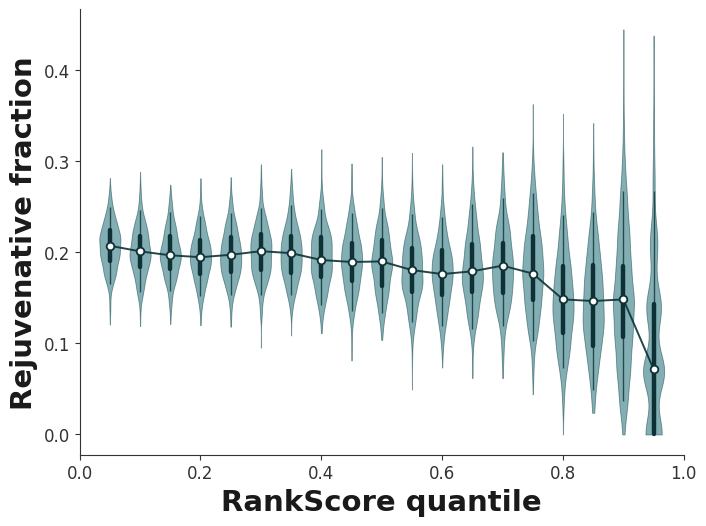

In [335]:
plot_rejuvenative_fractions(
    ResultBox,
    quantile_box=None,
    ax=None,
    figsize=(7.2, 5.4),
    violin_color=VIOLIN_COLOR,
    violin_width=0.035,
    violin_alpha=0.55,
    iqr_linewidth=3.2,
    whisker_linewidth=1.0,
    median_markersize=5.5,
    x_label="RankScore quantile",
    y_label="Rejuvenative fraction",
    panel_label=None,
)
plt.savefig('./newfigures/RejuvenativeFractions_scRNA.pdf',bbox_inches='tight')

# Figure 4

Panel A was made in Inkscape, using one snapshot of a cell population from CellProfiler

## Panel B

In [336]:
DataDict['Figure4'].keys()

dict_keys(['RankScores_and_Other_Gene_Info', 'MorphologicalClassifierFeatures', 'RejuvenativeFraction'])

In [337]:
sumdf=DataDict['Figure4']['RankScores_and_Other_Gene_Info']

In [338]:
sumdf

,Gene,RNAYS,RNA_AbFrac,YouthScore_Hybrid,MasterScore,MeanMito%,StdMito%,MeanRibo%,StdRibo%,MeanMalat%,...,NumNeither,OddsRatio,pvals,scRNA_cellcount,Master Score tritile,TF/surface marker/secreted factor,Reactome: Cellular responses to stimuli,Reactome: Intracellular core functions,Reactome: Immune system,CellCountCP
0,ANXA2,0.236025,0.069364,0.180877,-0.021485,1.625959,0.573768,0.944102,0.313470,2.361226,...,3816.0,1.645974,1.131976e-07,519.0,control,Secreted Factor,0.0,0.0,0.0,1665.0
1,OLD,0.247183,0.067234,0.145214,NaN,1.246700,0.438352,1.075207,0.388175,2.029116,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,139533.0
2,YOUNG,0.767124,0.071813,0.885398,NaN,1.318644,0.543593,1.146731,0.407127,2.057075,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,41162.0
3,TP53,0.336058,0.084910,0.181916,0.000367,1.583803,0.672274,1.184535,0.390952,1.508459,...,2010.0,0.819962,7.438840e-01,2273.0,control,Transcription Factor,0.0,0.0,0.0,3791.0
4,MRPS2,0.204873,0.059401,0.089199,0.239430,1.072958,0.924759,1.112192,0.428831,1.800366,...,1641.0,0.791076,9.970685e-01,2138.0,negative,NaN,0.0,1.0,0.0,1883.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
283,FADD,NaN,NaN,0.724654,0.010922,1.751171,0.477076,1.125105,0.260838,1.740500,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,886.0
284,SUPV3L1,NaN,NaN,NaN,NaN,1.011510,0.522532,1.074438,0.388780,2.049976,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
285,H3F3B,NaN,NaN,NaN,NaN,1.370906,NaN,2.183295,NaN,0.837776,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
286,RAB23,NaN,NaN,NaN,NaN,1.494714,0.499234,0.756750,0.109505,1.988666,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


The morphological YouthScore is called 'YouthScore_Hybrid' for internal historical reasons

In [342]:
cpdf=sumdf[~sumdf.YouthScore_Hybrid.isna()]
cpdf['Morphological YouthScore']=cpdf['YouthScore_Hybrid']

<ipython-input-342-b8a4978d2327>:2: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  cpdf['Morphological YouthScore']=cpdf['YouthScore_Hybrid']


In [340]:
cpdf

,Gene,RNAYS,RNA_AbFrac,YouthScore_Hybrid,MasterScore,MeanMito%,StdMito%,MeanRibo%,StdRibo%,MeanMalat%,...,NumNeither,OddsRatio,pvals,scRNA_cellcount,Master Score tritile,TF/surface marker/secreted factor,Reactome: Cellular responses to stimuli,Reactome: Intracellular core functions,Reactome: Immune system,CellCountCP
0,ANXA2,0.236025,0.069364,0.180877,-0.021485,1.625959,0.573768,0.944102,0.313470,2.361226,...,3816.0,1.645974,1.131976e-07,519.0,control,Secreted Factor,0.0,0.0,0.0,1665.0
1,OLD,0.247183,0.067234,0.145214,NaN,1.246700,0.438352,1.075207,0.388175,2.029116,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,139533.0
2,YOUNG,0.767124,0.071813,0.885398,NaN,1.318644,0.543593,1.146731,0.407127,2.057075,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,41162.0
3,TP53,0.336058,0.084910,0.181916,0.000367,1.583803,0.672274,1.184535,0.390952,1.508459,...,2010.0,0.819962,7.438840e-01,2273.0,control,Transcription Factor,0.0,0.0,0.0,3791.0
4,MRPS2,0.204873,0.059401,0.089199,0.239430,1.072958,0.924759,1.112192,0.428831,1.800366,...,1641.0,0.791076,9.970685e-01,2138.0,negative,NaN,0.0,1.0,0.0,1883.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
279,GABARAP,NaN,NaN,0.174009,-0.050420,1.337111,0.423654,1.231154,0.311402,2.185571,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,1387.0
280,USO1,NaN,NaN,0.175151,-0.053360,0.813182,NaN,1.209073,NaN,0.770383,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,4266.0
281,TEX261,NaN,NaN,0.182153,0.021787,1.410455,0.271346,1.366733,0.365635,1.731273,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,4181.0
282,EFTUD2,NaN,NaN,0.182200,0.174895,1.593962,0.502932,1.358338,0.463786,1.722697,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,4158.0


<ipython-input-325-b51514982483>:11: UserWarning: FixedFormatter should only be used together with FixedLocator
  ax.set_xticklabels(newlabels)


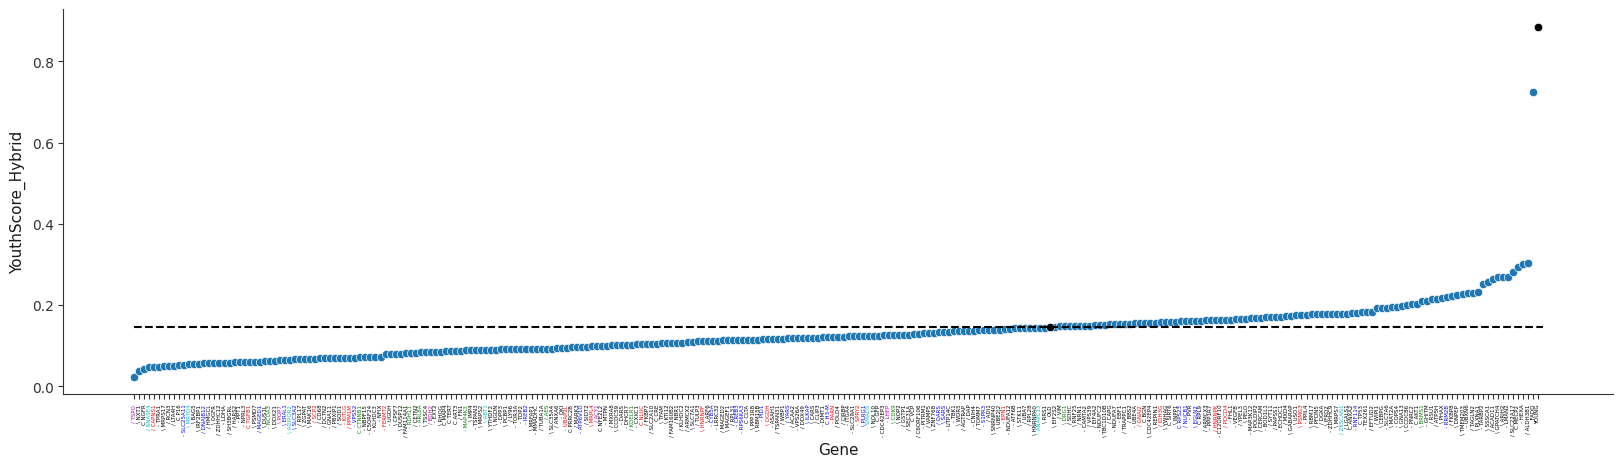

In [325]:
fig,ax=plt.subplots(figsize=(20,5))
sns.scatterplot(data=cpdf.sort_values('YouthScore_Hybrid'),x='Gene',y='YouthScore_Hybrid')
sns.scatterplot(data=cpdf[cpdf.Gene.isin(['OLD','YOUNG'])].sort_values('YouthScore_Hybrid'),x='Gene',y='YouthScore_Hybrid',color='k')

plt.xticks(rotation=90,fontsize=4);
plt.hlines(0.1452,0,280,linestyle='--',color='k')

labels = [item.get_text() for item in ax.get_xticklabels()]
newlabels= [liblabeldict['tritile'][i]+i for i in labels]

ax.set_xticklabels(newlabels)

for ticknum in range(len(cpdf.Gene)):
    ax.get_xticklabels()[ticknum].set_color(liblabeldict['color'][cpdf.Gene.values[ticknum]])
    
plt.savefig('./figures/CPYS.pdf')
plt.show()

### Claude glow-up

No need to reinvent the wheel here, this is Fig 3B with different data plugged in

In [341]:
"""
Figure 3, Panel B -- per-gene RNAYS "waterfall" (genes ranked by score,
symbol- and color-coded by two independent annotations), with the 'OLD'
and 'YOUNG' reference genes called out as distinguished points.

This panel is deliberately built as a close sibling of Fig2 Panel A's
MasterScore waterfall (fig2_panelA_masterscore.py) -- same `liblabeldict`
symbol-prefix / label-color convention, same overall layout -- so the two
read as one visual family across figures, per your note that they should
stay similar. The differences are additive, not a different design:

Real figure-generating code (safe to publish). Statistically identical to
the original:

    fig, ax = plt.subplots(figsize=(20, 5))
    sns.scatterplot(data=rnadf.sort_values('RNAYS'), x='Gene', y='RNAYS')
    sns.scatterplot(data=rnadf[rnadf.Gene.isin(['OLD', 'YOUNG'])].sort_values('RNAYS'),
                     x='Gene', y='RNAYS', color='k')
    plt.xticks(rotation=90, fontsize=4)
    plt.hlines(0.2472, 0, 270, linestyle='--', color='k')
    labels = [item.get_text() for item in ax.get_xticklabels()]
    newlabels = [liblabeldict['tritile'][i] + i for i in labels]
    ax.set_xticklabels(newlabels)
    for ticknum in range(len(rnadf.Gene)):
        ax.get_xticklabels()[ticknum].set_color(liblabeldict['color'][rnadf.Gene.values[ticknum]])

Same data, same sort order, same per-gene symbol-prefix and label-color
lookups (`symbol_map` / `color_map` are exactly `liblabeldict['tritile']` /
`liblabeldict['color']`, same as Fig2 A) -- this function doesn't change
what they encode, only how the figure is rendered around them.


Usage:

    import paper_style as style
    from fig3_panelB_rnays import plot_rnays_waterfall

    style.apply()
    fig, ax = plot_rnays_waterfall(
        rnadf,
        symbol_map=liblabeldict['tritile'],
        color_map=liblabeldict['color'],
        reference_line_y=0.2472,
        panel_label="b",
    )
    fig.savefig("Figure3_PanelB_rnays.pdf", bbox_inches="tight")

See _preview_rnays_waterfall.py for the synthetic-data smoke test (not for
publication).
"""

from __future__ import annotations

import matplotlib.pyplot as plt
from matplotlib.lines import Line2D

import paper_style as style


DEFAULT_SYMBOL_LABELS = {
    "/": "increasing expression with age",
    "\\": "decreasing expression with age",
    "-": "no change with age",
    "C": "control gene",
}

# Placeholder hex values -- replace with whatever color_map actually uses
# for these three categories (or pass category_labels= explicitly). Kept
# identical to Fig2 A's defaults since this is the same lookup convention.
DEFAULT_CATEGORY_LABELS = {
    "#3b4cc0": "Reactome: Cellular responses to stimuli",
    "#b40426": "Reactome: Immune system",
    "#2c7c2c": "Reactome: Intracellular core functions",
}


def plot_rnays_waterfall(
    rnadf,
    symbol_map,
    color_map,
    gene_col="Gene",
    score_col="RNAYS",
    highlighted_genes=("OLD", "YOUNG"),
    highlighted_color="#000000",
    highlighted_size_mult=4.0,
    guideline_alpha=0.55,
    reference_line_y=None,
    symbol_labels=None,
    category_labels=None,
    ax=None,
    figsize=(20, 5),
    point_color=None,
    point_size=18,
    tick_fontsize=4,
    panel_label=None,
):
    """Recreate the RNAYS gene-rank scatter with house styling applied,
    matching Fig2 Panel A's design plus extra-visible 'OLD'/'YOUNG' points.

    point_color defaults to the shared house SLATE, since each regular dot
    here is a single raw observation (one gene) -- same convention as
    Fig2 A. highlighted_genes are drawn larger, in `highlighted_color`
    (black, matching the original), each with its own full-height dashed
    guide line through its x-position.

    symbol_map / color_map are per-gene lookups exactly like the original
    `liblabeldict['tritile']` / `liblabeldict['color']`. `symbol_labels` /
    `category_labels` only feed the rebuilt legend text.
    """
    point_color = point_color or style.SLATE
    symbol_labels = symbol_labels or DEFAULT_SYMBOL_LABELS
    category_labels = (
        category_labels if category_labels is not None else DEFAULT_CATEGORY_LABELS
    )
    highlighted_genes = set(highlighted_genes)

    plot_df = rnadf.sort_values(score_col)
    genes = plot_df[gene_col].tolist()
    scores = plot_df[score_col].values

    if ax is None:
        fig, ax = plt.subplots(figsize=figsize)
    else:
        fig = ax.figure

    # Guide lines drawn first (lowest zorder) so they run BEHIND every
    # point rather than obscuring anything.
    for gene in highlighted_genes:
        if gene not in genes:
            continue
        x = genes.index(gene)
        ax.axvline(x, color=style.REFERENCE_LINE_COLOR, linestyle="--",
                   linewidth=1.1, alpha=guideline_alpha, zorder=1)

    if reference_line_y is not None:
        ax.axhline(reference_line_y, color=style.REFERENCE_LINE_COLOR,
                   linestyle="--", linewidth=1.2, zorder=2)

    ax.scatter(
        range(len(genes)), scores, s=point_size, color=point_color,
        edgecolor=style.darken(point_color, 0.3), linewidth=0.4, zorder=3,
    )

    # 'OLD' / 'YOUNG' re-plotted larger and on top, same as the original's
    # second sns.scatterplot call -- just bigger this time, per your ask.
    hi_x = [i for i, g in enumerate(genes) if g in highlighted_genes]
    hi_y = [scores[i] for i in hi_x]
    if hi_x:
        ax.scatter(
            hi_x, hi_y, s=point_size * highlighted_size_mult, color=highlighted_color,
            edgecolor=style.darken(highlighted_color, 0.3) if highlighted_color != "#000000" else "#000000",
            linewidth=0.6, zorder=5,
        )

    ax.set_xticks(range(len(genes)))
    tick_labels = [symbol_map.get(g, "") + g for g in genes]
    ax.set_xticklabels(tick_labels, rotation=90, fontsize=tick_fontsize)
    for tick, gene in zip(ax.get_xticklabels(), genes):
        gene_color = color_map.get(gene)
        if gene_color:
            tick.set_color(gene_color)
        if gene in highlighted_genes:
            tick.set_fontweight("bold")

    ax.set_xlabel("Gene")
    ax.set_ylabel(score_col)
    ax.set_xlim(-1, len(genes))
    style.despine_clean(ax)

    # Rebuild the legend the original had (symbol key + Reactome-category
    # color key), identical to Fig2 A's approach: invisible handles, text
    # colored per entry instead of swatches.
    handles = []
    entry_colors = []
    for symbol, text in symbol_labels.items():
        handles.append(Line2D([], [], linestyle="none", marker="none"))
        entry_colors.append(("#1a1a1a", f"{symbol}: {text}"))
    for hex_color, text in category_labels.items():
        handles.append(Line2D([], [], linestyle="none", marker="none"))
        entry_colors.append((hex_color, text))

    legend = ax.legend(
        handles,
        [label for _, label in entry_colors],
        loc="upper left",
        frameon=True,
        framealpha=0.9,
        edgecolor="#cccccc",
        fontsize=7,
        handlelength=0,
        handletextpad=0,
        borderpad=0.6,
    )
    for text_obj, (color, _) in zip(legend.get_texts(), entry_colors):
        text_obj.set_color(color)

    if panel_label:
        ax.text(
            -0.03,
            1.06,
            panel_label,
            transform=ax.transAxes,
            fontsize=14,
            fontweight="bold",
            va="bottom",
            ha="left",
        )

    fig.tight_layout()
    return fig, ax


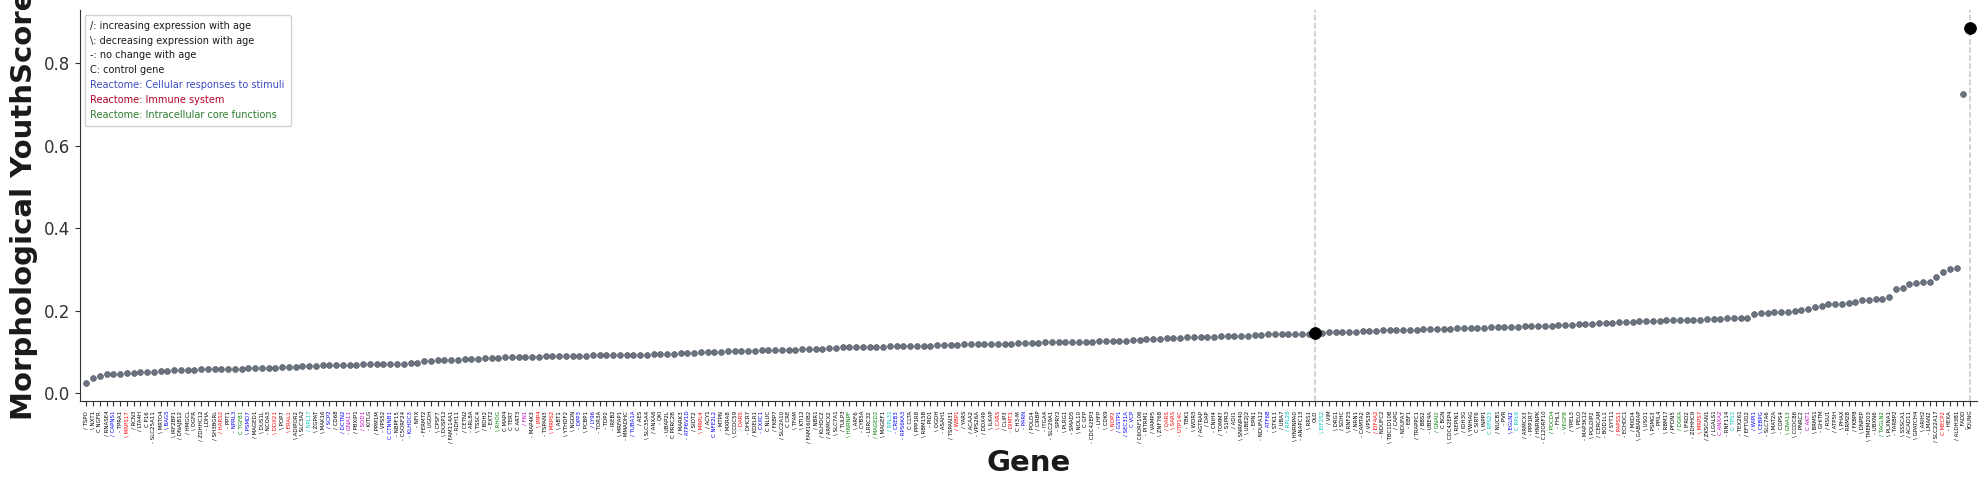

In [343]:
plot_rnays_waterfall(
    cpdf,
    liblabeldict['tritile'],
    liblabeldict['color'],
    gene_col="Gene",
    score_col="Morphological YouthScore",
    highlighted_genes=("OLD", "YOUNG"),
    highlighted_color="#000000",
    highlighted_size_mult=4.0,
    guideline_alpha=0.55,
    reference_line_y=None,
    symbol_labels=None,
    category_labels=None,
    ax=None,
    figsize=(20, 5),
    point_color=None,
    point_size=18,
    tick_fontsize=4,
    panel_label=None,
)
plt.savefig('./newfigures/CPYS.pdf',bbox_inches='tight')

## Panel C

In [477]:
DataDict['Figure4'].keys()

dict_keys(['RankScores_and_Other_Gene_Info', 'MorphologicalClassifierFeatures', 'RejuvenativeFraction'])

In [344]:
ClassifierFeatures=DataDict['Figure4']['MorphologicalClassifierFeatures']
ClassifierFeatures.head()

,Importance,Feature
1045,0.090526,Cytoplasm_Correlation_RWC_DNA_Mito
487,0.055671,Nucleus_Intensity_MeanIntensityEdge_ER
391,0.052783,Nucleus_Texture_DifferenceEntropy_ER_3_02_256
482,0.039735,Cytoplasm_Correlation_K_AGP_ER
85,-0.027943,Nucleus_Correlation_RWC_ER_Mito


In [345]:
CFsmall=ClassifierFeatures.iloc[0:50,:]

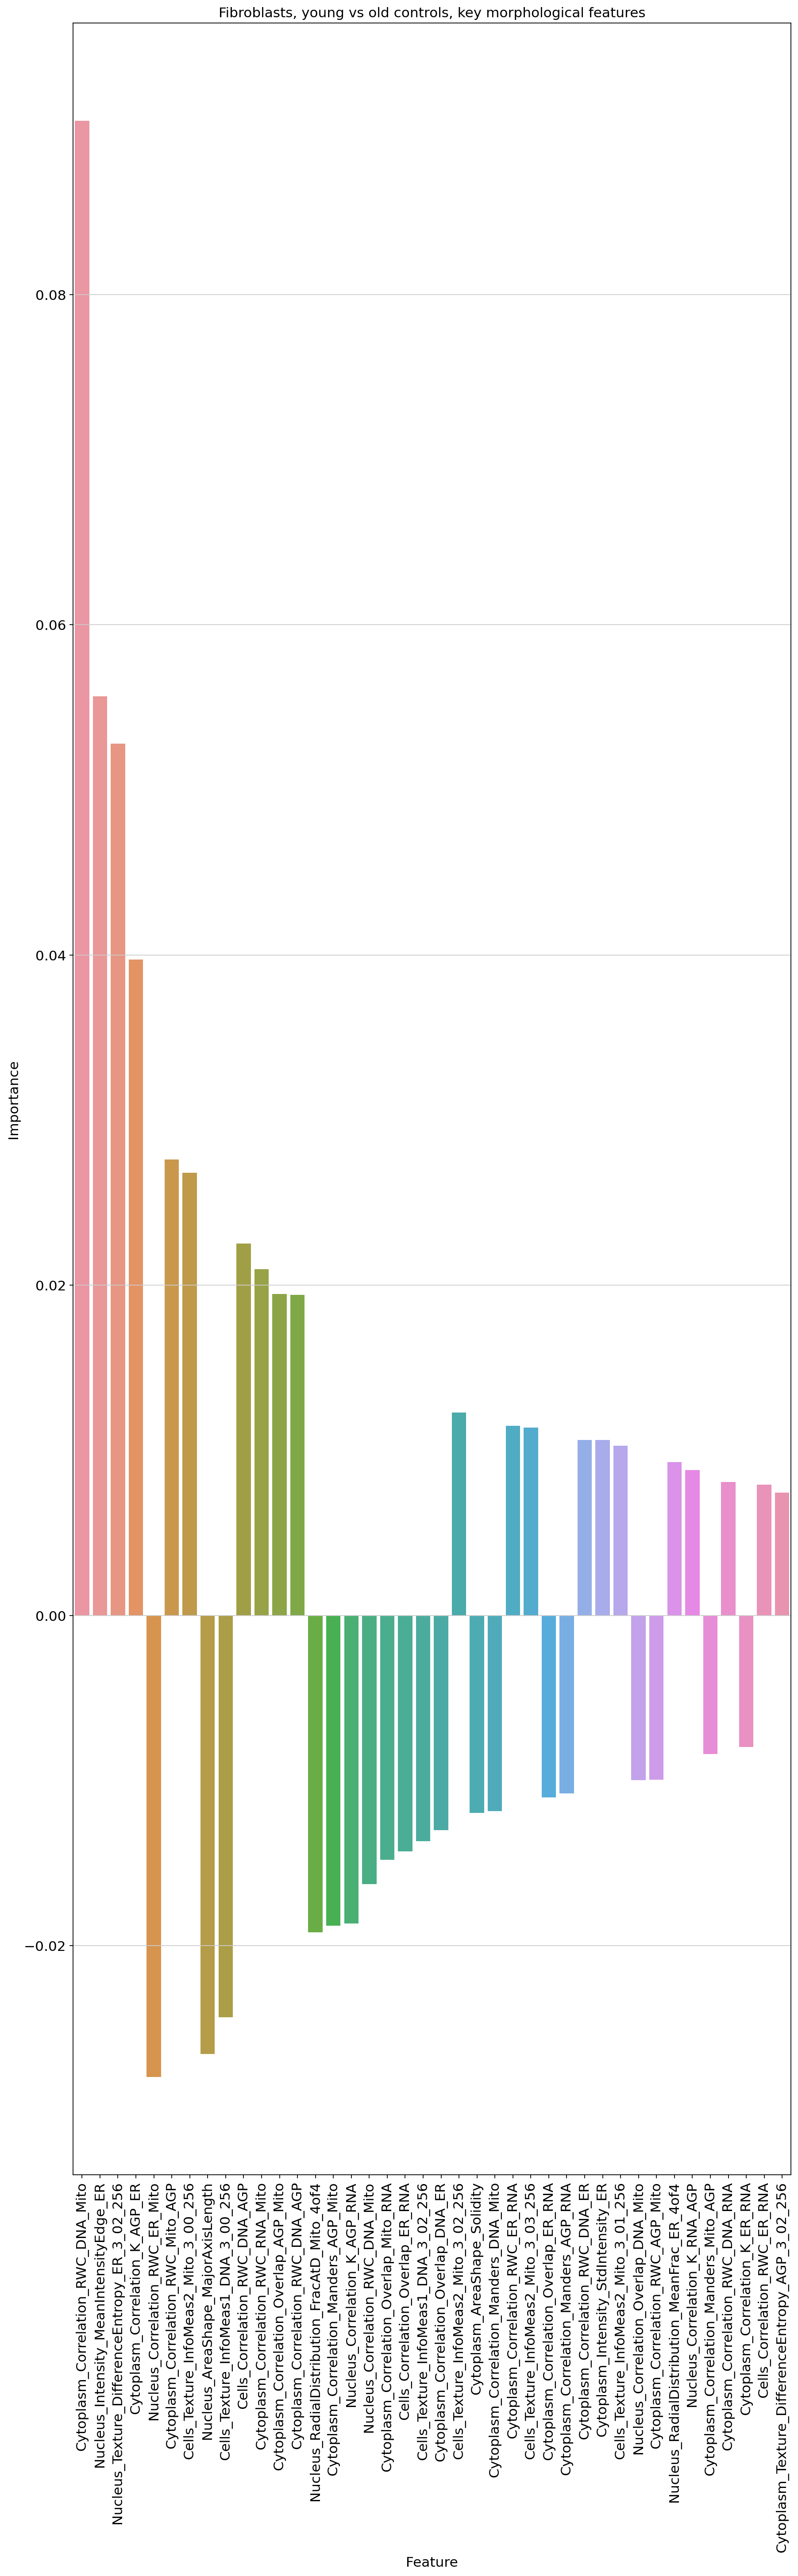

In [108]:
#plt.plot(figsize=(13,10))
fig, ax = plt.subplots(figsize=(13,40))
sns.barplot(CFsmall,x='Feature',y='Importance')
plt.xticks(rotation=90)
plt.title('Fibroblasts, young vs old controls, key morphological features in AdaBoost models')
plt.savefig('./figures/FeatureImportance_CP_signed.pdf')
plt.show()


### Claude glow-up

We can recycle what was engineered for Fig 3D

In [346]:
"""
Figure 3, Panel D -- classifier feature importance (signed Gini importance
per gene) as a horizontal bar chart, with a Reactome enrichment result
(via gseapy) shown as an inset in the chart's own whitespace.

Original figure-generating code (two separate primitives, per your
message):

    # FeatureImportance_RNA_signed2.pdf
    fig, ax = plt.subplots(figsize=(13,10))
    sns.barplot(CFsmall,x='Gene',y='Importance')
    plt.xticks(rotation=90)
    plt.title('Fibroblasts, young vs old controls, key genes in AdaBoost models')

    # fig3d_enrichrpiece.pdf (gseapy)
    ax = barplot(
        enr.results,
        column="Adjusted P-value",
        group='Gene_set',
        size=5,
        top_term=5,
        figsize=(3, 5),
        color={'Reactome_2022': 'salmon'},
    )



Usage:

    import paper_style as style
    from fig3_panelD_feature_importance import plot_panel_d

    style.apply()
    fig, ax, axins = plot_panel_d(
        CFsmall, enr.results, panel_label="d",
        color_col=None,  # or the real per-gene grouping column, if any
    )
    fig.savefig("Figure3_PanelD_feature_importance.pdf", bbox_inches="tight")

See _preview_panelD.py for the synthetic-data smoke test (not for
publication).
"""

from __future__ import annotations

import textwrap

import numpy as np
import matplotlib.pyplot as plt

import paper_style as style


def plot_feature_importance_horizontal(
    df,
    gene_col="Gene",
    importance_col="Importance",
    color_col=None,
    n_color_blocks=9,
    ax=None,
    figsize=(6.6, 11.5),
    bar_height=0.72,
    title="Fibroblasts, young vs old controls, key genes in AdaBoost models",
    x_label="Signed Gini importance",
    y_label="Gene",
    gene_label_fontsize=6.5,
    panel_label=None,
):
    """Horizontal (rotated 90 degrees) version of the signed Gini
    importance bar chart. Row order is preserved exactly from `df` --
    first row plots at the top. Returns (fig, ax).

    color_col: optional column name in `df` giving each gene's real
    grouping/cluster; if omitted, bars are colored in positional blocks of
    `n_color_blocks` genes each along `style.gene_importance_gradient()`.
    """
    if ax is None:
        fig, ax = plt.subplots(figsize=figsize)
    else:
        fig = ax.figure

    genes = df[gene_col].tolist()
    values = df[importance_col].to_numpy(dtype=float)
    n = len(genes)
    y = np.arange(n)

    if color_col is not None and color_col in df.columns:
        groups = df[color_col].tolist()
        uniques = list(dict.fromkeys(groups))  # first-appearance order
        gradient = style.gene_importance_gradient(len(uniques))
        color_of = dict(zip(uniques, gradient))
        bar_colors = [color_of[g] for g in groups]
    else:
        gradient = style.gene_importance_gradient(n_color_blocks)
        bar_colors = [gradient[min(i * n_color_blocks // max(n, 1), n_color_blocks - 1)]
                      for i in range(n)]

    ax.barh(
        y, values, height=bar_height, color=bar_colors,
        edgecolor=[style.darken(c, 0.25) for c in bar_colors], linewidth=0.4,
        zorder=3,
    )

    ax.axvline(0, color=style.REFERENCE_LINE_COLOR, linestyle="-", linewidth=0.9, zorder=2)
    ax.xaxis.grid(True, color="#e6e6e6", linewidth=0.8, zorder=0)
    ax.set_axisbelow(True)

    # A little breathing room so the longest bar isn't flush with the panel
    # edge (and so its value tick doesn't get clipped by bbox_inches='tight').
    v_min, v_max = float(values.min()), float(values.max())
    pad = 0.08 * (v_max - v_min if v_max > v_min else abs(v_max) or 1.0)
    ax.set_xlim(v_min - pad, v_max + pad)

    ax.set_yticks(y)
    ax.set_yticklabels(genes, fontsize=gene_label_fontsize)
    ax.invert_yaxis()  # first row of df at the TOP
    ax.set_ylim(n - 0.5, -0.5)

    # Value axis on TOP, matching the published Fig3d.pdf crop.
    ax.xaxis.tick_top()
    ax.xaxis.set_label_position("top")
    ax.set_xlabel(x_label)
    ax.set_ylabel(y_label)

    ax.spines["bottom"].set_visible(False)
    ax.spines["right"].set_visible(False)
    ax.spines["top"].set_visible(True)
    ax.spines["left"].set_visible(True)
    ax.tick_params(axis="x", direction="out", top=True, bottom=False)
    ax.tick_params(axis="y", length=0)

    if title:
        ax.text(0.5, -0.015, title, transform=ax.transAxes, ha="center", va="top",
                fontsize=10)

    if panel_label:
        ax.text(-0.18, 1.015, panel_label, transform=ax.transAxes, fontsize=14,
                fontweight="bold", va="bottom", ha="left")

    return fig, ax

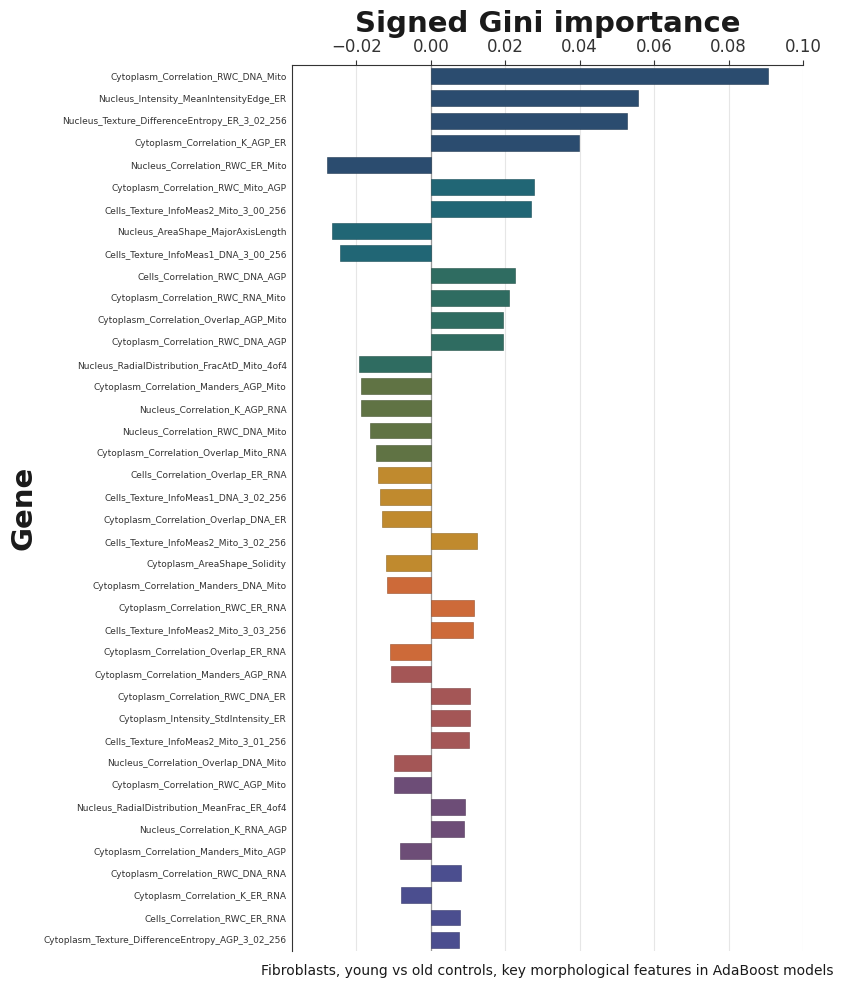

In [347]:
plot_feature_importance_horizontal(
    CFsmall,
    gene_col="Feature",
    importance_col="Importance",
    color_col=None,
    n_color_blocks=9,
    ax=None,
    figsize=(6.6, 11.5),
    bar_height=0.72,
    title="Fibroblasts, young vs old controls, key morphological features in AdaBoost models",
    x_label="Signed Gini importance",
    y_label="Gene",
    gene_label_fontsize=6.5,
    panel_label=None,
)
plt.savefig('./newfigures/FeatureImportance_CP_signed.pdf',bbox_inches='tight')

## Panel D

In [348]:
sumdf=DataDict['Figure3']['RankScores_and_Other_Gene_Info']
sumdf.head()

,Gene,RNAYS,RNA_AbFrac,YouthScore_Hybrid,MasterScore,MeanMito%,StdMito%,MeanRibo%,StdRibo%,MeanMalat%,...,NumNeither,OddsRatio,pvals,scRNA_cellcount,Master Score tritile,TF/surface marker/secreted factor,Reactome: Cellular responses to stimuli,Reactome: Intracellular core functions,Reactome: Immune system,CellCountCP
0,ANXA2,0.236025,0.069364,0.180877,-0.021485,1.625959,0.573768,0.944102,0.313470,2.361226,...,3816.0,1.645974,1.131976e-07,519.0,control,Secreted Factor,0.0,0.0,0.0,1665.0
1,OLD,0.247183,0.067234,0.145214,NaN,1.246700,0.438352,1.075207,0.388175,2.029116,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,139533.0
2,YOUNG,0.767124,0.071813,0.885398,NaN,1.318644,0.543593,1.146731,0.407127,2.057075,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,41162.0
3,TP53,0.336058,0.084910,0.181916,0.000367,1.583803,0.672274,1.184535,0.390952,1.508459,...,2010.0,0.819962,7.438840e-01,2273.0,control,Transcription Factor,0.0,0.0,0.0,3791.0
4,MRPS2,0.204873,0.059401,0.089199,0.239430,1.072958,0.924759,1.112192,0.428831,1.800366,...,1641.0,0.791076,9.970685e-01,2138.0,negative,NaN,0.0,1.0,0.0,1883.0


In [349]:
def CP_RejuvFracBootstrap(df,qle):
    # This calculates the "rejuvenative fraction" = the fraction of EXAMINED genes with transcriptomic YouthScores greater than old.
    # This will be examined for different subsets of the data. 
    df2=df[~df.MasterScore.isna()]; columns=df2.columns; n=len(df2) 
    bs=pd.DataFrame(df2.values[np.random.randint(n, size=n)], columns=columns) # Bootstrap 
    low=np.quantile(bs.MasterScore,qle)
    subdf=bs[bs.MasterScore>=low]
    return len(subdf[subdf.YouthScore_Hybrid>df[df.Gene=='OLD'].YouthScore_Hybrid.values[0]])/len(subdf)
    

In [350]:
%%time

#Now, sweep over a grid of RankScore inclusions, and bootstrap for many trials:

QuantileBox=[0.05,0.1,0.15,0.2,0.25,0.3,0.35,0.4,0.45,0.5,0.55,0.6,0.65,0.7,0.75,0.8,0.85,0.9,0.95]
ResultBox=[]
for qle in QuantileBox:
    bootstrapbox=[]
    for trial in range(1000):
        bootstrapbox.append(CP_RejuvFracBootstrap(sumdf,qle))
    ResultBox.append(bootstrapbox)

CPU times: user 38.3 s, sys: 0 ns, total: 38.3 s
Wall time: 38.3 s


In [492]:
MeanBox=[np.mean(i) for i in ResultBox]
StdBox=[np.std(i) for i in ResultBox]

Note that RESULTS MAY DIFFER (slightly -- probably inscrutably, given the number of bootstraps) because we do not pin down the RNG seed

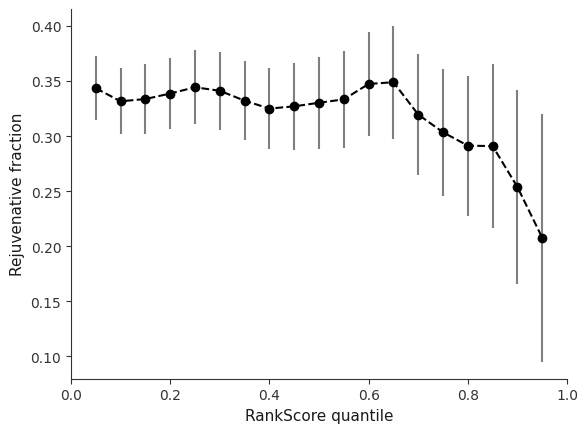

In [493]:
plt.errorbar(QuantileBox,MeanBox,StdBox,fmt='o',color='k',ecolor='tab:gray',linestyle='--')
plt.xlim([0,1])
plt.xlabel('RankScore quantile')
plt.ylabel('Rejuvenative fraction')

plt.savefig('./figures/RejuvenativeFractions_Cellpaint.pdf')

### Claude glow-up

Let's again recycle from earlier figures, here Fig 3F

In [351]:
"""
Figure 3, Panel F -- rejuvenative fraction vs. RankScore quantile, redesigned
around the fact that each of the 19 x-positions IS a full bootstrapped
distribution (1000 numbers), not just a mean and a standard deviation.

Original figure-generating code:

    QuantileBox=[0.05,0.1,0.15,0.2,0.25,0.3,0.35,0.4,0.45,0.5,0.55,0.6,0.65,
                 0.7,0.75,0.8,0.85,0.9,0.95]
    MeanBox=[np.mean(i) for i in ResultBox]
    StdBox=[np.std(i) for i in ResultBox]
    plt.errorbar(QuantileBox,MeanBox,StdBox,fmt='o',color='k',ecolor='tab:gray',
                 linestyle='--')
    plt.xlim([0,1])
    plt.xlabel('RankScore quantile')
    plt.ylabel('Rejuvenative fraction')

Same underlying data (`ResultBox`, a list of 19 arrays -- the full
bootstrapped distribution behind each quantile bin), and the same headline
trend (a flat-ish plateau around ~0.20 that breaks downward in the top
quantiles) -- but per your explicit note that the point+whisker version
"is much too plain" and should "leverage the fact that each of the 19
points ... is a 1000-number distribution," this is a full redesign rather
than a restyle:

  1. EACH X-POSITION IS NOW A VIOLIN, not a mean dot + a symmetric std bar.
     `ax.violinplot()` draws the actual kernel-density SHAPE of each
     bootstrap distribution (skew, bimodality, tail weight -- anything a
     mean+std pair throws away is visible here), restyled to house spec:
     flat house TEAL fill (not matplotlib's default purple/blue violin
     colors), no default black min/max whisker spike through the middle
     (`showextrema=False` -- replaced by the quartile/percentile overlay in
     #2, which is more informative and less visually busy than the
     built-in one anyway).

  2. QUARTILE + 5TH/95TH PERCENTILE OVERLAY drawn BY HAND directly from each
     bootstrap array (`np.percentile`, not `np.std`) inside each violin: a
     thick short IQR bar (Q1-Q3), a median dot, and a thin 5th-95th whisker
     -- i.e. this keeps every honest summary statistic the original
     errorbar-style plot showed (in fact adds the median, which the
     original never computed -- it only ever plotted the MEAN), while the
     violin body around it shows the shape those numbers were summarizing.
     Using real percentiles rather than mean +/- std also means a skewed
     bootstrap distribution (very plausible for a bounded fraction sitting
     near a floor/ceiling) is represented honestly instead of implying a
     symmetric spread it may not have.

  3. MEDIAN TREND LINE connects the 19 medians (solid, darkened TEAL) --
     carries forward the one thing the original's dashed connecting line
     was for (showing the trend across quantiles) without implying, the
     way a single dot does, that each quantile bin reduces to one number.

  4. HOUSE COLOR: TEAL -- the one house accent not yet used anywhere else
     in Figure 3 (B/C = slate+black/ink_blue, D = the full gradient+gold,
     E = slate+terracotta), so Panel F reads as its own distinct series
     while still drawing from the same six-color house set.

This is ONE proposed redesign (a "violin + quartile overlay" hybrid,
sometimes called a raincloud plot without the raw-point cloud, dropped here
since 1000 points x 19 bins would be too dense to read as individual dots
even at low alpha) -- if you'd rather see a ridgeline/joyplot instead (each
distribution as a horizontal density curve, offset vertically), or the raw
per-quantile histograms as small multiples, say so and I'll build that
version instead.

Usage:

    import paper_style as style
    from fig3_panelF_rejuvenative_fractions import plot_rejuvenative_fractions

    style.apply()
    fig, ax = plot_rejuvenative_fractions(ResultBox, panel_label="f")
    fig.savefig("Figure3_PanelF_rejuvenative_fractions.pdf", bbox_inches="tight")

See _preview_panelF.py for the synthetic-data smoke test (not for
publication).
"""

from __future__ import annotations

import numpy as np
import matplotlib.pyplot as plt

import paper_style as style

QUANTILE_BOX = [0.05, 0.1, 0.15, 0.2, 0.25, 0.3, 0.35, 0.4, 0.45, 0.5, 0.55,
                 0.6, 0.65, 0.7, 0.75, 0.8, 0.85, 0.9, 0.95]

VIOLIN_COLOR = style.TEAL


def plot_rejuvenative_fractions(
    result_box,
    quantile_box=None,
    ax=None,
    figsize=(7.2, 5.4),
    violin_color=VIOLIN_COLOR,
    violin_width=0.035,
    violin_alpha=0.55,
    iqr_linewidth=3.2,
    whisker_linewidth=1.0,
    median_markersize=5.5,
    x_label="RankScore quantile",
    y_label="Rejuvenative fraction",
    panel_label=None,
):
    """Redesigned Panel F: one violin per RankScore-quantile bin (kernel
    density of that bin's full bootstrapped distribution), with a hand-drawn
    median/IQR/5th-95th-percentile overlay and a connecting median trend
    line. Returns (fig, ax).

    `result_box` is `ResultBox` from the original code: a sequence of 19
    arrays/lists, each the full bootstrapped-fraction distribution for one
    quantile bin (matched positionally to `quantile_box`, default
    `QUANTILE_BOX` == the original `QuantileBox`).
    """
    if ax is None:
        fig, ax = plt.subplots(figsize=figsize)
    else:
        fig = ax.figure

    if quantile_box is None:
        quantile_box = QUANTILE_BOX

    distributions = [np.asarray(d, dtype=float) for d in result_box]
    x = np.asarray(quantile_box, dtype=float)

    edge_color = style.darken(violin_color, 0.35)
    stat_color = style.darken(violin_color, 0.55)

    parts = ax.violinplot(
        distributions, positions=x, widths=violin_width,
        showmeans=False, showmedians=False, showextrema=False,
    )
    for body in parts["bodies"]:
        body.set_facecolor(violin_color)
        body.set_edgecolor(edge_color)
        body.set_alpha(violin_alpha)
        body.set_linewidth(0.6)
        body.set_zorder(3)

    medians = np.array([np.median(d) for d in distributions])
    q1 = np.array([np.percentile(d, 25) for d in distributions])
    q3 = np.array([np.percentile(d, 75) for d in distributions])
    p05 = np.array([np.percentile(d, 5) for d in distributions])
    p95 = np.array([np.percentile(d, 95) for d in distributions])

    # Thin 5th-95th whisker, then a thick short IQR bar, then the median dot
    # -- drawn in that back-to-front order so the eye reads it as one
    # increasingly-precise summary rather than three competing marks.
    ax.vlines(x, p05, p95, color=stat_color, linewidth=whisker_linewidth,
               zorder=4, alpha=0.8)
    ax.vlines(x, q1, q3, color=stat_color, linewidth=iqr_linewidth,
               zorder=5, capstyle="round")
    # Median trend line first (so the dots sit on top of it), then the dots.
    ax.plot(x, medians, color=stat_color, linewidth=1.4, zorder=6, alpha=0.9)
    ax.plot(x, medians, "o", color="white", markeredgecolor=stat_color,
            markeredgewidth=1.3, markersize=median_markersize, zorder=7)

    ax.set_xlim(0, 1)
    ax.set_xlabel(x_label)
    ax.set_ylabel(y_label)
    style.despine_clean(ax)

    if panel_label:
        ax.text(-0.14, 1.03, panel_label, transform=ax.transAxes, fontsize=14,
                fontweight="bold", va="bottom", ha="left")

    fig.tight_layout()
    return fig, ax


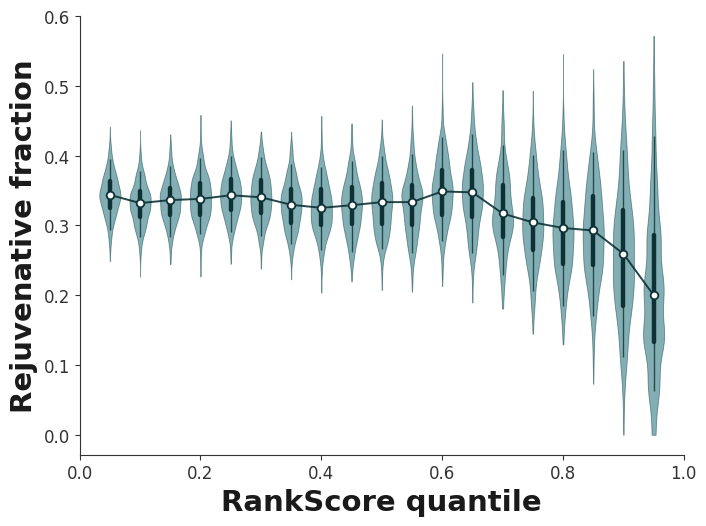

In [352]:
plot_rejuvenative_fractions(
    ResultBox,
    quantile_box=None,
    ax=None,
    figsize=(7.2, 5.4),
    violin_color=VIOLIN_COLOR,
    violin_width=0.035,
    violin_alpha=0.55,
    iqr_linewidth=3.2,
    whisker_linewidth=1.0,
    median_markersize=5.5,
    x_label="RankScore quantile",
    y_label="Rejuvenative fraction",
    panel_label=None,
)
plt.savefig('./newfigures/RejuvenativeFractions_CP.pdf',bbox_inches='tight')

# Figure 5

Panel B was made in Inkscape

In [50]:
DataDict['Figure5'].keys()

dict_keys(['ResultsCorrelations', 'AblationX', 'AblationY', 'AblationSize', 'AblationColor', 'Node2VecObs', 'Node2VecUMAP'])

## Panel A

In [6]:
DataDict['Figure5'].keys()

dict_keys(['ResultsCorrelations', 'AblationX', 'AblationY', 'AblationSize', 'AblationColor', 'Node2VecObs', 'Node2VecUMAP'])

In [7]:
ResCorr=DataDict['Figure5']['ResultsCorrelations']

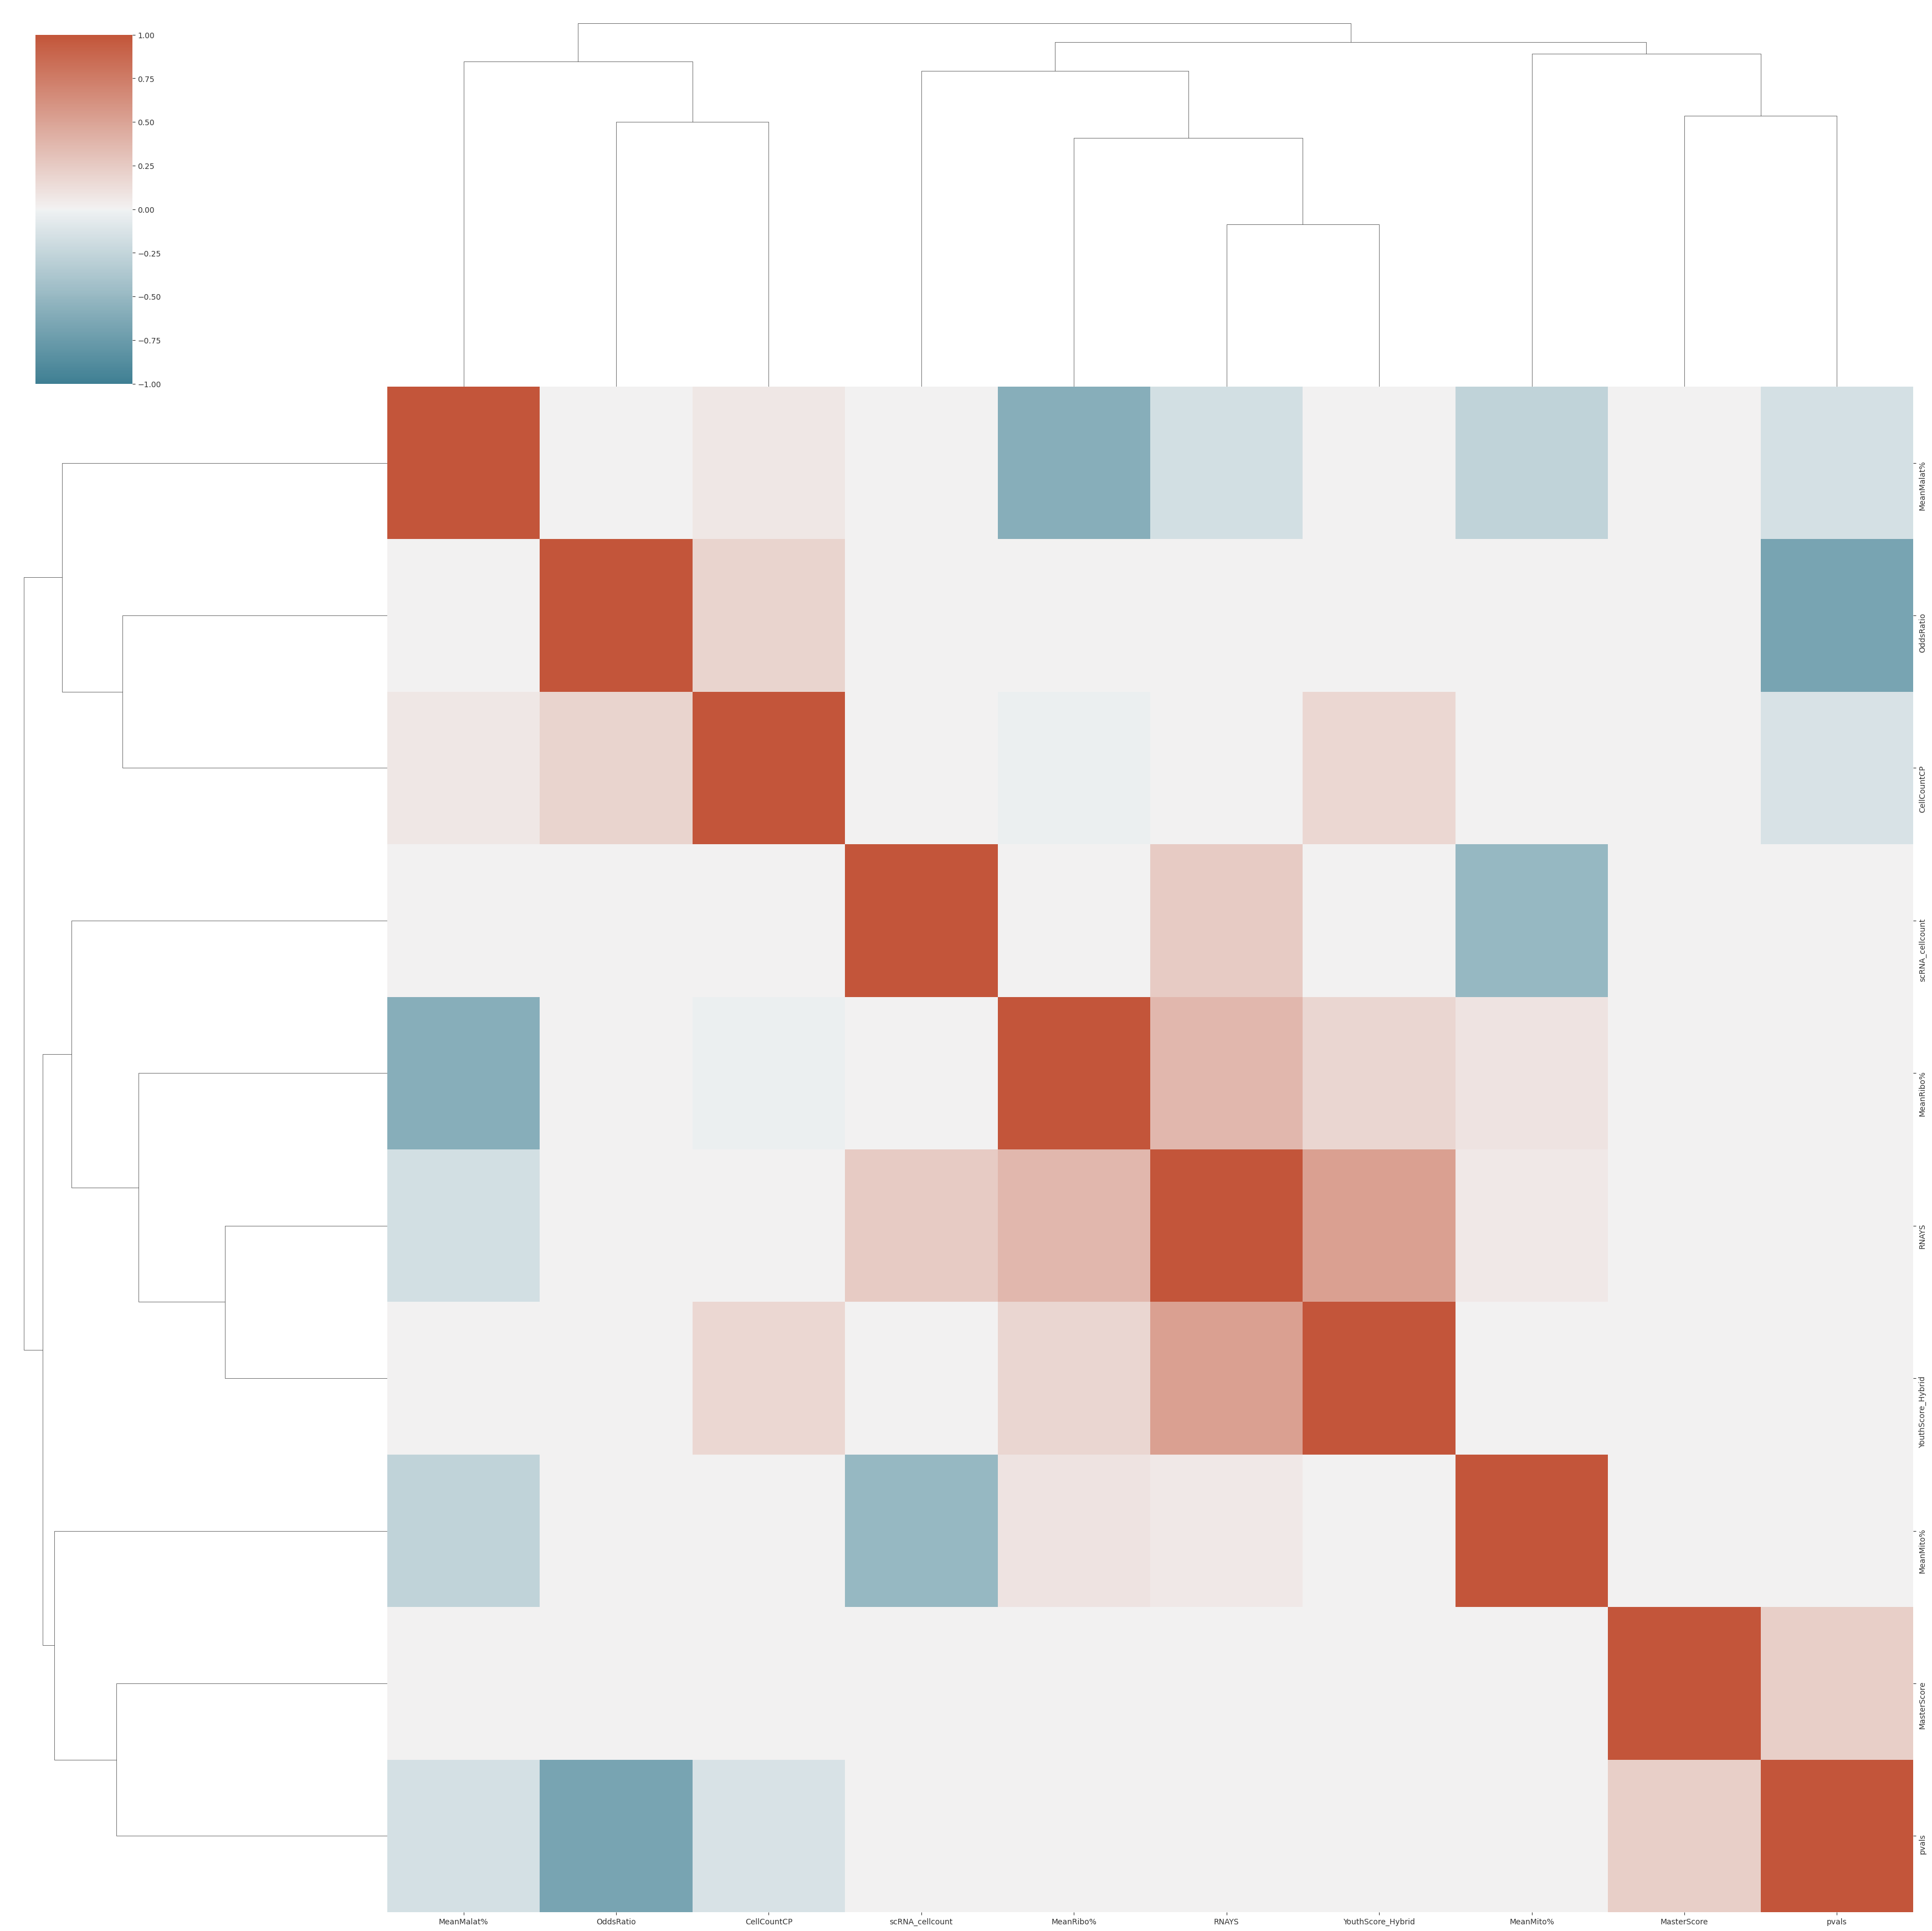

In [8]:
sns.clustermap(ResCorr,yticklabels=True, xticklabels=True, figsize=(35, 35),vmin=-1,vmax=1,cmap=sns.diverging_palette(220, 20, as_cmap=True))

plt.savefig('./figures/AllQuantitiesClusterMap_forPaper.pdf')
plt.show()

### Claude glow-up

In [353]:
"""
Figure 5, panel (a): Pearson cross-correlation matrix across every
transcriptomic + morphological quantity used in the paper, restricted to
library members present in both analyses. Rendered as a seaborn clustermap
(hierarchical clustering on both axes, same linkage as the original) so
related quantities group together.

Notebook usage (same pattern as every other panel in this project -- run
from a notebook one level under PaperFigParts2, `ResCorr` already exists
as a live variable from your own upstream cells, nothing here reads it
from disk):

    import sys
    from pathlib import Path
    sys.path.insert(0, str(Path("..").resolve()))
    import paper_style as style
    from fig5_panelA_correlation_matrix import plot_correlation_clustermap

    style.apply()
    g = plot_correlation_clustermap(ResCorr)
    g.savefig("AllQuantitiesClusterMap.pdf", bbox_inches="tight")

`ResCorr` is the real correlation dataframe (square, symmetric, index ==
columns == the raw variable names in DISPLAY_LABELS below) -- the exact
object already passed to sns.clustermap in the original one-line version
of this panel:

    sns.clustermap(ResCorr, yticklabels=True, xticklabels=True,
                   figsize=(35, 35), vmin=-1, vmax=1,
                   cmap=sns.diverging_palette(220, 20, as_cmap=True))

This module has no `if __name__ == "__main__":` block on purpose -- it's
imported and called from your notebook, not run as a standalone script.
"""

from typing import Optional

import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

import paper_style as style

# ---- Raw variable name -> published display label -------------------------
# Order matches the dendrogram leaf order in both the raw
# AllQuantitiesClusterMap_forPaper.pdf output and the published Fig5a.pdf
# crop (confirmed 2026-09-02 by comparing the two side by side -- both list
# the same 10 quantities in the same order), so this is a straight rename,
# never a reorder. Keep this dict in sync if a quantity is ever added to or
# dropped from ResCorr.
DISPLAY_LABELS = {
    "MeanMalat%": "Mean MALAT1 %",
    "OddsRatio": "Fisher Odds Ratio",
    "CellCountCP": "Morphological Cell Count",
    "scRNA_cellcount": "Transcriptomic Cell Count",
    "MeanRibo%": "Mean Ribosomal %",
    "RNAYS": "Transcriptomic YouthScore",
    "YouthScore_Hybrid": "Morphological YouthScore",
    "MeanMito%": "Mean Mitochondrial %",
    "MasterScore": "RankScore",
    "pvals": "Fisher p-value",
}


def plot_correlation_clustermap(
    corr_df,
    display_labels: Optional[dict] = None,
    figsize=(9, 9),
    xtick_rotation=45,
    cbar_pos=(0.02, 0.82, 0.03, 0.15),
):
    """House-styled replacement for the raw one-liner (see module
    docstring). Everything here is aimed at getting the *code's* output to
    already match Fig5a.pdf, with no Inkscape touch-up pass needed:

      - Row/column ticks renamed to the published display labels via
        `display_labels` -- renames a *copy* of the index/columns, `corr_df`
        itself is untouched.
      - figsize brought down from the original 35x35in canvas (which only
        read correctly because the labels were enlarged/repositioned by
        hand afterward) to a normal ~9x9in figure sized to this house
        style's 11pt base font, so labels are legible at their natural
        size straight out of matplotlib.
      - x tick labels rotated (`xtick_rotation`, default 45 deg,
        right-aligned, anchored) so the long labels ("Transcriptomic
        YouthScore" etc.) read cleanly under each column without
        overlapping; y tick labels stay horizontal on the right, matching
        Fig5a. Bump `xtick_rotation` here (a single call-site argument) if
        45 deg still isn't quite what you want -- no need to hand-edit
        tick objects afterward.
      - Swapped `sns.diverging_palette(220, 20)` for
        `style.diverging_corr_cmap()` -- a TEAL/white/TERRACOTTA diverging
        map built from the house accents, visually close to the original
        blue-teal/red-orange but drawn from the same palette as every
        other panel instead of a generic seaborn default. Revert to the
        original `sns.diverging_palette(220, 20, as_cmap=True)` at the
        call site if you'd rather keep the exact original hues.
      - Dendrogram lines forced to a flat REFERENCE_LINE_COLOR gray via
        `tree_kws` instead of seaborn's default near-black -- the
        dendrogram is structural annotation, not data, so it follows the
        same "gray = reference, color = data" convention used everywhere
        else in this figure set.
      - Colorbar given an explicit two-line "Pearson / correlation" title
        and fixed ticks at 0.25 increments from -1 to 1, matching Fig5a.

    Returns the `sns.matrix.ClusterGrid` so the caller can do any final
    per-run tweaks before saving (e.g. `g.savefig(...)`).

    `display_labels` defaults to `None` (resolved to the module-level
    `DISPLAY_LABELS` inside the function body) rather than defaulting
    directly to `DISPLAY_LABELS` in the signature -- a default argument
    value is bound once, at `def` time, so pointing it straight at a
    module-level dict is a known notebook footgun: re-running just this
    function's cell (e.g. after `%autoreload` reloads the module, or after
    a kernel restart where cells got re-run out of order) can bind against
    a stale or not-yet-defined `DISPLAY_LABELS`. Resolving it inside the
    function body instead means every call always reads the *current*
    `DISPLAY_LABELS`, however the module got (re)loaded.
    """
    if display_labels is None:
        display_labels = DISPLAY_LABELS
    plot_df = corr_df.rename(index=display_labels, columns=display_labels)

    g = sns.clustermap(
        plot_df,
        yticklabels=True,
        xticklabels=True,
        figsize=figsize,
        vmin=-1,
        vmax=1,
        cmap=style.diverging_corr_cmap(),
        linewidths=0.4,
        linecolor="white",
        tree_kws=dict(color=style.REFERENCE_LINE_COLOR, linewidths=0.8),
        cbar_pos=cbar_pos,
    )

    ax = g.ax_heatmap
    ax.set_xlabel("")
    ax.set_ylabel("")
    plt.setp(
        ax.get_xticklabels(),
        rotation=xtick_rotation,
        ha="right",
        rotation_mode="anchor",
    )
    plt.setp(ax.get_yticklabels(), rotation=0)
    ax.tick_params(length=0)

    for side_ax in (g.ax_row_dendrogram, g.ax_col_dendrogram):
        side_ax.set_facecolor("white")

    cbar = g.ax_cbar
    cbar.set_title("Pearson\ncorrelation", fontsize=10, pad=8)
    ticks = np.arange(-1.0, 1.01, 0.25)
    cbar.set_yticks(ticks)
    cbar.set_yticklabels([f"{t:.2f}" for t in ticks])

    return g


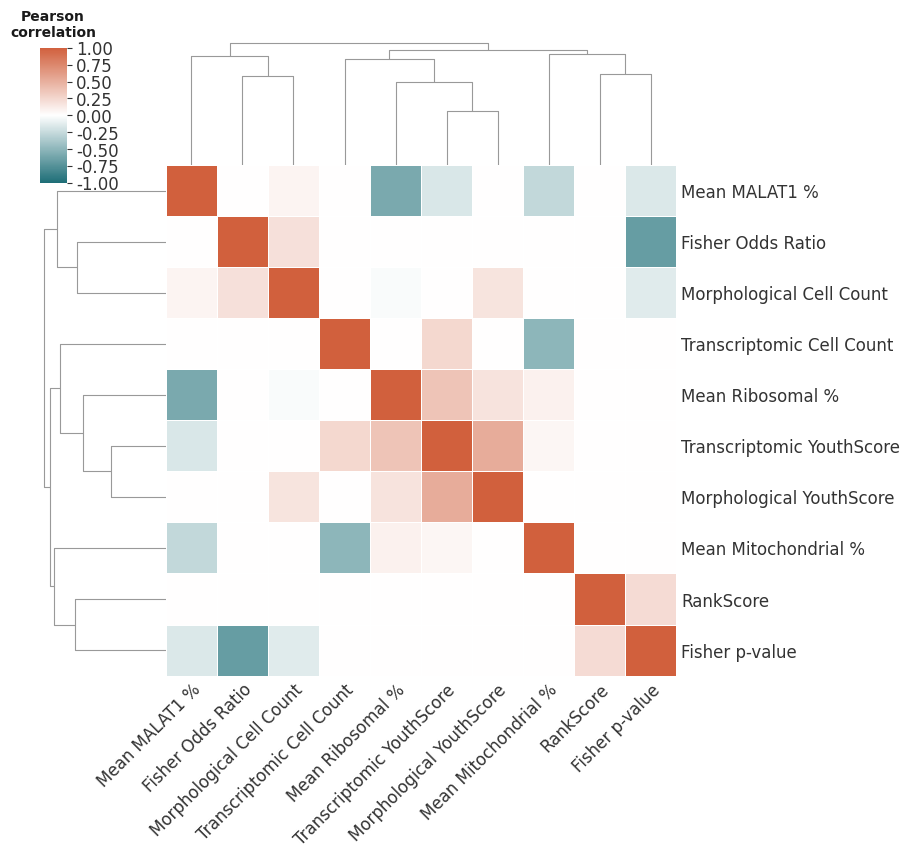

In [354]:
plot_correlation_clustermap(
    ResCorr,
    display_labels=None,
    figsize=(9, 9),
    xtick_rotation=45,
    cbar_pos=(0.02, 0.82, 0.03, 0.15),
)
plt.savefig('./newfigures/AllQuantitiesClusterMap.pdf',bbox_inches='tight')

## Panel C

In [120]:
DataDict['Figure5'].keys()

dict_keys(['ResultsCorrelations', 'AblationX', 'AblationY', 'AblationSize', 'AblationColor', 'Node2VecObs', 'Node2VecUMAP'])

In [40]:
AbX=DataDict['Figure5']['AblationX']
AbY=DataDict['Figure5']['AblationY']
AbS=DataDict['Figure5']['AblationSize']
AbC=DataDict['Figure5']['AblationColor']

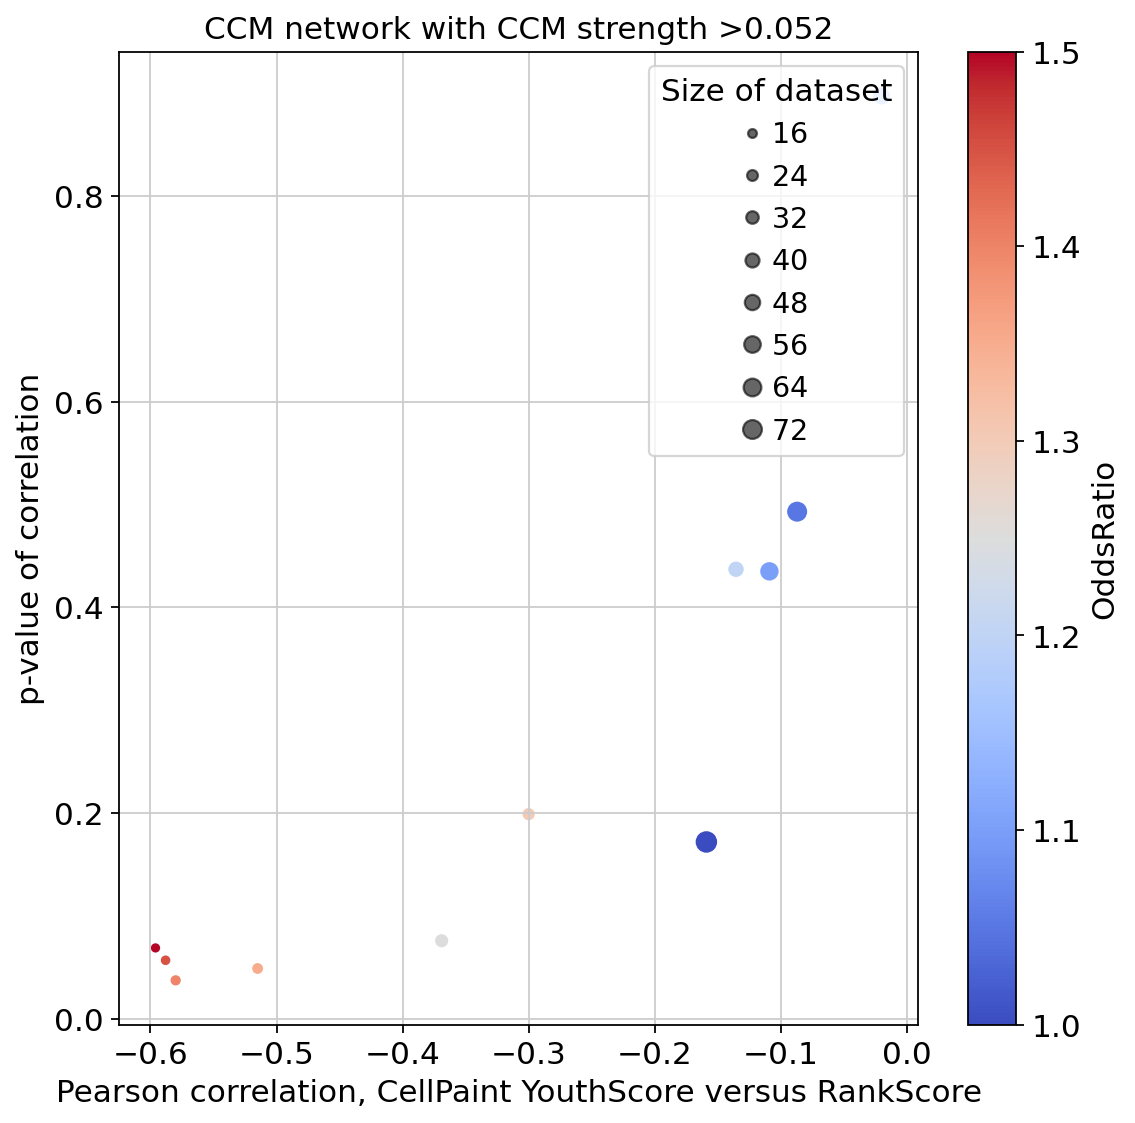

In [124]:
fig, ax = plt.subplots(figsize=(8,8))
sc=ax.scatter(AbX,AbY,s=AbS,c=AbC,cmap='coolwarm')

cbar = fig.colorbar(sc, ax=ax)
cbar.set_label('OddsRatio') # Add a label to the colorbar

handles, labels = sc.legend_elements(prop="sizes", alpha=0.6)
legend2 = ax.legend(handles, labels, loc="upper right", title="Size of dataset")


ax.set_xlabel('Pearson correlation, CellPaint YouthScore versus RankScore')
ax.set_ylabel('p-value of correlation')
ax.set_title('CCM network with CCM strength >0.052')

plt.savefig('./figures/CCMs052CP_OR_ablation_diffcolor.pdf')
plt.show()

### Claude glow-up

In [355]:
"""
Figure 5, panel (c): Pearson correlation (CellPaint YouthScore vs.
RankScore) against its p-value, across CCM sub-networks built with a
looser correlation-strength cutoff than the main text uses -- point size
encodes the size of each subset's dataset, point color encodes the
accompanying Fisher Exact odds ratio for that subset's "well-mappedness".

Notebook usage (same pattern as every other panel in this project --
`AbX`/`AbY`/`AbS`/`AbC` already exist as live variables from your own
upstream cells):

    import sys
    from pathlib import Path
    sys.path.insert(0, str(Path("..").resolve()))
    import paper_style as style
    from fig5_panelC_ccm_ablation import plot_ccm_ablation_scatter

    style.apply()
    fig, ax = plot_ccm_ablation_scatter(
        AbX, AbY, AbS, AbC, title="CCM network with CCM strength >0.052"
    )
    fig.savefig("CCMs052CP_OR_ablation.pdf", bbox_inches="tight")

`AbX`, `AbY`, `AbS`, `AbC` are the same four parallel arrays already passed
to the raw one-off version of this panel:

    fig, ax = plt.subplots(figsize=(8,8))
    sc = ax.scatter(AbX, AbY, s=AbS, c=AbC, cmap='coolwarm')
    cbar = fig.colorbar(sc, ax=ax)
    cbar.set_label('OddsRatio')
    handles, labels = sc.legend_elements(prop="sizes", alpha=0.6)
    legend2 = ax.legend(handles, labels, loc="upper right", title="Size of dataset")
    ax.set_xlabel('Pearson correlation, CellPaint YouthScore versus RankScore')
    ax.set_ylabel('p-value of correlation')
    ax.set_title('CCM network with CCM strength >0.052')

This module has no `if __name__ == "__main__":` block and never defaults a
parameter straight to a mutable module-level object, for the same reasons
logged in fig5_panelA_correlation_matrix.py / the project's Notebook usage
note -- both are standing rules for every panel module now, not just that
one.
"""

import matplotlib.pyplot as plt

import paper_style as style


def plot_ccm_ablation_scatter(
    x,
    y,
    sizes,
    color_values,
    title,
    xlabel="Pearson correlation, CellPaint YouthScore versus RankScore",
    ylabel="p-value of correlation",
    color_label="Fisher Odds Ratio",
    size_legend_title="Size of dataset",
    figsize=(7, 7),
    zero_ref=True,
):
    """House-styled replacement for the raw one-off scatter (see module
    docstring). Changes:

      - Swapped the generic `cmap='coolwarm'` for
        `style.sequential_accent_cmap(style.TERRACOTTA)` -- a plain
        white -> TERRACOTTA sequential ramp. 'coolwarm' is a DIVERGING
        map, which implies a meaningful crossing point at its visual
        midpoint; that's misleading here since OddsRatio only ever moves
        in one meaningful direction in this plot (stronger association =
        higher), and its own reference value (OddsRatio == 1, "no
        association") sits at the low end of the plotted range, not the
        middle. Reused TERRACOTTA (rather than a new accent) since Fig5 A
        already uses TERRACOTTA for "more positive" in its own
        correlation matrix, so "warm = stronger/more positive" reads
        consistently across both panels of this figure. Revert to
        `cmap='coolwarm'` at the call site if you'd rather keep the
        original diverging look.
      - Colorbar label renamed "OddsRatio" -> "Fisher Odds Ratio",
        matching the exact display name Panel A already uses for the same
        quantity, so the two panels of this figure refer to it
        identically.
      - Size-legend swatches explicitly colored SLATE (`legend_elements`
        defaults to plain black) -- SLATE is this project's shared
        "neutral/bookkeeping" color, appropriate here since the size
        legend explains dataset size, not the panel's headline data
        value (that's what the color axis is for).
      - Optional dashed REFERENCE_LINE_COLOR vertical guide at x=0
        (`zero_ref`, default True): "no correlation" is a real, meaningful
        reference value here (every point in this panel sits at a
        negative Pearson correlation), so it gets the same reference-line
        treatment as any other meaningful cutoff/threshold elsewhere in
        this figure set rather than being left implicit at the axis edge.
      - Baseline polish the raw version didn't have: despined axes, no
        legend border (house `legend.frameon: False`, set globally by
        `style.apply()`), Helvetica labels.

    Returns (fig, ax) so the caller can do any final per-run tweaks (e.g.
    `fig.savefig(...)`) before saving.
    """
    fig, ax = plt.subplots(figsize=figsize)

    cmap = style.sequential_accent_cmap(style.TERRACOTTA)
    sc = ax.scatter(
        x,
        y,
        s=sizes,
        c=color_values,
        cmap=cmap,
        edgecolors=style.darken(style.TERRACOTTA, 0.35),
        linewidths=0.5,
    )

    if zero_ref:
        ax.axvline(
            0,
            color=style.REFERENCE_LINE_COLOR,
            linestyle="--",
            linewidth=1,
            zorder=0,
        )

    cbar = fig.colorbar(sc, ax=ax, shrink=0.85)
    cbar.set_label(color_label)
    cbar.outline.set_linewidth(0.8)

    handles, labels = sc.legend_elements(
        prop="sizes", alpha=0.9, color=style.SLATE
    )
    ax.legend(handles, labels, loc="upper right", title=size_legend_title)

    ax.set_xlabel(xlabel)
    ax.set_ylabel(ylabel)
    ax.set_title(title)
    style.despine_clean(ax)

    return fig, ax


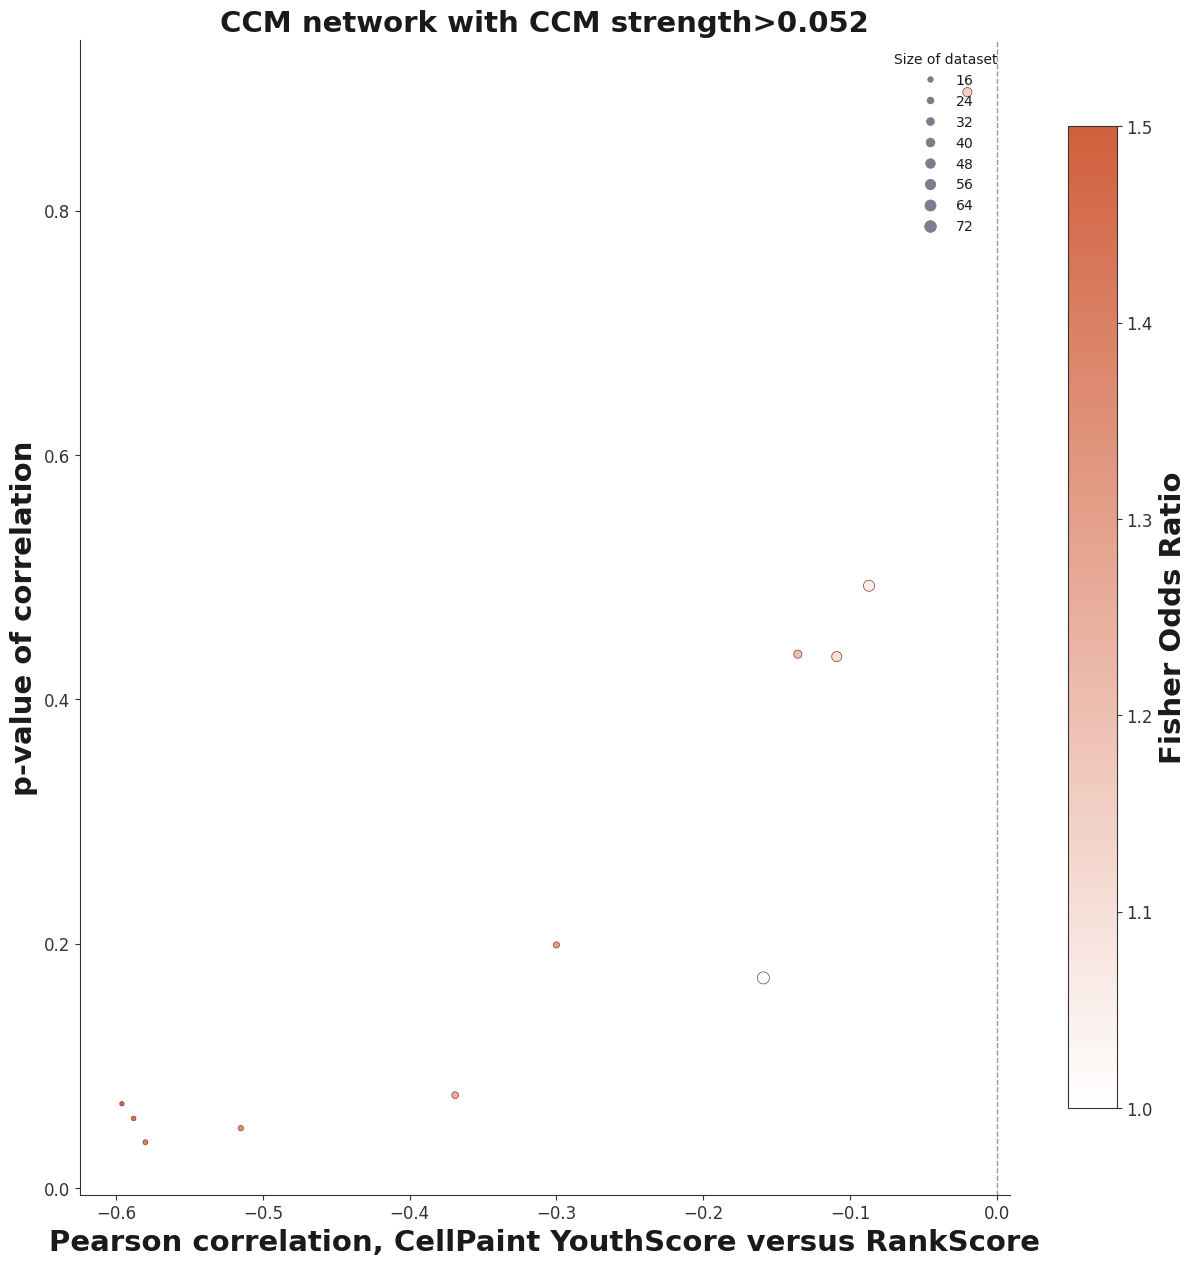

In [360]:
plot_ccm_ablation_scatter(
    AbX,
    AbY,
    AbS,
    AbC,
    'CCM network with CCM strength>0.052',
    xlabel="Pearson correlation, CellPaint YouthScore versus RankScore",
    ylabel="p-value of correlation",
    color_label="Fisher Odds Ratio",
    size_legend_title="Size of dataset",
    figsize=(15,15),
    zero_ref=True,
)
plt.savefig('./newfigures/AblationFig.pdf',bbox_inches='tight')

## Panel D

Because AnnData objects do not always play nice with Pickle, this is stored as a separate data asset

In [58]:
adata=sc.read("./data/FibroPaperDataDict_MostCurrent/n2v.h5ad")
adata

AnnData object with n_obs × n_vars = 5953 × 65
    obs: 'clusters', 'RNAYS', 'YouthScore_Hybrid', 'MasterScore', 'AgeScore', 'AgeScore2', 'IsRejuvenative', 'IsRejuvenative2', 'IsRejuvenativeAlpha'
    uns: 'clusters_colors', 'leiden', 'neighbors', 'umap'
    obsm: 'X_pca', 'X_umap'
    obsp: 'connectivities', 'distances'

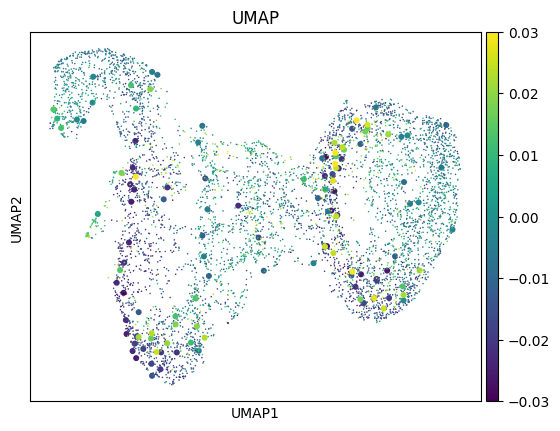

In [90]:
sc.pl.umap(adata, color='AgeScore', legend_loc='on data', title='UMAP',size=5+7*adata.obs.IsRejuvenative,vmin=-0.03,vmax=0.03,save='_N2V.pdf')#,alpha=adata.obs.IsRejuvenativeAlpha)#,save='UMAP_N2V_AS.pdf')


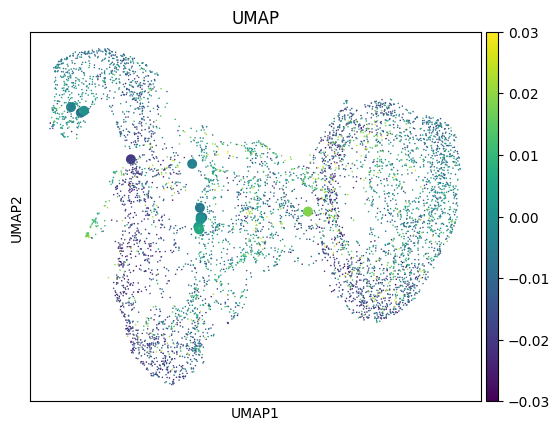

In [91]:
sc.pl.umap(adata, color='AgeScore', legend_loc='on data', title='UMAP',size=5+200*adata.obs.newpred,vmin=-0.03,vmax=0.03,save='_WhereBlackStarsGo.pdf')#,alpha=adata.obs.newpred)#,alpha=adata.obs.IsRejuvenativeAlpha)#,save='UMAP_N2V_AS.pdf')


### Claude glow-up

In [85]:
"""
Figure 5, panel (d): Node2Vec embedding of the CCM network, shown as a
UMAP. Every point is a gene; color encodes the slope of its best-fit line
to its quasi-time series (the base heuristic's node-weighting scheme).
Tested library members with rejuvenative effects are drawn much larger;
black stars mark genes the model predicts are rejuvenative but which
were never tested.

This replaces a two-PDF-plus-Inkscape workflow with one script. The raw
version was two separate `sc.pl.umap` calls whose outputs were manually
combined by eye in Inkscape:

    # umap_N2V.pdf -- base cloud + big colored circles for TESTED
    # rejuvenative library members (size *is* the IsRejuvenative2 column):
    sc.pl.umap(adata, color='AgeScore2', legend_loc='on data', title='UMAP',
               size=adata.obs.IsRejuvenative2, vmin=-0.03, vmax=0.03,
               save='_N2V.pdf')

    # umap_WhereBlackStarsGo.pdf -- same base cloud, but sized to blow up
    # the ~10 PREDICTED-BUT-UNTESTED genes (newpred) into big dots, used
    # only as a visual reference for tracing black stars onto the final
    # figure BY HAND in Inkscape afterward:
    sc.pl.umap(adata, color='AgeScore2', legend_loc='on data', title='UMAP',
               size=5+200*adata.obs.newpred, vmin=-0.03, vmax=0.03,
               save='_WhereBlackStarsGo.pdf')

Below, `newpred` drives real black-star markers directly -- nothing needs
tracing by hand anymore.

Notebook usage (same pattern as every other panel in this project --
`adata` already exists as a live object from your own upstream cells):

    import sys
    from pathlib import Path
    sys.path.insert(0, str(Path("..").resolve()))
    import paper_style as style
    from fig5_panelD_umap_node2vec import plot_umap_rejuvenative_stars

    style.apply()
    umap1, umap2 = adata.obsm["X_umap"].T
    fig, ax = plot_umap_rejuvenative_stars(
        umap1,
        umap2,
        adata.obs["AgeScore2"].to_numpy(),
        adata.obs["IsRejuvenative2"].to_numpy(),
        adata.obs["newpred"].to_numpy(),
    )
    fig.savefig("umap_N2V_combined.pdf", bbox_inches="tight")

This module has no `if __name__ == "__main__":` block and never defaults a
parameter straight to a mutable module-level object, per the standing
notebook-module rules logged on fig5_panelA_correlation_matrix.py.
"""

import numpy as np
import matplotlib.pyplot as plt

import paper_style as style


def plot_umap_rejuvenative_stars(
    umap1,
    umap2,
    color_values,
    is_rejuvenative_tested,
    is_predicted_untested,
    color_label="Slope of best-fit line to\nquasi-time series",
    vmin=-0.03,
    vmax=0.03,
    figsize=(8, 6.5),
    background_size=5,
    tested_size=130,
    star_size=280,
):
    """House-styled, single-pass replacement for the raw two-PDF /
    Inkscape workflow (see module docstring). Everything here is aimed at
    making the ~10 predicted-but-untested genes real, unmistakable star
    markers straight out of the function -- no manual tracing step.

      - `is_rejuvenative_tested`: the raw `IsRejuvenative2` column (or any
        array-like where a nonzero value means "tested, rejuvenative").
        Those points are redrawn as enlarged circles, still colored by
        `color_values` on the SAME colormap/scale as the background -- the
        original design already distinguishes them by SIZE alone, not
        color, and that's preserved here. Given a thin white edge so they
        read as "highlighted" against the dense background regardless of
        their fill color.
      - `is_predicted_untested`: the raw `newpred` column (or any
        array-like, truthy = predicted rejuvenative but never tested).
        Drawn as solid BLACK stars (`marker='*'`) with a white edge, at
        `star_size` -- deliberately the single largest, highest-contrast,
        topmost-z-order element in the whole panel, since the user
        explicitly needs these ~10 points to stay obviously distinguishable
        from everything else regardless of what color sits underneath them.
      - Colormap: swapped scanpy's default `viridis` (a SEQUENTIAL map) for
        `style.diverging_cmap(style.PLUM, style.GOLD)` -- a genuinely
        DIVERGING map, because this quantity (a slope, vmin=-0.03/
        vmax=0.03) has a real, meaningful zero at the middle of its range
        (no trend), the mirror-image of the sequential-vs-diverging bug
        class already caught on Fig5 C (there: a diverging map used for a
        one-directional quantity; here: a sequential map used for a
        genuinely signed one). PLUM/GOLD (not `diverging_corr_cmap()`'s
        TEAL/TERRACOTTA) specifically to avoid reusing Fig5 A's
        already-meaningful correlation colors for this unrelated
        diverging quantity within the same figure (the Fig2 F lesson) --
        PLUM (low) -> white -> GOLD (high) also mirrors viridis's original
        dark-purple-to-yellow shape, so the swap doesn't change the
        panel's overall read.
      - Colorbar label rewritten to the published "Slope of best-fit line
        to quasi-time series" (Fig5a.pdf), replacing whatever raw
        obs-column name (`AgeScore2`) scanpy would otherwise auto-label it
        with.
      - Generic "UMAP" title dropped (not present in Fig5a -- the panel
        letter and external caption already say what this is); tick marks
        removed (scanpy's own convention for embedding plots, and matches
        Fig5a) but the full axes box is DELIBERATELY KEPT on all four
        sides -- an intentional exception to this project's usual
        top/right-despine rule, since Fig5a's own panel (d) keeps the full
        frame (this project's other UMAP panel, Fig2 C, does too), and an
        embedding plot has no meaningful zero-origin to despine toward.
      - Background layer gets `rasterized=True` (house convention for any
        literal, undownsampled scatter layer -- see Fig2 C's workflow #3
        lesson) as a free file-size/editing-performance safety net; the
        two highlighted layers (~100 circles, ~10 stars) stay vector since
        there's no size concern and they're the elements most likely to
        need a manual nudge later.

    Returns (fig, ax) so the caller can do any final per-run tweaks (e.g.
    `fig.savefig(...)`) before saving.
    """
    color_values = np.asarray(color_values, dtype=float)
    tested_mask = np.asarray(is_rejuvenative_tested).astype(float) > 0
    star_mask = np.asarray(is_predicted_untested).astype(bool)

    cmap = style.diverging_cmap(style.PLUM, style.GOLD)

    fig, ax = plt.subplots(figsize=figsize)

    sc0 = ax.scatter(
        umap1,
        umap2,
        s=background_size,
        c=color_values,
        cmap=cmap,
        vmin=vmin,
        vmax=vmax,
        linewidths=0,
        rasterized=True,
        zorder=1,
    )

    ax.scatter(
        np.asarray(umap1)[tested_mask],
        np.asarray(umap2)[tested_mask],
        s=tested_size,
        c=color_values[tested_mask],
        cmap=cmap,
        vmin=vmin,
        vmax=vmax,
        edgecolors="white",
        linewidths=0.6,
        zorder=2,
    )

    ax.scatter(
        np.asarray(umap1)[star_mask],
        np.asarray(umap2)[star_mask],
        s=star_size,
        marker="*",
        c="black",
        edgecolors="white",
        linewidths=1.0,
        zorder=3,
    )

    cbar = fig.colorbar(sc0, ax=ax, shrink=0.85)
    cbar.set_label(color_label)
    cbar.outline.set_linewidth(0.8)

    ax.set_xlabel("UMAP1")
    ax.set_ylabel("UMAP2")
    ax.set_xticks([])
    ax.set_yticks([])
    for side in ("top", "right", "bottom", "left"):
        ax.spines[side].set_visible(True)
        ax.spines[side].set_linewidth(0.8)
        ax.spines[side].set_color("#333333")

    return fig, ax


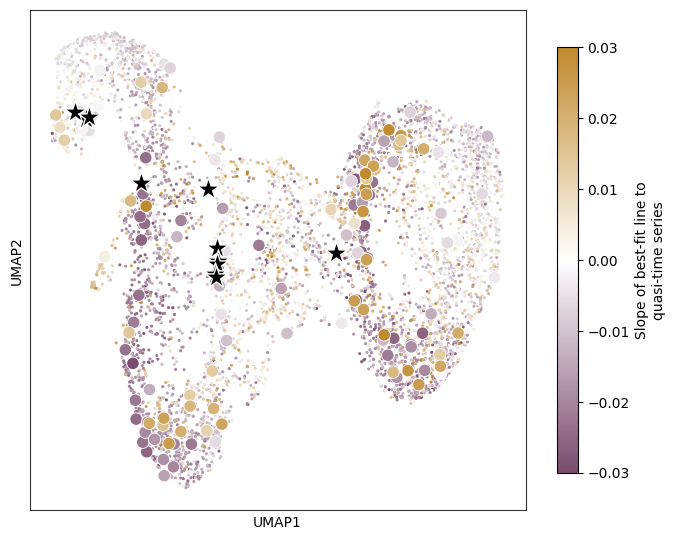

In [86]:
plot_umap_rejuvenative_stars(
    [i[0] for i in adata.obsm['X_umap']],
    [i[1] for i in adata.obsm['X_umap']],
    adata.obs.AgeScore.values,
    (adata.obs.IsRejuvenative>0).values,
    adata.obs.newpred.values,
    color_label="Slope of best-fit line to\nquasi-time series",
    vmin=-0.03,
    vmax=0.03,
    figsize=(8, 6.5),
    background_size=5,
    tested_size=80,
    star_size=280,
)
plt.savefig('./newfigures/N2VUmap.pdf',bbox_inches='tight')